In [1]:
%pip install imbalanced-learn xgboost statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


The implementation uses established Python packages for data handling, visualisation, statistical analysis, machine learning, class-imbalance handling and model explanation. The relevant official documentation is listed in the References cell at the end of this notebook (Joblib, n.d.; Matplotlib, n.d.; NumPy, n.d.; pandas, n.d.; SciPy, n.d.; scikit-learn, n.d.; Seaborn, n.d.; SHAP, n.d.; statsmodels, n.d.; imbalanced-learn, n.d.; XGBoost, n.d.). The core packages also have peer-reviewed or conference papers describing their design and use: pandas (McKinney, 2010), NumPy (Harris *et al*., 2020), Matplotlib (Hunter, 2007), Seaborn (Waskom, 2021), scikit-learn (Pedregosa *et al*., 2011), SciPy (Virtanen *et al*., 2020), statsmodels (Seabold and Perktold, 2010), and imbalanced-learn (Lemaître *et al*., 2017).

In [3]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

#Statistics
import scipy.stats as stats
from scipy.stats import wilcoxon, chi2_contingency
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import mcnemar

#Explainability
import shap

#Scikit-learn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                    GridSearchCV, cross_val_score, cross_val_predict)

#The three algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

#Evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                            roc_auc_score, average_precision_score, confusion_matrix,
                            ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                            RocCurveDisplay, PrecisionRecallDisplay, classification_report)

#Class imbalance
from imblearn.pipeline import Pipeline          # imblearn's Pipeline since it knows how to use SMOTE
from imblearn.over_sampling import SMOTE

from statsmodels.stats.multitest import multipletests

import sys, shutil
from importlib.metadata import version

# Settings we will use throughout the analysis 

Using a fixed random seed and saving intermediate outputs supports reproducibility, which is an important part of transparent computational research (Sandve *et al*., 2013).

In [4]:
Seed = 42                       # one seed everywhere gives us the same results every run
data_path = r"C:\Users\Lenovo\OneDrive\Desktop\datasets\BankChurners.csv"
decline_threshold = 0.8         # Total_Ct_Chng_Q4_Q1 below this counts as "declining"
test_size = 0.20

np.random.seed(Seed)

for folder in ["outputs/figures", "outputs/tables", "outputs/models"]:  # Creating folders to save outputs if they don't exist yet
    os.makedirs(folder, exist_ok=True)

def savefig(name):
    # saves the current chart as a PNG for the report, then shows it
    plt.tight_layout()
    plt.savefig(f"outputs/figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Load and Inspect The Data

In [5]:
df_raw = pd.read_csv(data_path)
print("Raw dataset shape:", df_raw.shape)
df_raw.head()

Raw dataset shape: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


## Identify the unnecessary columns

In [6]:
# Create an empty list to store the Naive Bayes columns
naive_bayes_cols = []

# Go through each column in the dataset
for column in df_raw.columns:

    # Check whether the column name starts with "Naive_Bayes"
    if column.startswith("Naive_Bayes"):
        naive_bayes_cols.append(column)

# Display the columns identified for removal
print("Naive Bayes columns:", naive_bayes_cols)

Naive Bayes columns: ['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']


# Clean the dataset and create the target variables

In [7]:
df = df_raw.copy()

# Remove the customer identification column
df = df.drop(columns="CLIENTNUM")

# Remove the Naive Bayes prediction columns
df = df.drop(columns=naive_bayes_cols)

# Create the churn column
df["churn"] = 0

# Assign 1 to customers who left the bank
df.loc[df["Attrition_Flag"] == "Attrited Customer", "churn"] = 1

# Remove the original text-based churn column
df = df.drop(columns="Attrition_Flag")

# Inspect the cleaned dataset

In [8]:
print("Clean dataset shape:", df.shape)

df.head()

Clean dataset shape: (10127, 20)


,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,churn
0,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0
1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0
2,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0
3,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0
4,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0


# Check data quality and churn distribution 

We will check for duplicate rows, missing values, and the distribution of the target variable.

Systematic data checks before modelling help identify duplicated records, missing values and other issues that can undermine the reliability of machine-learning results (Lones, 2024).

In [9]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for missing values
print("Total missing values:", df.isna().sum().sum())

# Count customers who stayed and customers who churned
print("\nChurn distribution:")
print(df["churn"].value_counts())

# Calculate the percentage of customers who churned
churn_rate = df["churn"].mean()

print("\nChurn rate:", f"{churn_rate:.2%}")

Duplicate rows: 0
Total missing values: 0

Churn distribution:
churn
0    8500
1    1627
Name: count, dtype: int64

Churn rate: 16.07%


# Inspect the categorical variables 

We will examine the unique categories in each categorical column and count how many records contain "Unknown"

In [10]:
categorical_columns = [
    "Gender",
    "Education_Level",
    "Marital_Status",
    "Income_Category",
    "Card_Category"
]

for column in categorical_columns:

    # Display the category counts
    print("Column:", column)
    print(df[column].value_counts().to_dict())

    # Count the number of Unknown values
    unknown_count = (df[column] == "Unknown").sum()

    print("Unknown values:", unknown_count)
    print()

Column: Gender
{'F': 5358, 'M': 4769}
Unknown values: 0

Column: Education_Level
{'Graduate': 3128, 'High School': 2013, 'Unknown': 1519, 'Uneducated': 1487, 'College': 1013, 'Post-Graduate': 516, 'Doctorate': 451}
Unknown values: 1519

Column: Marital_Status
{'Married': 4687, 'Single': 3943, 'Unknown': 749, 'Divorced': 748}
Unknown values: 749

Column: Income_Category
{'Less than $40K': 3561, '$40K - $60K': 1790, '$80K - $120K': 1535, '$60K - $80K': 1402, 'Unknown': 1112, '$120K +': 727}
Unknown values: 1112

Column: Card_Category
{'Blue': 9436, 'Silver': 555, 'Gold': 116, 'Platinum': 20}
Unknown values: 0



# Check the relationship between credit variables

We validate the consistency of the dataset by verifying that the recorded available credit values equal the difference between the credit limit and the balance. The .abs() function is used to measure the magnitude of any discrepancy regardless of whether the recorded value is higher or lower than expected, while .max() identifies the largest discrepancy across all customer records. If the maximum difference is zero, it confirms that the relationship holds exactly for every observation in the dataset.

In [11]:
# Calculate the available credit using the other two columns
calculated_open_to_buy = (
    df["Credit_Limit"] - df["Total_Revolving_Bal"]
)

# Calculate the difference between the calculated and recorded values
difference = (
    calculated_open_to_buy - df["Avg_Open_To_Buy"]
).abs()

# Find the largest difference
biggest_difference = difference.max()

# Display the result
print("Biggest difference:", biggest_difference)

Biggest difference: 5.684341886080802e-14


Since the largest absolute difference is effectively zero, any observed discrepancies can be attributed to floating-point precision limitations rather than actual inconsistencies in the data. This confirms that the relationship between available credit, credit limit, and balance holds across the entire dataset.

# Deciding what to do with "Unknown" variables

We retain "Unknown" as a distinct category rather than removing records or imputing values. This approach preserves a substantial portion of the dataset, avoids introducing potentially inaccurate assumptions, and allows the model to determine whether missingness itself carries predictive information. During preprocessing, one-hot encoding treats "Unknown" as a separate category, creating its own indicator variable automatically.


In [12]:
# The three columns that contain Unknown values
unknown_columns = ["Education_Level", "Marital_Status", "Income_Category"]

# Create an empty list to store one row of results per column
unknown_rows = []

for column in unknown_columns:

    # True for customers whose value in this column is "Unknown"
    is_unknown = df[column] == "Unknown"

    # Store the counts and churn rates for this column
    unknown_rows.append({
        "column": column,
        "unknown_count": int(is_unknown.sum()),
        "unknown_percent": is_unknown.mean() * 100,
        "churn_rate_unknown_percent": df.loc[is_unknown, "churn"].mean() * 100,
        "churn_rate_known_percent": df.loc[~is_unknown, "churn"].mean() * 100
    })

unknown_summary = pd.DataFrame(unknown_rows).round(2)
unknown_summary.to_csv("outputs/tables/unknown_summary.csv", index=False)

# How many customers have at least one Unknown value
any_unknown = (df[unknown_columns] == "Unknown").any(axis=1)
print("Customers with at least one Unknown:", any_unknown.sum(), f"({any_unknown.mean():.1%})")
print("Churn rate with an Unknown:", f"{df.loc[any_unknown, 'churn'].mean():.2%}")
print("Churn rate without an Unknown:", f"{df.loc[~any_unknown, 'churn'].mean():.2%}")

Customers with at least one Unknown: 3046 (30.1%)
Churn rate with an Unknown: 16.87%
Churn rate without an Unknown: 15.72%


# Exploratory Data Analysis

## Class balance

Class imbalance is relevant to both model training and evaluation: resampling and class-weighting methods are commonly used to address it, while precision–recall analysis can be informative when the positive class is relatively uncommon (Lemaître *et al*., 2017; Saito and Rehmsmeier, 2015).

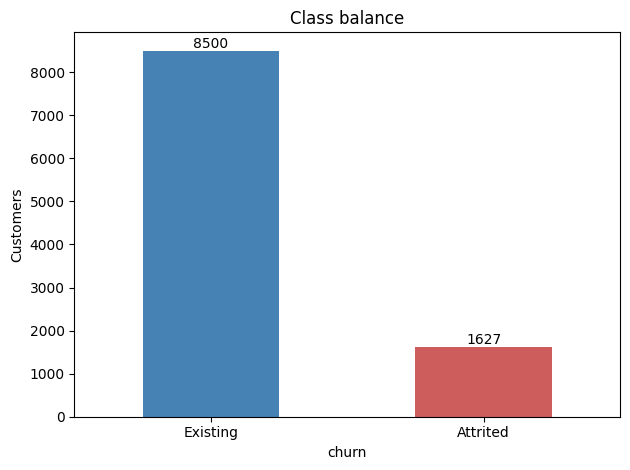

In [13]:
# Count the customers in each class and give the classes readable names
class_counts = df["churn"].map({0: "Existing", 1: "Attrited"}).value_counts()

# Draw a bar chart of the counts
ax = class_counts.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Class balance")
plt.ylabel("Customers")
plt.xticks(rotation=0)

# Write the exact count on top of each bar
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height())}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

savefig("01_class_balance")

## Numeric variables: Churners vs Non-Churners

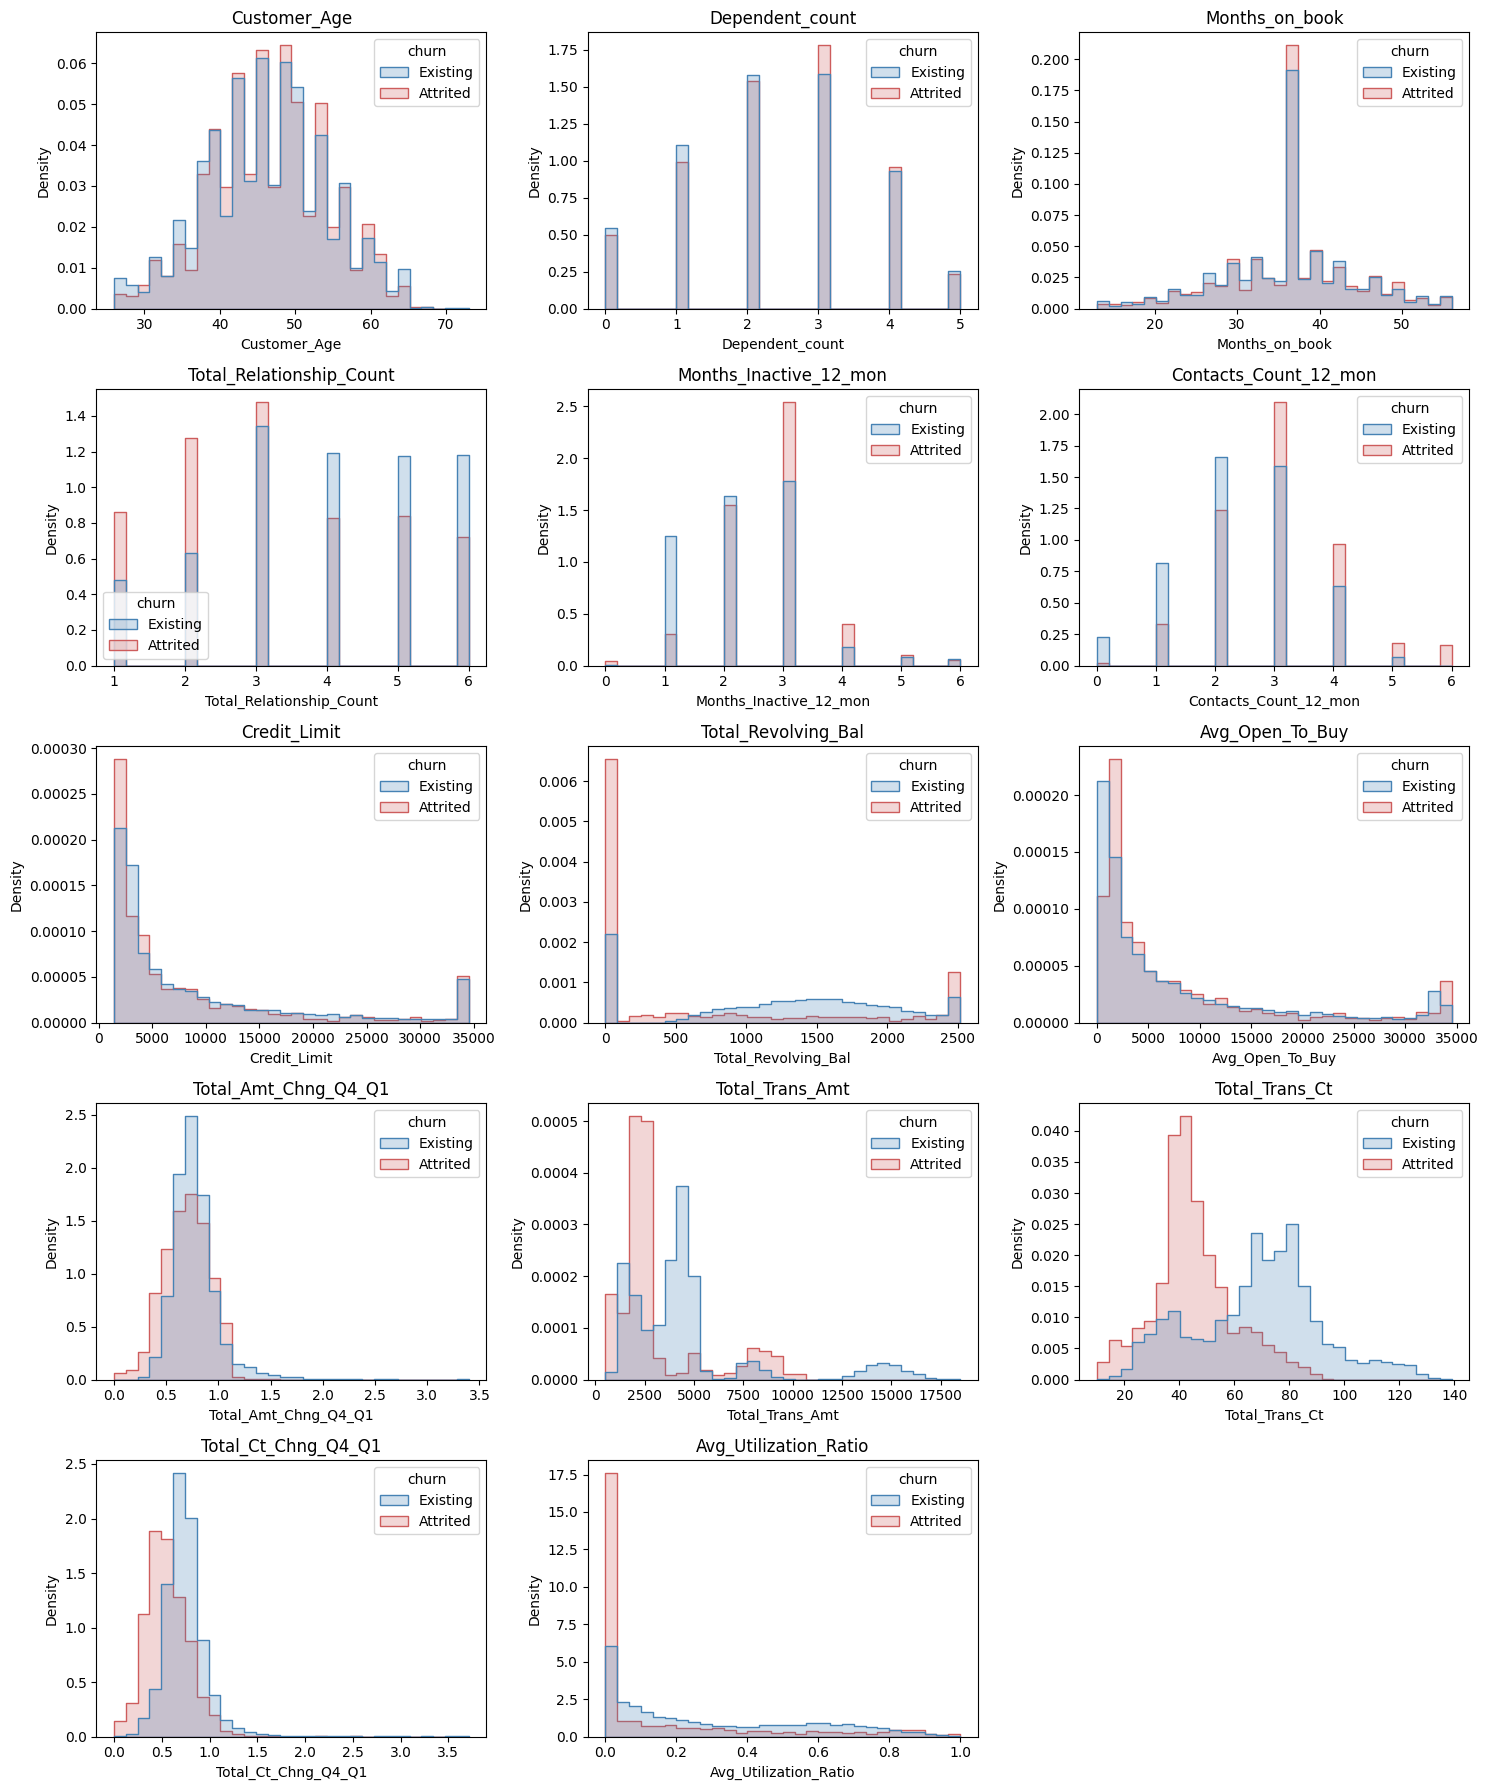

In [14]:
# The numeric columns we want to compare
numeric_columns = [
    "Customer_Age", "Dependent_count", "Months_on_book", "Total_Relationship_Count",
    "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Credit_Limit", "Total_Revolving_Bal",
    "Avg_Open_To_Buy", "Total_Amt_Chng_Q4_Q1", "Total_Trans_Amt", "Total_Trans_Ct",
    "Total_Ct_Chng_Q4_Q1", "Avg_Utilization_Ratio"
]

# Readable labels for the colours in the charts
churn_label = df["churn"].map({0: "Existing", 1: "Attrited"})

# Create a grid of 5 rows x 3 columns of charts
fig, axes = plt.subplots(5, 3, figsize=(15, 18))
axes = axes.ravel()

for i, column in enumerate(numeric_columns):

    # Draw one histogram per numeric column, split by churn
    sns.histplot(
        data=df,
        x=column,
        hue=churn_label,
        stat="density",
        common_norm=False,
        element="step",
        bins=30,
        ax=axes[i],
        palette={"Existing": "steelblue", "Attrited": "indianred"}
    )
    axes[i].set_title(column)

# Hide the unused 15th chart box
axes[14].set_visible(False)

savefig("02_numeric_distributions_by_churn")

## Outliers: before vs after capping

This step is performed solely to illustrate the effect of capping values at the 1st and 99th percentiles. The actual outlier treatment will be implemented within the preprocessing pipeline, where the percentile thresholds will be calculated using the training data only. This approach prevents data leakage and ensures that information from the test set does not influence the model-building process.

The capping thresholds are learned within the modelling pipeline from training data only, rather than from the full dataset, to reduce the risk of information leakage (Sasse *et al*., 2025; Lones, 2024).

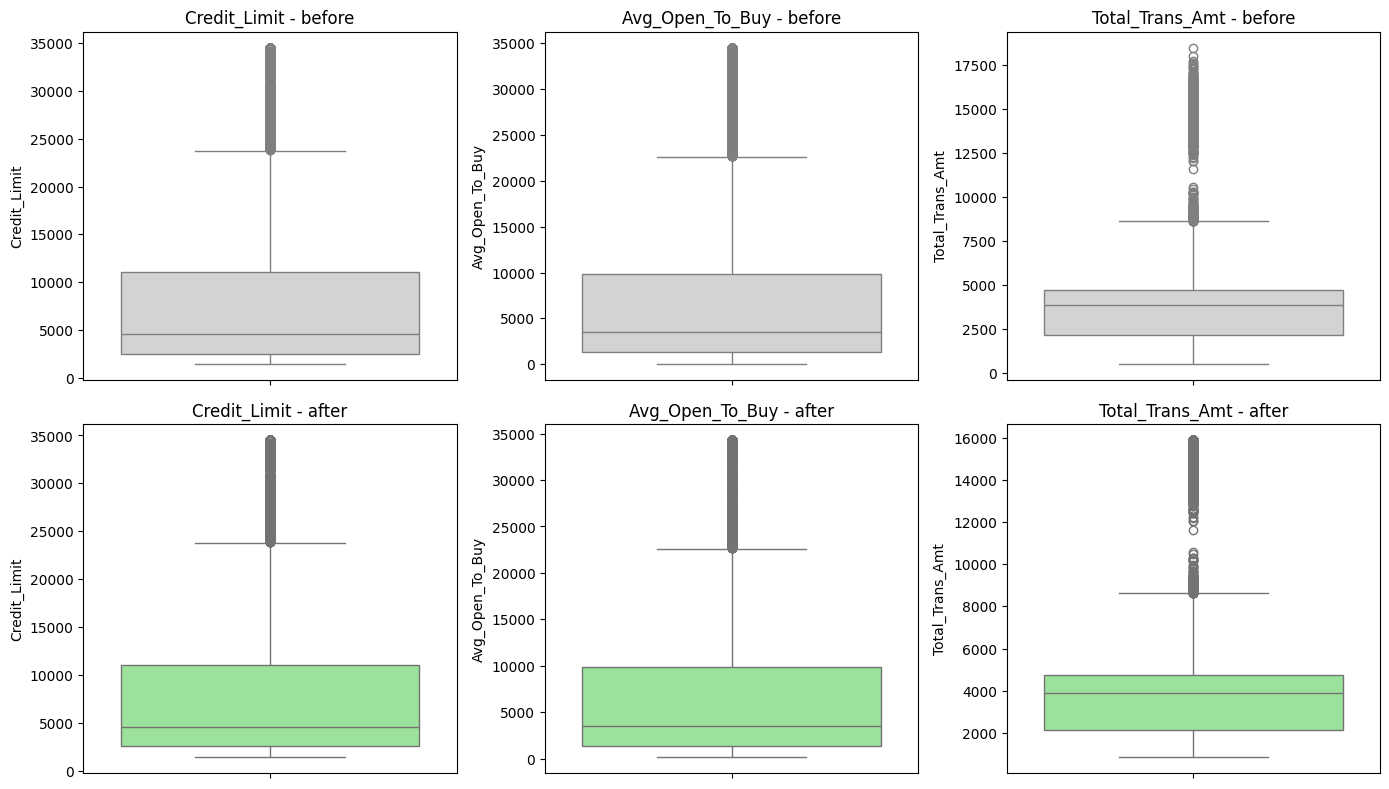

In [15]:
# The columns we plan to cap
winsor_columns = ["Credit_Limit", "Avg_Open_To_Buy", "Total_Trans_Amt"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for j, column in enumerate(winsor_columns):

    # Calculate the 1st and 99th percentile values
    low = df[column].quantile(0.01)
    high = df[column].quantile(0.99)

    # Top row: the original column
    sns.boxplot(y=df[column], ax=axes[0, j], color="lightgray")
    axes[0, j].set_title(column + " - before")

    # Bottom row: the column after capping
    sns.boxplot(y=df[column].clip(low, high), ax=axes[1, j], color="lightgreen")
    axes[1, j].set_title(column + " - after")

savefig("03_winsorization_before_after")

## Correlations

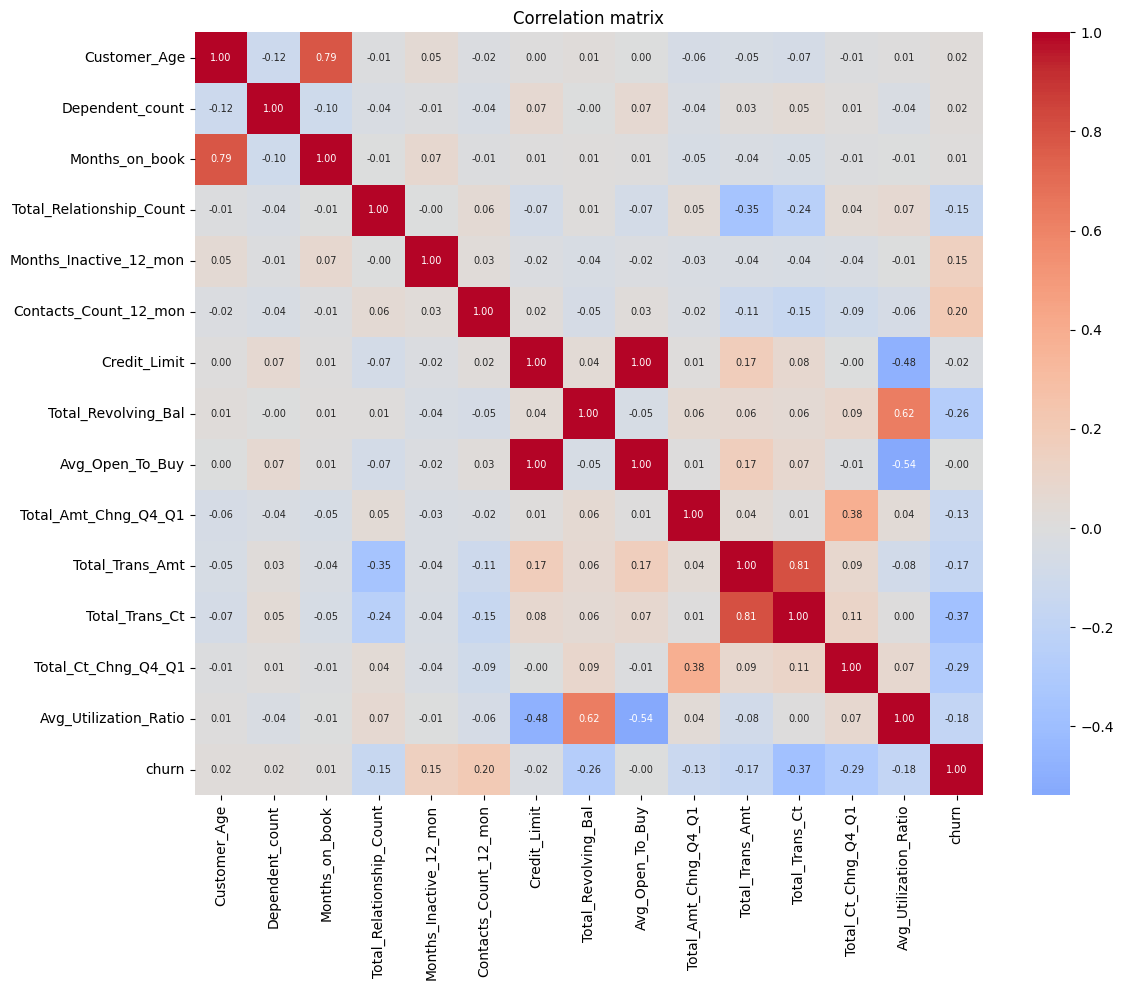

Correlation with churn:
Total_Trans_Ct             -0.371403
Total_Ct_Chng_Q4_Q1        -0.290054
Total_Revolving_Bal        -0.263053
Avg_Utilization_Ratio      -0.178410
Total_Trans_Amt            -0.168598
Total_Relationship_Count   -0.150005
Total_Amt_Chng_Q4_Q1       -0.131063
Credit_Limit               -0.023873
Avg_Open_To_Buy            -0.000285
Months_on_book              0.013687
Customer_Age                0.018203
Dependent_count             0.018991
Months_Inactive_12_mon      0.152449
Contacts_Count_12_mon       0.204491
Name: churn, dtype: float64


In [16]:
# Correlation between every numeric column and churn
correlation = df[numeric_columns + ["churn"]].corr()

# Draw the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix")
savefig("04_correlation_heatmap")

# Show how strongly each variable relates to churn (most negative to most positive)
print("Correlation with churn:")
print(correlation["churn"].drop("churn").sort_values())

## Redundancy between columns (VIF)

VIF measures how strongly a predictor is linearly explained by the other predictors. A value around 10 is sometimes used as a warning threshold, but it should not be treated as an automatic rule for removing variables; VIF values need to be interpreted in the context of the model and the research objective (O’Brien, 2007). Extremely large values here are consistent with the near-deterministic relationship among the three credit columns checked earlier.

In [17]:
# Standardise the numeric columns so they are on the same scale
standardised = (df[numeric_columns] - df[numeric_columns].mean()) / df[numeric_columns].std()

# VIF needs a constant column of 1s at the front
standardised.insert(0, "const", 1.0)

# Calculate the VIF for each numeric column (skipping the constant)
vif_values = []
with np.errstate(divide="ignore", invalid="ignore"):
    for i in range(1, standardised.shape[1]):
        vif_values.append(variance_inflation_factor(standardised.values, i))

# Put the results in a table, largest first
vif_table = pd.Series(vif_values, index=numeric_columns).sort_values(ascending=False)
vif_table.to_csv("outputs/tables/vif.csv", header=["VIF"])
vif_table

Total_Revolving_Bal              inf
Credit_Limit                     inf
Avg_Open_To_Buy                  inf
Total_Trans_Amt             3.263320
Total_Trans_Ct              3.024481
Avg_Utilization_Ratio       2.900014
Customer_Age                2.675596
Months_on_book              2.658376
Total_Ct_Chng_Q4_Q1         1.208277
Total_Amt_Chng_Q4_Q1        1.192111
Total_Relationship_Count    1.155622
Contacts_Count_12_mon       1.037201
Dependent_count             1.028368
Months_Inactive_12_mon      1.011255
dtype: float64

## Categorical variables: churn rate per group

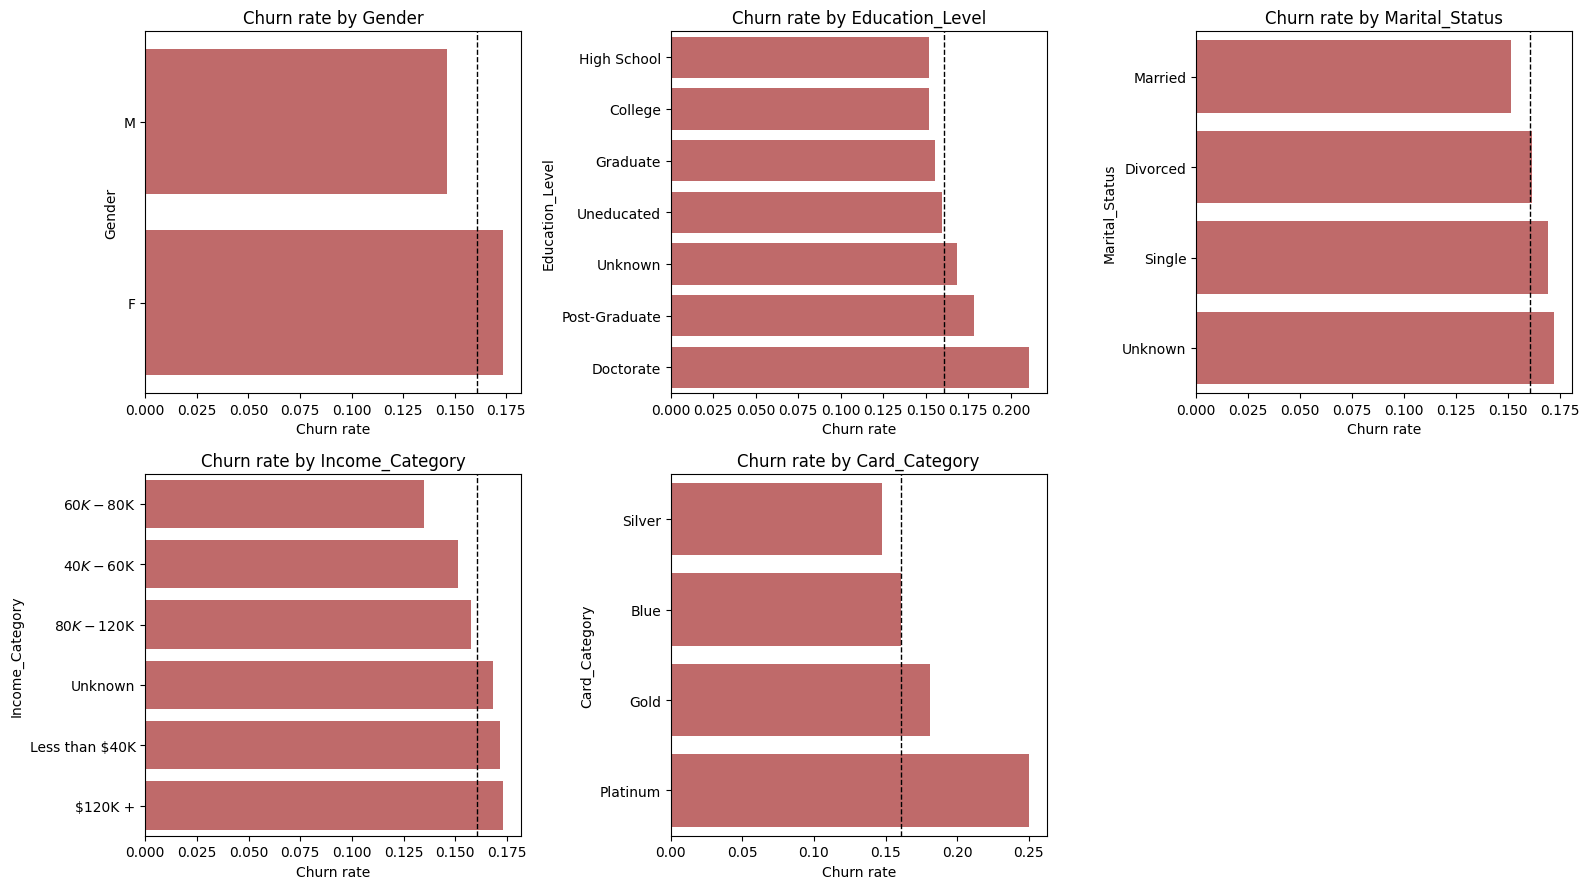

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for i, column in enumerate(categorical_columns):

    # Churn rate for each category, sorted from lowest to highest
    rate = df.groupby(column)["churn"].mean().sort_values()

    sns.barplot(x=rate.values, y=rate.index, ax=axes[i], color="indianred")

    # Dashed line = overall churn rate
    axes[i].axvline(df["churn"].mean(), color="black", linestyle="--", linewidth=1)
    axes[i].set_title("Churn rate by " + column)
    axes[i].set_xlabel("Churn rate")

# Hide the unused 6th chart box
axes[5].set_visible(False)

savefig("05_churn_by_category")

## Behavioural Feature Engineering

Behavioural feature engineering transforms existing customer information into variables that capture patterns in customer activity and changes in behaviour. Research on financial churn prediction demonstrates that behavioural and temporal patterns can provide useful predictive information beyond conventional customer characteristics (Kaya et al., 2018).

To capture changes in customer behaviour over time, we engineer two additional features:

- `declining_transactions`: identifies customers whose transaction volume decreased by more than 20% between Q1 and Q4.
- `inactivity_ratio`: measures the proportion of a customer's relationship with the bank that has been spent inactive.

These features complement the existing activity measures by focusing on behavioural trends rather than current activity levels alone. In particular, they capture signs of declining engagement, which may serve as early indicators of churn risk.

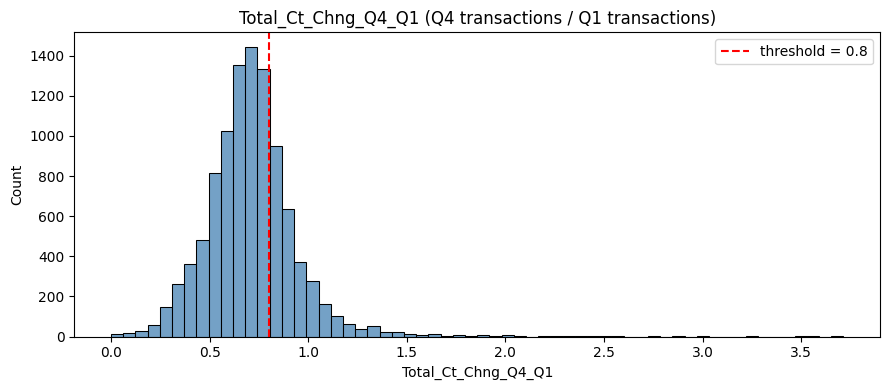

count    10127.000000
mean         0.712222
std          0.238086
min          0.000000
25%          0.582000
50%          0.702000
75%          0.818000
max          3.714000
Name: Total_Ct_Chng_Q4_Q1, dtype: float64

Share of customers below 0.6: 27.7%
Share of customers below 0.7: 49.4%
Share of customers below 0.8: 71.1%
Share of customers below 0.9: 85.4%


In [19]:
# Distribution of the quarterly transaction change, with the threshold marked
plt.figure(figsize=(9, 4))
sns.histplot(df["Total_Ct_Chng_Q4_Q1"], bins=60, color="steelblue")
plt.axvline(decline_threshold, color="red", linestyle="--", label="threshold = " + str(decline_threshold))
plt.legend()
plt.title("Total_Ct_Chng_Q4_Q1 (Q4 transactions / Q1 transactions)")
savefig("06_ct_change_distribution")

# Summary statistics
print(df["Total_Ct_Chng_Q4_Q1"].describe())
print()

# What share of customers would be flagged at different thresholds?
for threshold in [0.6, 0.7, 0.8, 0.9]:
    share = (df["Total_Ct_Chng_Q4_Q1"] < threshold).mean()
    print(f"Share of customers below {threshold}: {share:.1%}")

In [20]:
# declining_transactions: 1 if the transaction count fell below the threshold, otherwise 0
df["declining_transactions"] = (df["Total_Ct_Chng_Q4_Q1"] < decline_threshold).astype(int)

# inactivity_ratio: inactive months compared with how long the customer has been with the bank
df["inactivity_ratio"] = df["Months_Inactive_12_mon"] / df["Months_on_book"]

# Check the new columns
print(df[["declining_transactions", "inactivity_ratio"]].describe())

# Churn rate for declining vs not declining customers
print()
print("Churn rate by declining_transactions:")
print(df.groupby("declining_transactions")["churn"].agg(["mean", "count"]))

       declining_transactions  inactivity_ratio
count            10127.000000      10127.000000
mean                 0.710773          0.068603
std                  0.453426          0.034500
min                  0.000000          0.000000
25%                  0.000000          0.045455
50%                  1.000000          0.065217
75%                  1.000000          0.083333
max                  1.000000          0.461538

Churn rate by declining_transactions:
                           mean  count
declining_transactions                
0                       0.07477   2929
1                       0.19561   7198


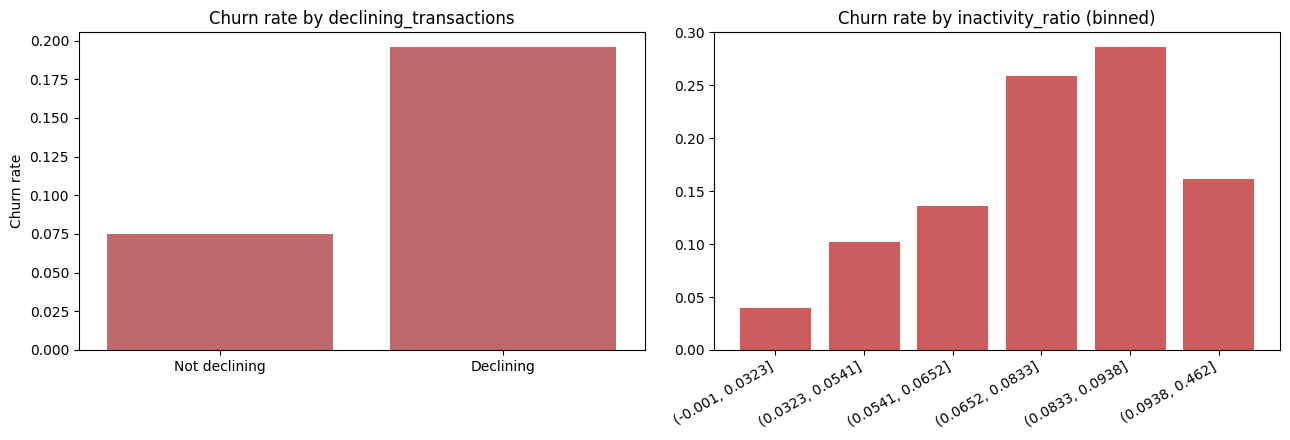

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left chart: churn rate for declining vs not declining
rate_declining = df.groupby("declining_transactions")["churn"].mean()
sns.barplot(x=["Not declining", "Declining"], y=rate_declining.values, ax=axes[0], color="indianred")
axes[0].set_title("Churn rate by declining_transactions")
axes[0].set_ylabel("Churn rate")

# Right chart: split inactivity_ratio into 6 equal-sized groups and show the churn rate of each
ratio_groups = pd.qcut(df["inactivity_ratio"], q=6, duplicates="drop")
rate_ratio = df.groupby(ratio_groups, observed=True)["churn"].mean()
axes[1].bar(range(len(rate_ratio)), rate_ratio.values, color="indianred")
axes[1].set_xticks(range(len(rate_ratio)))
axes[1].set_xticklabels([str(group) for group in rate_ratio.index], rotation=30, ha="right")
axes[1].set_title("Churn rate by inactivity_ratio (binned)")

savefig("07_trajectory_features_vs_churn")

## Defining Model A and Model B

To evaluate whether changes in customer behaviour improve churn prediction, two feature sets are defined:

- **Model A (static):** consists of 17 features describing customers at a single point in time, with no information about how behaviour changes over time.
- **Model B (trajectory-augmented):** contains the same 17 features as Model A, together with 4 additional trajectory features, giving a total of 21 features.

The comparison between these two models forms the basis of the study. If Model B consistently outperforms Model A, it would suggest that behavioural changes over time provide additional predictive information for identifying customers at risk of churn.

In [22]:
# Model A: the static features
static_features = [
    # Demographic
    "Customer_Age", "Gender", "Dependent_count", "Education_Level", "Marital_Status", "Income_Category",
    # Account
    "Months_on_book", "Total_Relationship_Count", "Card_Category",
    # Financial
    "Credit_Limit", "Total_Revolving_Bal", "Avg_Open_To_Buy", "Avg_Utilization_Ratio",
    # Behavioural (static)
    "Total_Trans_Amt", "Total_Trans_Ct", "Months_Inactive_12_mon", "Contacts_Count_12_mon"
]

# The extra information Model B receives
trajectory_features = [
    "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1",
    "declining_transactions", "inactivity_ratio"
]

# Model A uses the static features, Model B uses static + trajectory
features_a = static_features
features_b = static_features + trajectory_features
feature_sets = {"A": features_a, "B": features_b}

print("Model A:", len(features_a), "features")
print("Model B:", len(features_b), "features")
print("Extra features in B:", trajectory_features)

Model A: 17 features
Model B: 21 features
Extra features in B: ['Total_Ct_Chng_Q4_Q1', 'Total_Amt_Chng_Q4_Q1', 'declining_transactions', 'inactivity_ratio']


## Train-Test Split

We split the data into 80% training and 20% testing. **Stratified** means both sets keep the same churn rate (about 16%). From here on, the test set is locked away until the very end, so nothing before final evaluation looks at it.

Keeping the test set separate from feature preparation and model selection is important because information leakage can produce overly optimistic estimates of generalisation performance (Sasse *et al*., 2025).

In [23]:
# x holds all 21 columns. Model A will simply use 17 of them.
x = df[features_b]
y = df["churn"]

# Split into train and test, keeping the same churn rate in both
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=test_size,
    stratify=y,
    random_state=Seed
)

print("Train:", x_train.shape, f"churn rate {y_train.mean():.2%}")
print("Test: ", x_test.shape, f"churn rate {y_test.mean():.2%}")

Train: (8101, 21) churn rate 16.07%
Test:  (2026, 21) churn rate 16.04%


## Building the Pipelines

A **pipeline** is a structured sequence of preprocessing and modelling steps that are applied in a fixed order:

**outlier capping → categorical encoding → feature scaling (logistic regression only) → SMOTE → model fitting**

An imbalanced-learn pipeline combines preprocessing, resampling and model fitting into a single workflow. Placing resampling within the pipeline allows it to be applied during model fitting rather than indiscriminately to the complete dataset, helping prevent information leakage during cross-validation (Lemaître, Nogueira and Aridas, 2017; imbalanced-learn, n.d.).

SMOTE creates synthetic minority-class examples and should be applied only to the training portion of each pipeline fit (Chawla *et al*., 2002). Keeping learned preprocessing and resampling inside the pipeline also helps prevent leakage across validation folds (Sasse *et al*., 2025).

By encapsulating all preprocessing and modelling steps within a single pipeline, the workflow remains reproducible and enables a fair comparison between different algorithms and feature sets.

## The Outlier Capper (Winsorizer)

To reduce the influence of extreme values, numerical features are capped at the **1st and 99th percentiles**. Rather than removing observations, winsorization limits extreme values to these percentile thresholds, preserving all records while reducing the impact of outliers on model training.

The percentile thresholds are calculated using the **training data only** and are then applied to validation and test data. This prevents information leakage and ensures that the preprocessing procedure reflects how the model would operate on unseen data.

The winsorization process is implemented as a custom transformer so that it can be incorporated directly into the pipeline and applied consistently during cross-validation and final model evaluation.

In [24]:
class Winsorizer(BaseEstimator, TransformerMixin):

    def __init__(self, columns=None, lower=0.01, upper=0.99):
        # Store the settings
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        # Learn the cap values from the data we are fitting on
        self.bounds_ = {}
        for column in self.columns:
            if column in X.columns:
                low = X[column].quantile(self.lower)
                high = X[column].quantile(self.upper)
                self.bounds_[column] = (low, high)
        return self

    def transform(self, X):
        # Apply the learned cap values to whatever data comes in
        X = X.copy()
        for column, (low, high) in self.bounds_.items():
            X[column] = X[column].clip(low, high)
        return X

## The pipeline builder

In [25]:
def build_preprocessor(features, scale):

    # Text columns will become 0/1 dummy columns
    categorical = []
    for column in categorical_columns:
        if column in features:
            categorical.append(column)

    # Everything else is numeric
    numeric = []
    for column in features:
        if column not in categorical:
            numeric.append(column)

    # Only logistic regression needs scaled numbers
    if scale:
        numeric_step = StandardScaler()
    else:
        numeric_step = "passthrough"

    return ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical),
        ("num", numeric_step, numeric)
    ])


def build_model(model_name):

    if model_name == "logreg":
        return LogisticRegression(max_iter=5000, random_state=Seed)

    if model_name == "tree":
        return DecisionTreeClassifier(random_state=Seed)

    if model_name == "xgboost":
        # n_jobs=1 on purpose: GridSearchCV already runs many fits in parallel
        # scale_pos_weight stays at 1 because SMOTE already balances the classes
        return XGBClassifier(
            eval_metric="logloss",
            random_state=Seed,
            tree_method="hist",
            n_jobs=1,
            scale_pos_weight=1
        )


def build_pipeline(model_name, feature_set):

    # Pick Model A's or Model B's columns
    features = feature_sets[feature_set]

    return Pipeline([
        ("winsor", Winsorizer(columns=winsor_columns)),
        ("prep", build_preprocessor(features, scale=(model_name == "logreg"))),
        ("smote", SMOTE(random_state=Seed)),
        ("model", build_model(model_name))
    ])

## A check to see what our models actually receive 

In [26]:
for feature_set in ["A", "B"]:

    # Build a pipeline and run only its first 2 steps (cap + encode)
    pipe = build_pipeline("xgboost", feature_set)
    columns_used = feature_sets[feature_set]
    pipe[:2].fit(x_train[columns_used], y_train)

    # List the columns that come out the other side
    names = pipe.named_steps["prep"].get_feature_names_out()
    print(f"Model {feature_set}: {len(columns_used)} raw columns became {len(names)} columns after encoding")

print()
print(list(names))

Model A: 17 raw columns became 30 columns after encoding
Model B: 21 raw columns became 34 columns after encoding

['cat__Gender_M', 'cat__Education_Level_Doctorate', 'cat__Education_Level_Graduate', 'cat__Education_Level_High School', 'cat__Education_Level_Post-Graduate', 'cat__Education_Level_Uneducated', 'cat__Education_Level_Unknown', 'cat__Marital_Status_Married', 'cat__Marital_Status_Single', 'cat__Marital_Status_Unknown', 'cat__Income_Category_$40K - $60K', 'cat__Income_Category_$60K - $80K', 'cat__Income_Category_$80K - $120K', 'cat__Income_Category_Less than $40K', 'cat__Income_Category_Unknown', 'cat__Card_Category_Gold', 'cat__Card_Category_Platinum', 'cat__Card_Category_Silver', 'num__Customer_Age', 'num__Dependent_count', 'num__Months_on_book', 'num__Total_Relationship_Count', 'num__Credit_Limit', 'num__Total_Revolving_Bal', 'num__Avg_Open_To_Buy', 'num__Avg_Utilization_Ratio', 'num__Total_Trans_Amt', 'num__Total_Trans_Ct', 'num__Months_Inactive_12_mon', 'num__Contacts_Cou

## Smoke Test

A smoke test is a preliminary test of essential functionality performed before more extensive testing. In a machine-learning workflow, a smoke test can be implemented by running a small, representative subset of the pipeline to check that the data preparation, feature transformations, model fitting and prediction stages execute successfully (MDN Web Docs, n.d.).

By running the complete workflow on a small sample of data, the smoke test confirms that the pipeline executes without errors and produces valid outputs. Detecting implementation issues at this stage provides confidence that the system is functioning as intended before proceeding to computationally intensive model tuning and formal performance evaluation.

In [27]:
# Create an empty list to store one row of results per pipeline
smoke_rows = []

for model_name in ["logreg", "tree", "xgboost"]:
    for feature_set in ["A", "B"]:

        start_time = time.time()

        # 5-fold cross-validation on the training set
        scores = cross_val_score(
            build_pipeline(model_name, feature_set),
            x_train[feature_sets[feature_set]],
            y_train,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=Seed),
            scoring="roc_auc",
            n_jobs=-1
        )

        smoke_rows.append({
            "model": model_name,
            "features": feature_set,
            "cv_auc_mean": scores.mean(),
            "cv_auc_std": scores.std(),
            "seconds": round(time.time() - start_time, 1)
        })

smoke_test = pd.DataFrame(smoke_rows)
smoke_test.to_csv("outputs/tables/smoke_test_default_cv_auc.csv", index=False)
smoke_test

,model,features,cv_auc_mean,cv_auc_std,seconds
0,logreg,A,0.913903,0.009991,31.3
1,logreg,B,0.926783,0.008034,11.7
2,tree,A,0.864328,0.016301,1.0
3,tree,B,0.880862,0.012237,1.0
4,xgboost,A,0.985933,0.002022,3.6
5,xgboost,B,0.992781,0.001482,3.7


## Hyperparameter Tuning

Each machine learning algorithm contains **hyperparameters** that control how the model learns from the data. Examples include the regularization strength in logistic regression, the maximum depth of a decision tree, and the number of estimators in XGBoost. Because these settings can have a substantial impact on predictive performance, hyperparameter tuning is used to identify the most effective configuration.

The search grids defined in the methodology are shown below:

| Model | Combinations | Fits per feature set (5-fold CV) |
|--------|-------------|----------------------------------|
| Logistic Regression | 16 | 80 |
| Decision Tree | 160 | 800 |
| XGBoost | 432 | 2,160 |

Hyperparameter tuning is performed separately for **Model A** and **Model B** using cross-validation. For each candidate configuration, the model is trained and evaluated across multiple folds, and the combination that achieves the strongest performance is selected.

Model selection and hyperparameter tuning can produce optimistic performance estimates when the same validation evidence is used repeatedly to choose among configurations, so the final results are interpreted with this limitation in mind (Cawley and Talbot, 2010; Lones, 2024).

## Define the grids

A hyperparameter grid defines candidate values for the parameters being optimised. Grid search evaluates the specified combinations using cross-validation and selects the combination that performs best according to the chosen scoring metric (scikit-learn, n.d.-b).

In [28]:
param_grids = {
    "logreg": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__penalty": ["l1", "l2"],
        "model__solver": ["liblinear", "saga"]
    },
    "tree": {
        "model__max_depth": [3, 5, 7, 10, 15],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__criterion": ["gini", "entropy"]
    },
    "xgboost": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 5, 7, 9],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__subsample": [0.6, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0]
    }
}

# Tiny grids used only to check that the code runs
quick_param_grids = {
    "logreg": {"model__C": [1.0], "model__penalty": ["l2"], "model__solver": ["liblinear"]},
    "tree": {"model__max_depth": [5]},
    "xgboost": {"model__n_estimators": [50], "model__max_depth": [3]}
}

## Hyperparameter Search Function

GridSearchCV automates hyperparameter optimisation by evaluating the specified parameter combinations across cross-validation folds. The selected configuration is determined by the scoring criterion supplied to the search procedure (scikit-learn, n.d.-b).

This approach ensures that model selection is based on objective performance rather than manual trial and error. The configuration that achieves the highest cross-validation score is retained as the optimal set of hyperparameters.


In [29]:
quick_run = False       

if quick_run:
    grids_to_use = quick_param_grids
    file_tag = "quick_"
else:
    grids_to_use = param_grids
    file_tag = ""


def run_search(model_name, feature_set):

    name = model_name + "_" + feature_set
    path = "outputs/models/search_" + file_tag + name + ".joblib"

    # If this search was already saved, skip it
    if os.path.exists(path):
        print(f"[skip] {name} is already saved")
        return

    # Count how many combinations will be tried
    combinations = 1
    for values in grids_to_use[model_name].values():
        combinations = combinations * len(values)
    print(f"[start] {name}: {combinations} combinations x 5 folds = {combinations * 5} fits", flush=True)

    # Set up the search
    search = GridSearchCV(
        build_pipeline(model_name, feature_set),
        param_grid=grids_to_use[model_name],
        scoring="roc_auc",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=Seed),
        n_jobs=-1,
        refit=True
    )

    # Run it on the training data only (the test set is not used)
    start_time = time.time()
    search.fit(x_train[feature_sets[feature_set]], y_train)

    # Save the finished search to disk
    joblib.dump(search, path)

    minutes = (time.time() - start_time) / 60
    print(f"[done]  {name}: best CV ROC-AUC = {search.best_score_:.4f} ({minutes:.1f} min)")
    print(f"        best settings: {search.best_params_}")
    print()

## Run the searches 

In [30]:
# Logistic regression
for feature_set in ["A", "B"]:
    run_search("logreg", feature_set)

[skip] logreg_A is already saved
[skip] logreg_B is already saved


In [31]:
# Decision tree 
for feature_set in ["A", "B"]:
    run_search("tree", feature_set)

[skip] tree_A is already saved
[skip] tree_B is already saved


In [32]:
# XGBoost 
for feature_set in ["A", "B"]:
    run_search("xgboost", feature_set)

[skip] xgboost_A is already saved
[skip] xgboost_B is already saved


In [33]:
# Create an empty list to store one row per saved search
summary_rows = []

for model_name in ["logreg", "tree", "xgboost"]:
    for feature_set in ["A", "B"]:

        # Load the saved search from disk
        search = joblib.load("outputs/models/search_" + file_tag + model_name + "_" + feature_set + ".joblib")

        summary_rows.append({
            "model": model_name,
            "features": feature_set,
            "best_cv_auc": search.best_score_,
            "best_params": search.best_params_
        })

tuning_summary = pd.DataFrame(summary_rows)
tuning_summary.to_csv("outputs/tables/" + file_tag + "tuning_summary.csv", index=False)

# Show the full text of the best settings
pd.set_option("display.max_colwidth", None)
tuning_summary

,model,features,best_cv_auc,best_params
0,logreg,A,0.914331,"{'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'saga'}"
1,logreg,B,0.927452,"{'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'saga'}"
2,tree,A,0.950569,"{'model__criterion': 'entropy', 'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 20}"
3,tree,B,0.955934,"{'model__criterion': 'gini', 'model__max_depth': 7, 'model__min_samples_leaf': 8, 'model__min_samples_split': 20}"
4,xgboost,A,0.987302,"{'model__colsample_bytree': 0.6, 'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 1.0}"
5,xgboost,B,0.993638,"{'model__colsample_bytree': 1.0, 'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 1.0}"


In [34]:
# A vs B side by side for each model (cross-validation on the training set)
comparison = tuning_summary.pivot(index="model", columns="features", values="best_cv_auc")
comparison["B_minus_A"] = comparison["B"] - comparison["A"]
comparison

features,A,B,B_minus_A
model,,,
logreg,0.914331,0.927452,0.013121
tree,0.950569,0.955934,0.005365
xgboost,0.987302,0.993638,0.006337


In [35]:
# Load the 6 saved searches into one dictionary
searches = {}

for model_name in ["logreg", "tree", "xgboost"]:
    for feature_set in ["A", "B"]:
        path = "outputs/models/search_" + file_tag + model_name + "_" + feature_set + ".joblib"
        searches[model_name + "_" + feature_set] = joblib.load(path)

print("Loaded:", list(searches.keys()))

Loaded: ['logreg_A', 'logreg_B', 'tree_A', 'tree_B', 'xgboost_A', 'xgboost_B']


We will now look at the tuning results in more detail

In [36]:
for name, search in searches.items():

    # Every combination that was tried, best first
    cv_table = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")

    # Save the full table
    cv_table.to_csv("outputs/tables/" + file_tag + "cv_results_" + name + ".csv", index=False)

    # Show the top 5
    print("=====", name, "=====")
    print(cv_table[["mean_test_score", "std_test_score", "params"]].head(5).to_string(index=False))
    print()

===== logreg_A =====
 mean_test_score  std_test_score                                                                  params
        0.914331        0.009559      {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'saga'}
        0.914267        0.009728 {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
        0.914082        0.010045 {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
        0.914072        0.009926      {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'saga'}
        0.913945        0.009939 {'model__C': 1.0, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

===== logreg_B =====
 mean_test_score  std_test_score                                                                  params
        0.927452        0.007480      {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'saga'}
        0.927392        0.007544 {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
        0.92

## Hyperparameter Tuning Results

The hyperparameter search results indicate a consistent performance advantage for **Model B** across all three algorithms. For logistic regression, Model B achieves a mean cross-validation score of approximately **0.927**, compared with **0.914** for Model A. The optimal configurations for both models favour relatively strong regularisation (`C = 0.1`) and L1 penalties, suggesting that feature selection remains beneficial despite the addition of trajectory variables.

A similar pattern is observed for the decision tree models, where Model B achieves a mean score of approximately **0.956**, exceeding Model A's **0.951**. The best-performing configurations favour the Gini impurity criterion, moderate tree depths, and larger minimum leaf sizes, indicating that some constraint on model complexity improves generalisation.

The largest improvement is observed for XGBoost. Model B achieves a mean cross-validation score of approximately **0.994**, compared with **0.987** for Model A. The optimal configurations generally favour higher learning rates and relatively shallow trees, allowing the ensemble to capture complex patterns while limiting overfitting.

Across all algorithms, the standard deviations of the cross-validation scores are low, indicating stable performance across folds. Overall, the tuning results provide preliminary evidence that incorporating trajectory features improves predictive performance. However, these cross-validation results alone are not sufficient to confirm **H1**, and formal statistical comparisons are required to determine whether the observed improvements are statistically significant.

### Purpose of the Visualization

This visualization compares the **top 20 hyperparameter configurations** identified during the tuning process for each algorithm (logistic regression, decision tree, and XGBoost) under both **Model A** and **Model B**. The configurations are ranked according to their mean cross-validation ROC-AUC scores, enabling a direct comparison of predictive performance across the two feature sets.

By displaying the highest-performing configurations rather than only the single best model, the plots provide insight into the overall performance landscape of each algorithm. They help assess whether the performance advantage of one feature set is consistent across multiple hyperparameter combinations or limited to a small number of configurations.

The visualisation also provides an indication of result stability. Closely clustered scores suggest that performance is relatively insensitive to the choice of hyperparameters, whereas larger differences indicate greater dependence on model configuration.

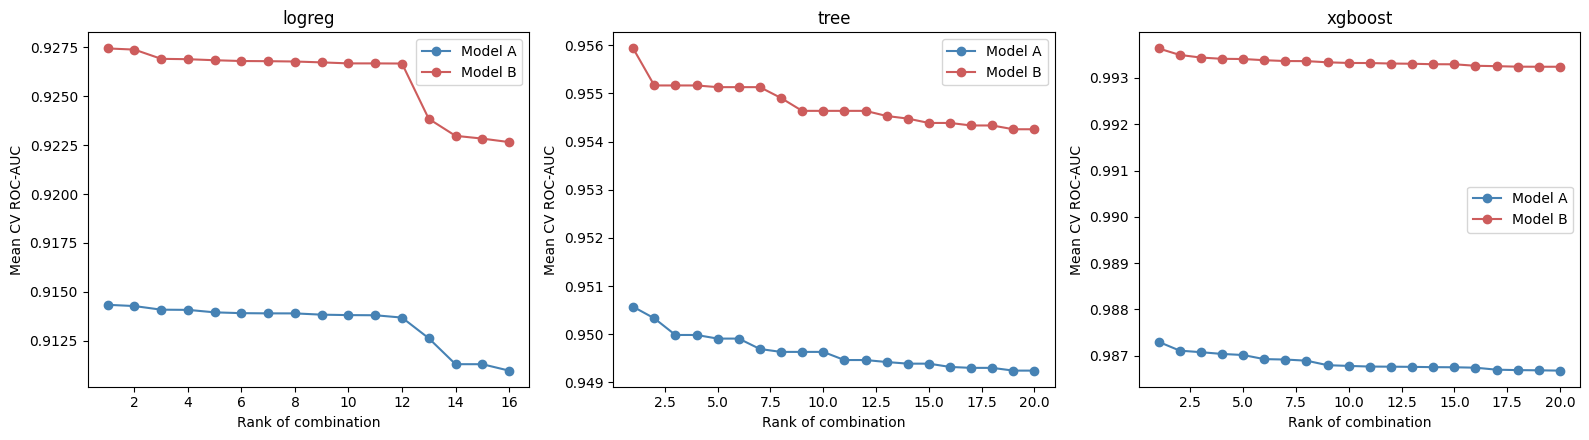

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, model_name in enumerate(["logreg", "tree", "xgboost"]):
    for feature_set, colour in [("A", "steelblue"), ("B", "indianred")]:

        # Top 20 combinations for this search, best first
        cv_table = pd.DataFrame(searches[model_name + "_" + feature_set].cv_results_)
        cv_table = cv_table.sort_values("rank_test_score").head(20)

        axes[i].plot(range(1, len(cv_table) + 1), cv_table["mean_test_score"],
                    marker="o", color=colour, label="Model " + feature_set)

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Rank of combination")
    axes[i].set_ylabel("Mean CV ROC-AUC")
    axes[i].legend()

savefig("08_top_cv_scores_A_vs_B")

### Grid Edge Check

A grid edge check examines whether the best-performing hyperparameter configuration lies at the boundary of the search range. If the optimum occurs at the minimum or maximum tested value, the search range may need to be expanded to determine whether a better configuration exists beyond the original grid. Hyperparameter search methods require careful consideration of the search space and its coverage (scikit-learn, n.d.-b; Bergstra and Bengio, 2012).

Only numerical hyperparameters are examined, as categorical parameters (for example, choice of penalty type or split criterion) do not have a meaningful minimum or maximum value. A parameter is flagged as **on edge** when the optimal value matches either the lowest or highest value available in the search grid.

This check helps assess whether the chosen search space was sufficiently broad. When an optimal value lies on the boundary of the grid, it may indicate that better-performing configurations exist beyond the tested range. In such cases, expanding the search space in future experiments could potentially yield further performance improvements.

The resulting table identifies all edge cases, providing a useful diagnostic for evaluating the adequacy of the hyperparameter search strategy and guiding future tuning efforts.

In [38]:
edge_rows = []

for name, search in searches.items():

    model_name = name.split("_")[0]

    for parameter, best_value in search.best_params_.items():

        # The values we offered for this setting
        offered_values = param_grids[model_name].get(parameter, [])

        # Only number settings can be "on the edge" (text settings like l1/l2 have no edge)
        is_number = isinstance(best_value, (int, float)) and not isinstance(best_value, bool)

        # Is the best value the smallest or largest we offered?
        if is_number and best_value in offered_values and len(offered_values) > 1:
            on_edge = best_value == min(offered_values) or best_value == max(offered_values)
        else:
            on_edge = None

        edge_rows.append({"search": name, "setting": parameter,
                        "best_value": best_value, "on_edge_of_grid": on_edge})

edge_table = pd.DataFrame(edge_rows)
edge_table.to_csv("outputs/tables/" + file_tag + "grid_edge_check.csv", index=False)

# Show only the settings that landed on an edge
edge_table[edge_table["on_edge_of_grid"] == True]

,search,setting,best_value,on_edge_of_grid
9,tree_A,model__min_samples_split,20,True
12,tree_B,model__min_samples_leaf,8,True
13,tree_B,model__min_samples_split,20,True
14,xgboost_A,model__colsample_bytree,0.6,True
17,xgboost_A,model__n_estimators,300,True
18,xgboost_A,model__subsample,1.0,True
19,xgboost_B,model__colsample_bytree,1.0,True
20,xgboost_B,model__learning_rate,0.2,True
21,xgboost_B,model__max_depth,3,True
22,xgboost_B,model__n_estimators,300,True


### Grid-Edge Check: Interpretation and Next Steps

#### Findings

The grid-edge diagnostic identified only a small number of hyperparameters whose optimal values occurred at the boundaries of the predefined search space:

- **Logistic Regression:** no numerical hyperparameters were selected at the edge of the grid.
- **Decision Tree:** `min_samples_split` (20) and `min_samples_leaf` (8) reached the upper limits of the explored range.
- **XGBoost:** `n_estimators` (300) reached the upper limit for both feature sets, while `learning_rate` (0.2), `max_depth` (3), and `colsample_bytree` (0.6) were also identified as edge cases.
- Values of `subsample` and `colsample_bytree` equal to 1.0 are not considered problematic, as these represent the maximum permissible values rather than indicators of an insufficient search range.

#### Interpretation

Hyperparameters selected at the boundary of a search grid may indicate that the true optimum lies slightly beyond the range explored. However, examination of the top-performing configurations shows that performance differences among the leading candidates are extremely small. As a result, any improvement obtained by extending the search space would likely be minor relative to the variability observed during cross-validation.

#### Decision

The original hyperparameter grids are retained for the remainder of the analysis for three reasons:

1. The grids were specified in the research methodology before experimentation.
2. Both Model A and Model B were tuned using identical search spaces, ensuring a fair and unbiased comparison.
3. Any potential performance gains from expanding the grids are expected to be small relative to the substantial computational cost of rerunning the searches.

#### Next Steps

The analysis proceeds using the existing tuned models. Subsequent stages include test-set evaluation, statistical significance testing, and model interpretation through SHAP analysis. The grid-edge findings are noted as a limitation of the study:

> *Several optimal hyperparameter values occurred at the boundaries of the predefined search grids, indicating that slightly better configurations may exist outside the explored ranges. However, identical grids were used for both feature sets, preserving the validity and comparability of the model comparison.*

## Final Models

Because `GridSearchCV` was executed with `refit=True`, the hyperparameter tuning process does more than identify the best-performing parameter combination. Once the optimal configuration has been found through cross-validation, the entire pipeline is automatically retrained on the full training dataset using those selected hyperparameters.

The resulting fitted pipeline is stored in the `best_estimator_` attribute of each grid search object. These pipelines represent the final tuned versions of each model, incorporating all preprocessing steps, class balancing procedures, and model parameters learned during training.

For convenience, the refitted pipelines are collected into a dictionary called `final_models`. Each entry therefore represents a fully trained and tuned model that is ready for test-set evaluation, statistical comparison, and interpretability analysis, without requiring any additional training.

In [39]:
final_models = {}

for name, search in searches.items():
    final_models[name] = search.best_estimator_

print("Final models ready:", list(final_models.keys()))

Final models ready: ['logreg_A', 'logreg_B', 'tree_A', 'tree_B', 'xgboost_A', 'xgboost_B']


## Test Set Predictions

To preserve the integrity of the evaluation process, the test set is used **only once** after all model development, tuning, and selection procedures have been completed. Each final tuned model generates a predicted probability of churn (class 1) for every customer in the test set, providing a common basis for subsequent analysis.

These predictions are then saved to disk and reused throughout the remainder of the study. As a result, all performance metrics, statistical significance tests, calibration analyses, and interpretability methods are applied to the exact same set of predictions.

This approach safeguards against data leakage, ensures full reproducibility of results, and prevents accidental reuse of the test data during later stages of the workflow. By treating the test set as a final holdout dataset, the reported performance estimates provide an unbiased assessment of how the models are expected to perform on unseen customer data.

In [40]:
test_probabilities = {}

for name, model in final_models.items():

    # Model A or Model B columns
    feature_set = name.split("_")[1]
    columns_used = feature_sets[feature_set]

    # Probability of churn (class 1) for every test customer
    test_probabilities[name] = model.predict_proba(x_test[columns_used])[:, 1]

joblib.dump(test_probabilities, "outputs/models/" + file_tag + "test_probabilities.joblib")

print("Test set scored once. Customers in the test set:", len(y_test))

Test set scored once. Customers in the test set: 2026


## Evaluation Metrics for Churn Prediction

Model performance is evaluated using several complementary metrics. Unless otherwise stated, class predictions are generated using the conventional **0.5 probability threshold**, meaning that a customer is classified as a churner when the predicted probability of churn is 0.5 or higher.

- **Precision:** The proportion of customers predicted to churn who actually churned. High precision indicates that positive predictions are reliable and that relatively few non-churners are incorrectly flagged as churners.

- **Recall:** The proportion of actual churners that are correctly identified by the model. Recall measures the model's ability to detect customers who are genuinely at risk of leaving.

- **F1 Score:** The harmonic mean of precision and recall. This metric balances the trade-off between identifying churners and avoiding false alarms, making it the primary evaluation metric for the churn class in this study.

- **ROC-AUC:** The area under the Receiver Operating Characteristic curve. ROC-AUC measures the model's ability to rank churners above non-churners across all possible classification thresholds. A value of 1.0 indicates perfect discrimination, while 0.5 corresponds to random guessing.

- **PR-AUC:** The area under the Precision-Recall curve. Because it focuses on the trade-off between precision and recall, this metric is particularly informative when evaluating models on imbalanced datasets where the churn class is relatively rare.

- **Accuracy:** The proportion of all predictions that are correct. Although widely reported, accuracy can be misleading in churn prediction because the majority of customers do not churn. A model may achieve high accuracy simply by predicting the majority class, even if it performs poorly at identifying churners.

Together, these metrics provide a comprehensive assessment of model performance. While ROC-AUC evaluates overall ranking ability, **F1 Score** and **PR-AUC** are particularly important in this study because they place greater emphasis on correctly identifying the minority churn class.

Because churn is the minority class in this dataset, precision–recall measures are useful alongside accuracy and ROC-AUC; precision–recall analysis can be more informative than ROC analysis for imbalanced binary classification (Saito and Rehmsmeier, 2015). ROC analysis provides a complementary view of discrimination across classification thresholds (Fawcett, 2006).

In [41]:
def calculate_metrics(y_true, probabilities, threshold=0.5):

    # Turn probabilities into yes/no predictions using the threshold
    predictions = (probabilities >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities)
    }

In [42]:
master_rows = []

for model_name in ["logreg", "tree", "xgboost"]:
    for feature_set in ["A", "B"]:

        name = model_name + "_" + feature_set

        # Test-set metrics at the default 0.5 threshold
        row = {"model": model_name, "features": feature_set}
        row.update(calculate_metrics(y_test, test_probabilities[name]))

        # Cross-validation AUC from tuning, to compare with the test AUC
        row["cv_auc"] = searches[name].best_score_
        row["test_minus_cv_auc"] = row["roc_auc"] - row["cv_auc"]

        master_rows.append(row)

master_table = pd.DataFrame(master_rows).round(4)
master_table.to_csv("outputs/tables/" + file_tag + "master_results_table.csv", index=False)
master_table

,model,features,accuracy,precision,recall,f1,roc_auc,pr_auc,cv_auc,test_minus_cv_auc
0,logreg,A,0.8421,0.5049,0.8000,0.6190,0.9068,0.6734,0.9143,-0.0076
1,logreg,B,0.8643,0.5527,0.8062,0.6558,0.9230,0.7421,0.9275,-0.0044
2,tree,A,0.9112,0.6790,0.8462,0.7534,0.9386,0.7907,0.9506,-0.0120
3,tree,B,0.9033,0.6608,0.8154,0.7300,0.9419,0.7570,0.9559,-0.0141
4,xgboost,A,0.9576,0.9078,0.8185,0.8608,0.9853,0.9420,0.9873,-0.0020
5,xgboost,B,0.9724,0.9410,0.8831,0.9111,0.9930,0.9687,0.9936,-0.0006


`test_minus_cv_auc` compares the test ROC-AUC with the cross-validation ROC-AUC from tuning. If it is close to 0, the models generalise to unseen customers about as well as they did in tuning (no sign of overfitting to the tuning process).

## Comparing Static and Behavioural Feature Sets

The following analysis compares **Model A**, which uses only static customer attributes (demographic and account snapshot variables), with **Model B**, which augments these variables with engineered trajectory features that capture changes in customer behaviour over time.

For each algorithm (logistic regression, decision tree, and XGBoost), performance differences are calculated as:

**Model B − Model A**

Comparing Model B with Model A helps assess whether adding behavioural trajectory features provides predictive value beyond the static features alone. This follows the principle of evaluating feature groups by measuring changes in model performance while maintaining a consistent experimental setup (Fostiropoulos and Itti, 2023; Kaya et al., 2018).

Positive values indicate that the addition of behavioural features improved model performance, while negative values suggest that the static feature set performed equally well or better.

These comparisons provide an initial indication of the potential value of incorporating behavioural information into churn prediction models. Both the direction and magnitude of the differences are considered, allowing assessment of whether the trajectory features produce consistent improvements across algorithms and evaluation metrics.

However, the reported differences are based on a single test set and should be interpreted as descriptive rather than conclusive. While they offer useful evidence regarding the practical impact of the additional features, formal statistical testing is required to determine whether the observed improvements are greater than would be expected from sampling variability alone. Such tests are conducted later in the analysis as part of the evaluation of **H1**.

In [43]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
difference_rows = []

for model_name in ["logreg", "tree", "xgboost"]:

    # The A and B rows for this algorithm
    row_a = master_table[(master_table["model"] == model_name) & (master_table["features"] == "A")].iloc[0]
    row_b = master_table[(master_table["model"] == model_name) & (master_table["features"] == "B")].iloc[0]

    # B minus A for each metric (positive = trajectory features helped)
    difference = {"model": model_name}
    for metric in metric_names:
        difference[metric] = row_b[metric] - row_a[metric]
    difference_rows.append(difference)

difference_table = pd.DataFrame(difference_rows).round(4)
difference_table.to_csv("outputs/tables/" + file_tag + "b_minus_a_table.csv", index=False)
difference_table

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,logreg,0.0222,0.0478,0.0062,0.0368,0.0162,0.0687
1,tree,-0.0079,-0.0182,-0.0308,-0.0234,0.0033,-0.0337
2,xgboost,0.0148,0.0332,0.0646,0.0503,0.0077,0.0267


# Confusion Matrices

## Confusion Matrix Interpretation

A confusion matrix summarises classification outcomes by comparing the model's predictions with the actual customer outcomes. Each cell represents the number of customers falling into a particular prediction-result combination:

- **True Negatives (top-left):** Customers who remained with the bank and were correctly classified as non-churners.
- **True Positives (bottom-right):** Customers who churned and were correctly identified as churners.
- **False Positives (top-right):** Customers who were incorrectly predicted to churn but ultimately remained with the bank.
- **False Negatives (bottom-left):** Customers who churned but were not identified by the model.

The diagonal cells represent correct classifications, while the off-diagonal cells represent prediction errors. Examining these counts provides insight into the types of mistakes made by the model and the trade-off between identifying churners and generating false alarms.

In the context of churn prediction, false negatives are often particularly important because they represent customers who are at risk of leaving but would not be targeted by retention efforts. Conversely, false positives may lead to unnecessary intervention costs by directing retention resources toward customers who would have remained regardless. The confusion matrix therefore complements summary metrics such as precision, recall, and F1 score by revealing the underlying pattern of correct and incorrect classifications.

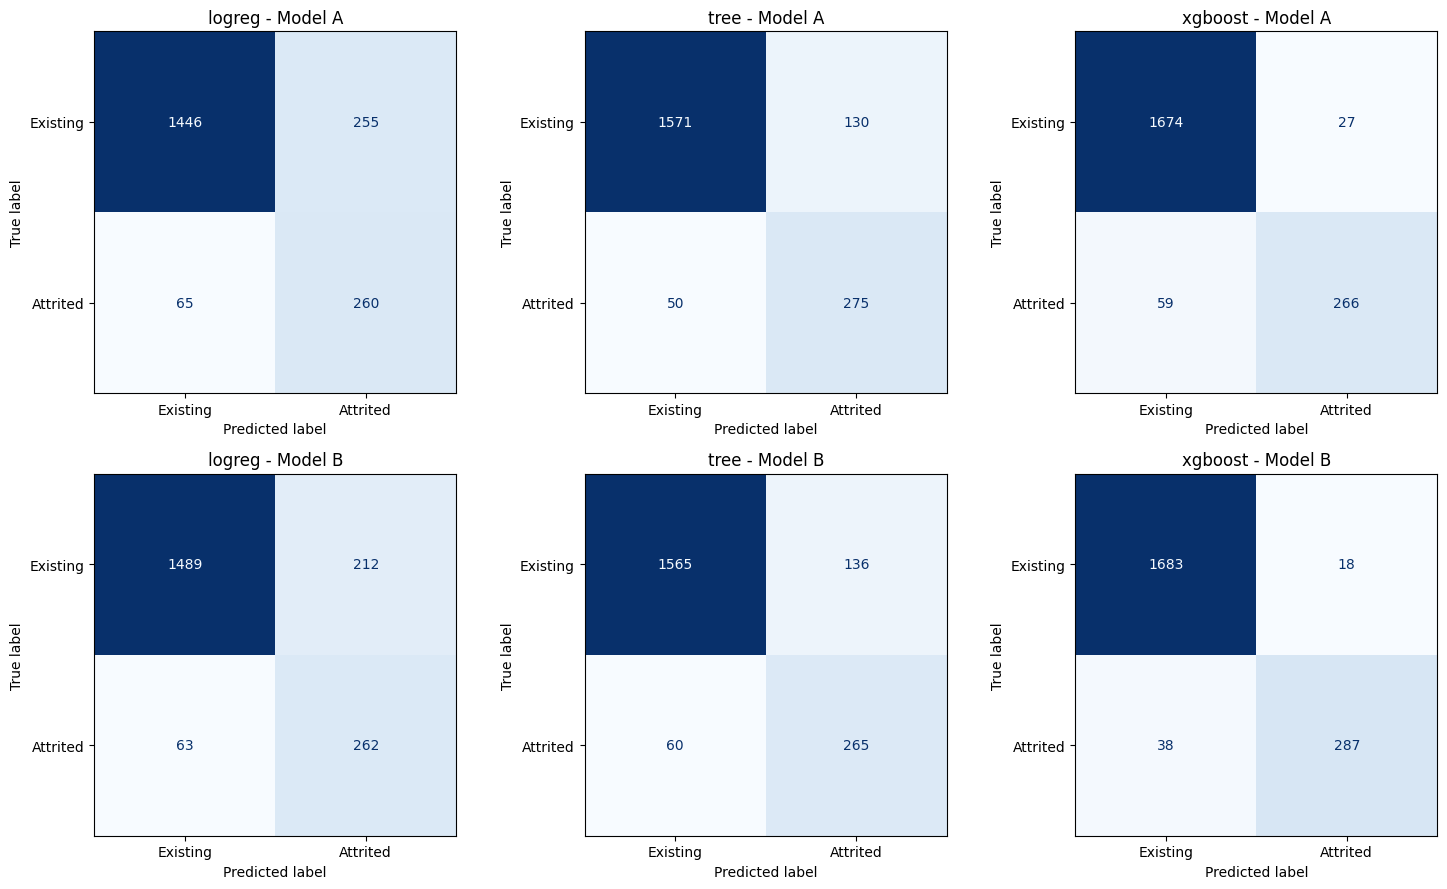

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, model_name in enumerate(["logreg", "tree", "xgboost"]):
    for row, feature_set in enumerate(["A", "B"]):

        name = model_name + "_" + feature_set

        # Yes/no predictions at the 0.5 threshold
        predictions = (test_probabilities[name] >= 0.5).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y_test, predictions,
            display_labels=["Existing", "Attrited"],
            cmap="Blues", colorbar=False, ax=axes[row, col]
        )
        axes[row, col].set_title(model_name + " - Model " + feature_set)

savefig("09_confusion_matrices")

## Confusion Matrix Results

Across all algorithms, the confusion matrices exhibit strong diagonal dominance, indicating that the majority of customers are classified correctly. This pattern is consistent with the high performance observed in the evaluation metrics and suggests that the models are effective at distinguishing between churners and non-churners.

Comparing the two feature sets shows that the effect of the behavioural trajectory features differs by algorithm. For **XGBoost**, Model B identifies noticeably more churners than Model A (about 287 vs 266 true positives) and makes far fewer errors (about 56 vs 86). For **logistic regression**, the gain is mainly a reduction in false alarms (about 275 vs 320 total errors), with almost no change in the number of churners caught (about 262 vs 260). For the **decision tree**, Model B performs slightly worse, catching fewer churners (about 265 vs 275) and making more errors (about 196 vs 180). The behavioural trajectory features therefore appear to add predictive information for logistic regression and XGBoost, but not for a single decision tree.

Among the evaluated algorithms, **XGBoost** demonstrates the strongest classification performance, with the largest concentration of observations along the diagonal and the fewest misclassifications. This finding is consistent with the superior ROC-AUC, PR-AUC, and F1 scores achieved by the boosted ensemble models. By combining many weak learners, XGBoost is able to capture complex non-linear relationships that may not be fully represented by logistic regression or a single decision tree.

Overall, the confusion matrices provide visual evidence that incorporating behavioural features improves churn detection and reduces classification errors for XGBoost, and reduces errors for logistic regression, but not for the decision tree. While the magnitude of the improvement varies across algorithms, the results are broadly consistent with the expectation that customer behaviour over time contains information that is valuable for predicting churn. Formal statistical testing is performed later to determine whether these observed improvements are statistically significant.

# ROC Curves: A vs B

## ROC Curve Analysis

The **Receiver Operating Characteristic (ROC) curve** evaluates a model's ability to discriminate between churners and non-churners across all possible classification thresholds. It plots the **true positive rate (recall)** against the **false positive rate**, illustrating the trade-off between correctly identifying churners and incorrectly flagging non-churners.

Each curve represents one of the trained models using either the static feature set (**Model A**) or the trajectory-augmented feature set (**Model B**). The overall quality of the ranking is summarized by the **Area Under the Curve (ROC-AUC)**, where values closer to 1.0 indicate stronger discriminatory power and a value of 0.5 corresponds to random classification.

### Interpretation

- Curves that lie closer to the **top-left corner** indicate superior performance, reflecting high recall combined with low false positive rates.
- The **dashed diagonal line** represents random guessing and serves as a baseline against which model performance can be compared.
- Differences between the Model A and Model B curves within each algorithm provide insight into whether incorporating behavioural trajectory features improves the model's ability to distinguish churners from non-churners.
- A higher ROC-AUC indicates better ranking performance, meaning that churners are more likely to receive higher predicted probabilities than non-churners.

This visualization provides a comprehensive view of classifier performance beyond a single threshold, emphasizing the robustness of each model’s predictive ranking.

The ROC curve is a threshold-independent way to describe the trade-off between sensitivity and false-positive rate, and the AUC summarises discrimination across thresholds (Fawcett, 2006).


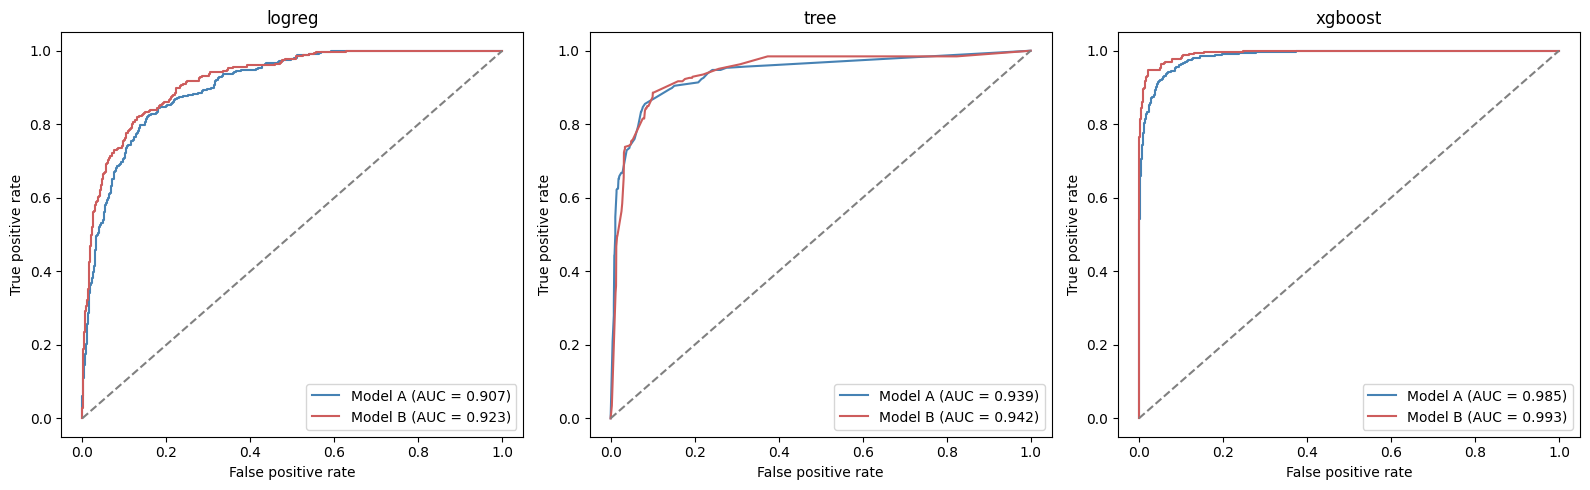

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, model_name in enumerate(["logreg", "tree", "xgboost"]):
    for feature_set, colour in [("A", "steelblue"), ("B", "indianred")]:

        name = model_name + "_" + feature_set

        # False positive rate and true positive rate at every threshold
        fpr, tpr, _ = roc_curve(y_test, test_probabilities[name])
        auc = roc_auc_score(y_test, test_probabilities[name])

        axes[i].plot(fpr, tpr, color=colour, label=f"Model {feature_set} (AUC = {auc:.3f})")

    axes[i].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[i].set_title(model_name)
    axes[i].set_xlabel("False positive rate")
    axes[i].set_ylabel("True positive rate")
    axes[i].legend(loc="lower right")

savefig("10_roc_curves_A_vs_B")

## ROC Curve Comparison Across Algorithms

The ROC curves compare the discriminatory performance of **Model A** (static features) and **Model B** (trajectory-augmented features) across the three classification algorithms. In each case, the curves lie well above the diagonal reference line, indicating performance substantially better than random guessing and demonstrating a strong ability to distinguish between churners and non-churners.

Across all algorithms, **Model B** achieves higher ROC-AUC values than **Model A**:

- **Logistic Regression:** 0.907 → 0.923
- **Decision Tree:** 0.939 → 0.942
- **XGBoost:** 0.985 → 0.993

These improvements indicate that incorporating behavioural trajectory features enhances the models' ability to rank customers according to churn risk. The size of the improvement varies considerably across algorithms: it is clear for logistic regression (+0.016) and XGBoost (+0.008), but very small for the decision tree (+0.003), a difference too small to be considered reliable.

The strongest performance is achieved by **XGBoost**, whose ROC curve remains closest to the top-left corner and produces the highest AUC values overall. This suggests that the boosted ensemble is particularly effective at exploiting the additional behavioural information and capturing complex relationships within the data.

Overall, the ROC analysis provides further evidence that behavioural trajectory features contribute useful predictive information for logistic regression and XGBoost, while the decision tree shows no meaningful gain. However, because these results are derived from a single test set, they should be interpreted as descriptive evidence. The statistical significance of the observed improvements is evaluated later through the formal hypothesis-testing procedures used to assess **H1**.

# Precision-recall curves: Model A vs B

## Precision-Recall Curve Analysis

The **Precision-Recall (PR) curve** provides a particularly informative evaluation of model performance in imbalanced classification problems such as churn prediction, where non-churners substantially outnumber churners. Unlike ROC curves, which consider both classes equally, PR curves focus specifically on the model's ability to identify the minority churn class.

Each curve illustrates the relationship between **precision** (the proportion of predicted churners who actually churned) and **recall** (the proportion of actual churners correctly identified) across all possible classification thresholds. The **dashed horizontal line** represents the baseline precision equal to the observed churn rate, corresponding to the expected performance of random selection.

### Interpretation

- Curves that remain well above the baseline indicate strong predictive performance, maintaining high precision while identifying a substantial proportion of churners.
- The **area under the Precision-Recall curve (PR-AUC)** summarises overall performance, with larger values indicating a better balance between precision and recall across thresholds.
- Comparisons between **Model A** and **Model B** reveal whether the inclusion of behavioural trajectory features improves the detection of churners without generating excessive false positives.
- Because PR-AUC focuses on the minority class, it often provides a more informative assessment than ROC-AUC when class imbalance is present.

This view complements the ROC analysis by emphasizing performance on the rare churn class, offering a more informative assessment of model effectiveness in imbalanced settings.

This emphasis on the positive class is consistent with evidence that precision–recall plots can be particularly informative when evaluating classifiers on imbalanced datasets (Saito and Rehmsmeier, 2015).

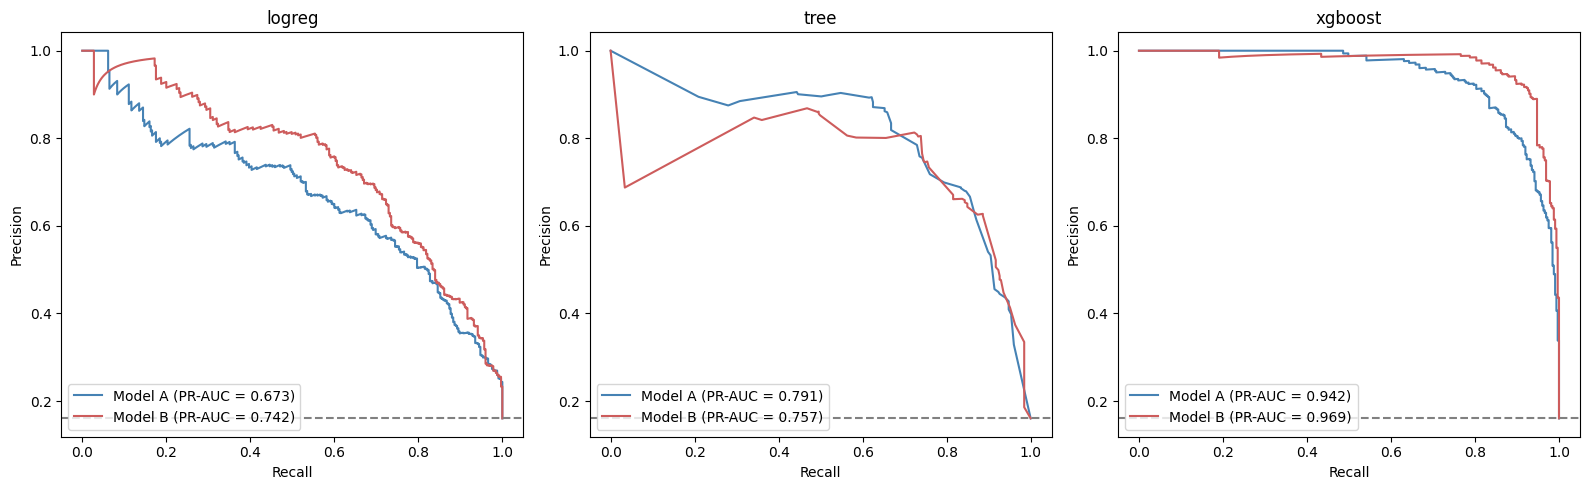

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, model_name in enumerate(["logreg", "tree", "xgboost"]):
    for feature_set, colour in [("A", "steelblue"), ("B", "indianred")]:

        name = model_name + "_" + feature_set

        precision, recall, _ = precision_recall_curve(y_test, test_probabilities[name])
        pr_auc = average_precision_score(y_test, test_probabilities[name])

        axes[i].plot(recall, precision, color=colour, label=f"Model {feature_set} (PR-AUC = {pr_auc:.3f})")

    # A model that guesses would sit at the churn rate
    axes[i].axhline(y_test.mean(), linestyle="--", color="gray")
    axes[i].set_title(model_name)
    axes[i].set_xlabel("Recall")
    axes[i].set_ylabel("Precision")
    axes[i].legend(loc="lower left")

savefig("11_precision_recall_curves_A_vs_B")

## Precision-Recall Curve Comparison Across Algorithms

The Precision-Recall (PR) curves compare the performance of **Model A** (static features) and **Model B** (trajectory-augmented features) across the logistic regression, decision tree, and XGBoost classifiers. Because churners represent a minority of customers, PR curves provide a particularly informative assessment of model performance by focusing on the trade-off between **precision** and **recall** across all classification thresholds.

Across the three algorithms, both feature sets perform substantially better than the baseline churn rate, indicating meaningful predictive capability. However, the impact of the behavioural features differs across algorithms:

- **Logistic Regression:** Model B achieves a noticeably higher PR-AUC than Model A (**0.742 vs. 0.673**), suggesting that the trajectory features improve the model's ability to identify churners while maintaining precision.
- **Decision Tree:** Performance is broadly similar between the two feature sets, with Model A achieving a slightly higher PR-AUC (**0.791 vs. 0.757**). This suggests that the additional behavioural features do not consistently improve minority-class detection within a single-tree framework.
- **XGBoost:** Both models perform exceptionally well, although Model B achieves the highest PR-AUC overall (**0.969 vs. 0.942**). This indicates that the behavioural features enhance the model's ability to identify churners while maintaining high precision even at elevated levels of recall.

Overall, the PR curves suggest that behavioural trajectory features generally improve the detection of churners, particularly for logistic regression and XGBoost. The largest benefit is observed for XGBoost, where the combination of trajectory features and boosted ensemble learning yields the strongest performance on the minority churn class. While the decision tree results show a small exception to this pattern, the overall evidence indicates that incorporating behavioural information can enhance churn prediction in imbalanced datasets.

As with the ROC analysis, these results are based on a single test set and should be interpreted as descriptive evidence. Formal statistical testing is performed later to determine whether the observed differences between Model A and Model B are statistically significant and therefore provide support for **H1**.

## Supplementary Threshold Analysis

Supplementary threshold analysis investigates how changing the classification decision threshold affects model performance. Although a classifier may produce probability estimates, the threshold used to convert these estimates into class labels influences the resulting balance between identifying positive cases and avoiding false positives (scikit-learn, n.d.-a).

All primary results reported in this study use the conventional **0.5 classification threshold**, whereby customers with predicted churn probabilities of 0.5 or greater are classified as churners. While this threshold is widely used, it may not be optimal in imbalanced classification problems such as churn prediction, where the minority class is of greatest interest.

To investigate alternative decision thresholds without introducing bias, threshold selection is performed using **out-of-fold predictions generated on the training set**. Under this approach, each training observation is scored by a model that was not trained on that observation, providing an unbiased estimate of model performance across different thresholds.

For each model, precision, recall, and F1 scores are calculated over a range of thresholds from 0.05 to 0.95. The threshold that maximises the **F1 score** on the out-of-fold training predictions is selected as the optimal operating point. This threshold is then applied directly to the previously saved test-set probabilities, ensuring that the test set is not rescored or used during the threshold-selection process.

The resulting table reports the selected threshold, the corresponding out-of-fold training F1 score, and the resulting test-set performance metrics. Comparing these results with those obtained at the default threshold provides insight into how the decision boundary affects model behaviour.

This analysis is intended as a supplementary evaluation rather than a replacement for the primary results. While the main findings remain based on the standard 0.5 threshold, the threshold optimisation exercise illustrates the trade-off between **precision** and **recall**, showing how different operating points may be chosen depending on whether the priority is to minimise missed churners or reduce false alarms.

In [47]:
oof_probabilities = {}

for name, model in final_models.items():

    feature_set = name.split("_")[1]
    columns_used = feature_sets[feature_set]

    # clone() makes an unfitted copy with the same best settings.
    # cross_val_predict then predicts every training customer using models that did not train on them.
    oof_probabilities[name] = cross_val_predict(
        clone(model),
        x_train[columns_used],
        y_train,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=Seed),
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

print("Out-of-fold predictions done for:", list(oof_probabilities.keys()))

Out-of-fold predictions done for: ['logreg_A', 'logreg_B', 'tree_A', 'tree_B', 'xgboost_A', 'xgboost_B']


In [48]:
# The cut-offs to try: 0.05, 0.06, ... 0.95
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_rows = []
threshold_curves = {}

for name in final_models.keys():

    # F1, precision and recall on the TRAINING out-of-fold predictions at every cut-off
    f1_values, precision_values, recall_values = [], [], []

    for threshold in thresholds:
        predictions = (oof_probabilities[name] >= threshold).astype(int)
        f1_values.append(f1_score(y_train, predictions, zero_division=0))
        precision_values.append(precision_score(y_train, predictions, zero_division=0))
        recall_values.append(recall_score(y_train, predictions, zero_division=0))

    threshold_curves[name] = (f1_values, precision_values, recall_values)

    # The cut-off with the best F1 on the training data
    best_index = int(np.argmax(f1_values))
    best_threshold = float(thresholds[best_index])

    # Apply that cut-off to the SAVED test probabilities (no new test predictions)
    row = {"model": name.split("_")[0], "features": name.split("_")[1],
        "chosen_threshold": round(best_threshold, 2),
        "train_oof_f1": f1_values[best_index]}
    row.update(calculate_metrics(y_test, test_probabilities[name], threshold=best_threshold))
    threshold_rows.append(row)

threshold_table = pd.DataFrame(threshold_rows).round(4)
threshold_table.to_csv("outputs/tables/" + file_tag + "threshold_analysis.csv", index=False)
threshold_table

,model,features,chosen_threshold,train_oof_f1,accuracy,precision,recall,f1,roc_auc,pr_auc
0,logreg,A,0.71,0.6514,0.8820,0.6243,0.6646,0.6438,0.9068,0.6734
1,logreg,B,0.64,0.6917,0.8865,0.6247,0.7323,0.6742,0.9230,0.7421
2,tree,A,0.70,0.7766,0.9245,0.7848,0.7292,0.7560,0.9386,0.7907
3,tree,B,0.54,0.7999,0.9171,0.7343,0.7569,0.7455,0.9419,0.7570
4,xgboost,A,0.47,0.8792,0.9576,0.8997,0.8277,0.8622,0.9853,0.9420
5,xgboost,B,0.56,0.9137,0.9719,0.9467,0.8738,0.9088,0.9930,0.9687


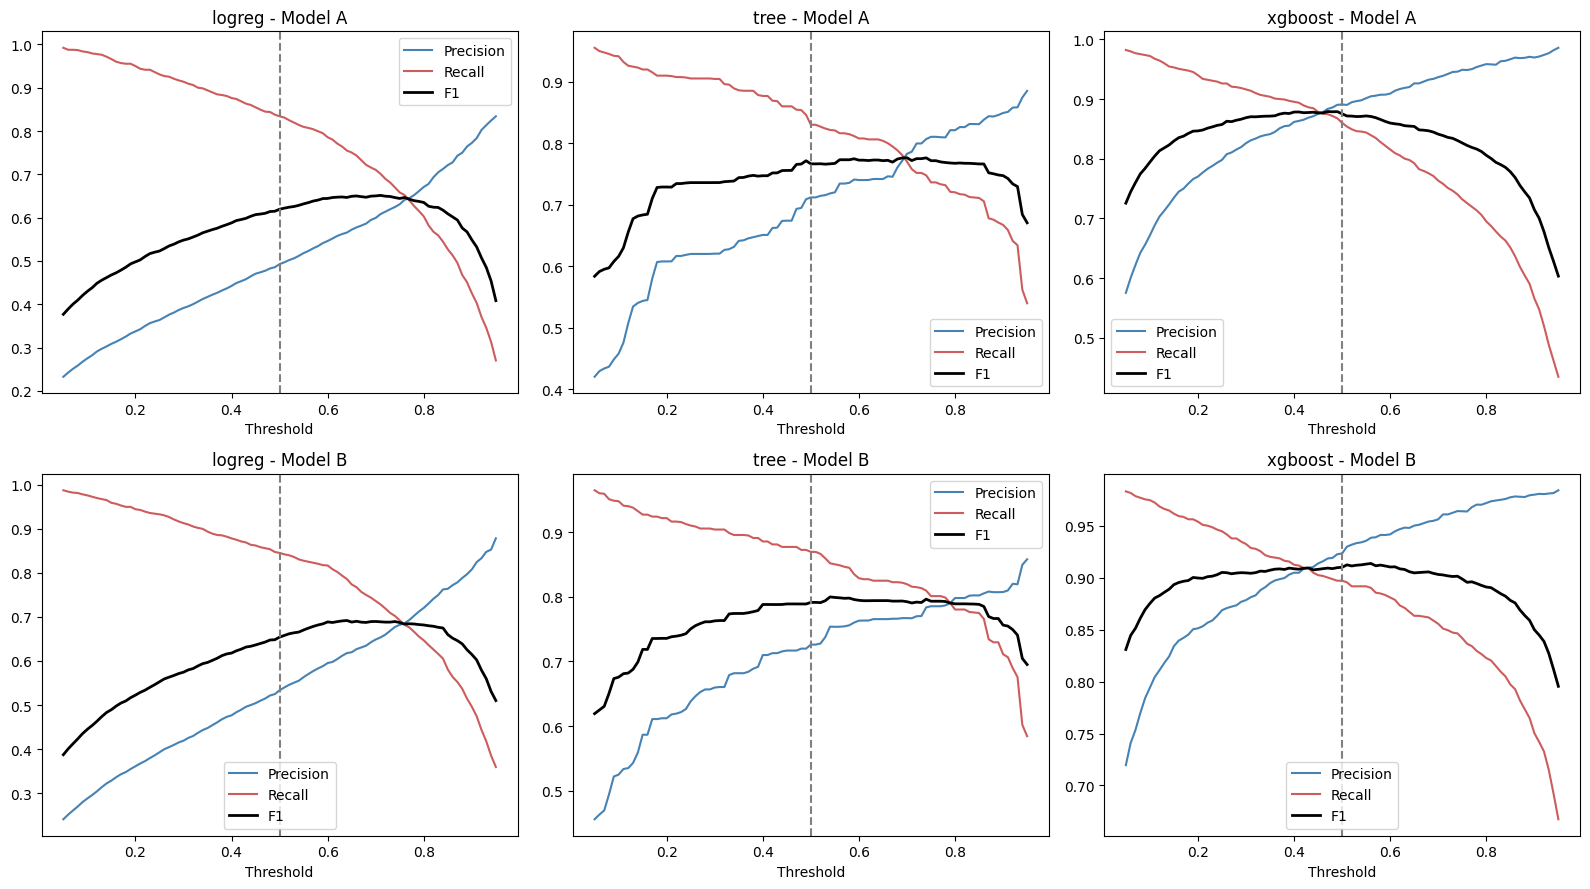

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, model_name in enumerate(["logreg", "tree", "xgboost"]):
    for row, feature_set in enumerate(["A", "B"]):

        name = model_name + "_" + feature_set
        f1_values, precision_values, recall_values = threshold_curves[name]

        axes[row, col].plot(thresholds, precision_values, label="Precision", color="steelblue")
        axes[row, col].plot(thresholds, recall_values, label="Recall", color="indianred")
        axes[row, col].plot(thresholds, f1_values, label="F1", color="black", linewidth=2)

        # Mark the default 0.5 cut-off
        axes[row, col].axvline(0.5, linestyle="--", color="gray")
        axes[row, col].set_title(model_name + " - Model " + feature_set)
        axes[row, col].set_xlabel("Threshold")
        axes[row, col].legend()

savefig("12_threshold_analysis")

## Interpretation of Threshold Curves

The threshold curves illustrate how **precision**, **recall**, and **F1 score** change as the classification threshold varies. Lower thresholds classify more customers as potential churners, which generally increases recall but reduces precision due to a larger number of false positives. Conversely, higher thresholds make the model more conservative, improving precision while reducing recall. The **F1 score** summarises this trade-off by combining precision and recall into a single metric, with the peak of the F1 curve indicating the threshold that provides the most balanced performance.These curves are calculated from out-of-fold predictions on the training set, so no test data was used to explore or select thresholds.

Several patterns emerge across the models:

- **Logistic Regression:** The highest F1 scores occur at thresholds above the conventional 0.5 cut-off, typically around 0.6-0.7. This suggests that a slightly more conservative decision boundary improves the balance between correctly identifying churners and limiting false alarms.
- **Decision Tree:** The F1 curve remains relatively stable across a broad range of thresholds, indicating that performance is less sensitive to the specific choice of cut-off and that the model produces reasonably robust classifications.
- **XGBoost:** Precision and recall remain simultaneously high across much of the threshold range, with the optimal F1 score occurring close to the default threshold of 0.5 (about 0.47 for Model A and 0.56 for Model B). This suggests that little threshold adjustment is needed to achieve strong performance.
- **Model B (Trajectory-Augmented Features):** On the training out-of-fold predictions, Model B achieves higher F1 scores than Model A across most threshold values for all three algorithms, suggesting that the behavioural features improve the balance between precision and recall. For the decision tree, this advantage did not carry over to the test set (see the comparison table below), where Model A scored slightly higher.

Overall, the curves demonstrate that the standard 0.5 threshold provides reasonable performance for all models. However, modest threshold adjustments can improve the precision-recall trade-off, particularly for logistic regression. These findings highlight that model performance depends not only on predictive accuracy but also on the choice of decision threshold, which should be aligned with the practical objectives of a churn-retention strategy. For example, organisations seeking to minimise missed churners may favour lower thresholds, whereas those wishing to reduce unnecessary retention interventions may prefer higher thresholds.

## Supplementary Comparison of Classification Thresholds

The primary results presented in this study are based on the conventional **0.5 probability threshold**, providing a consistent benchmark for comparing algorithms and feature sets. However, classification performance can be sensitive to the choice of threshold, particularly in imbalanced problems such as churn prediction.

The table below compares model performance under two scenarios:

1. **The default threshold (0.5)** used throughout the main analysis.
2. **An optimised threshold** selected using out-of-fold predictions generated from the training data.

Because the alternative thresholds are chosen exclusively from training-set information, the integrity of the test set is preserved. The saved test-set probabilities are reused without retraining or rescoring the models, ensuring that the comparison remains free from data leakage.

This supplementary analysis illustrates how threshold selection influences the trade-off between precision and recall. In particular, it demonstrates whether improvements in one metric are achieved at the expense of another and highlights situations where a modest adjustment to the decision boundary may yield a more favourable balance between missed churners and false alarms.

The 0.5 threshold remains the reference point for all primary findings. The optimised-threshold results are presented as an additional perspective on model behaviour and as an example of how predictive models may be tailored to different business objectives and retention strategies.

In [50]:
comparison_rows = []

for model_name in ["logreg", "tree", "xgboost"]:
    for feature_set in ["A", "B"]:

        main_row = master_table[(master_table["model"] == model_name) & (master_table["features"] == feature_set)].iloc[0]
        chosen_row = threshold_table[(threshold_table["model"] == model_name) & (threshold_table["features"] == feature_set)].iloc[0]

        comparison_rows.append({
            "model": model_name, "features": feature_set,
            "f1_at_0.5": main_row["f1"],
            "chosen_threshold": chosen_row["chosen_threshold"],
            "f1_at_chosen": chosen_row["f1"],
            "recall_at_0.5": main_row["recall"],
            "recall_at_chosen": chosen_row["recall"],
            "precision_at_0.5": main_row["precision"],
            "precision_at_chosen": chosen_row["precision"]
        })

pd.DataFrame(comparison_rows).round(4)

,model,features,f1_at_0.5,chosen_threshold,f1_at_chosen,recall_at_0.5,recall_at_chosen,precision_at_0.5,precision_at_chosen
0,logreg,A,0.6190,0.71,0.6438,0.8000,0.6646,0.5049,0.6243
1,logreg,B,0.6558,0.64,0.6742,0.8062,0.7323,0.5527,0.6247
2,tree,A,0.7534,0.70,0.7560,0.8462,0.7292,0.6790,0.7848
3,tree,B,0.7300,0.54,0.7455,0.8154,0.7569,0.6608,0.7343
4,xgboost,A,0.8608,0.47,0.8622,0.8185,0.8277,0.9078,0.8997
5,xgboost,B,0.9111,0.56,0.9088,0.8831,0.8738,0.9410,0.9467


## Comparison of Default and Optimized Thresholds

The comparison between the conventional **0.5 threshold** and the thresholds selected through out-of-fold optimisation demonstrates how the classification boundary influences the trade-off between precision and recall. Although the magnitude of the effect varies across algorithms, several consistent patterns can be observed.

- **Logistic Regression:** Both feature sets benefit from increasing the threshold above 0.5 (approximately 0.64-0.71). This results in substantially higher precision, indicating fewer false positives, while recall decreases as the model becomes more conservative. The net effect is a modest improvement in F1 score, suggesting a better overall balance between identifying churners and limiting false alarms.

- **Decision Tree:** The optimised thresholds (approximately 0.54-0.70) also favour higher precision at the expense of some recall. However, changes in F1 score are relatively small, indicating that decision tree performance is reasonably stable across a range of threshold values.

- **XGBoost:** The optimal thresholds remain close to the default value (approximately 0.47-0.56), and the resulting performance metrics change only marginally. This suggests that little threshold adjustment is needed for XGBoost to achieve strong performance.
  
- **Model B (Trajectory-Augmented Features):** For logistic regression and XGBoost, Model B achieves higher F1 than Model A under both the default and the optimised thresholds (for XGBoost, 0.911 vs 0.861 at 0.5 and 0.909 vs 0.862 at the chosen thresholds). For the decision tree, Model B is slightly lower under both (0.730 vs 0.753 at 0.5 and 0.746 vs 0.756 at the chosen thresholds).

Overall, threshold optimisation can produce modest improvements in classification performance, particularly for logistic regression where a more conservative decision boundary reduces false positives while maintaining acceptable recall. However, the strongest-performing models, especially **XGBoost with behavioural features**, exhibit minimal sensitivity to threshold selection and deliver strong results even at the standard 0.5 cut-off. These findings suggest that while threshold tuning can refine operational performance, the choice of learning algorithm, and for logistic regression and XGBoost the choice of feature set, has a substantially greater impact on predictive effectiveness.

# H1: Does Model B Outperform Model A?

**H1:** Models incorporating trajectory features will significantly outperform models using static features only on churn-class **F1-score** and **ROC-AUC**.

Observed differences in model performance may reflect either genuine predictive improvements or random variation arising from a particular sample or train-validation split. To determine whether the performance gains associated with Model B are reliable, the comparison between Model A and Model B is evaluated using two complementary statistical approaches.

| Method | Purpose | Data Used |
|----------|----------|----------|
| Repeated cross-validation + corrected paired t-test | Tests whether Model B consistently outperforms Model A across multiple train-validation splits | Training set |
| Bootstrap confidence intervals | Estimates the magnitude and uncertainty of the performance difference on unseen data | Held-out test set |

The repeated cross-validation analysis assesses whether any observed improvement is statistically significant and reproducible across different partitions of the training data. The bootstrap analysis complements this by quantifying the practical size of the improvement and its associated uncertainty when evaluated on the independent test set.

Taken together, these methods provide evidence regarding both **statistical significance** and **practical reliability**. Consistent findings across the training-set and test-set analyses increase confidence that any advantage observed for Model B reflects a genuine improvement in predictive performance rather than a result of sampling variability.

Because H1 focuses on F1-score and ROC-AUC across three algorithms, Holm-adjusted p-values are used to control the family-wise error rate when conducting multiple statistical tests (Holm, 1979).

Statistical comparisons of machine-learning models require care because repeated training and validation splits are not fully independent. Research on classifier comparison highlights that the choice of test and the dependence between resamples can affect false-positive rates (Dietterich, 1998; Nadeau and Bengio, 2003). P-values and confidence intervals should therefore be interpreted alongside effect sizes and the analysis design (Greenland *et al*., 2016).


## Repeated Cross-Validation

Repeated cross-validation was used to evaluate whether the performance differences between **Feature Set A** and **Feature Set B** were consistent across multiple train-validation splits rather than being driven by a single partition of the data. A **5 × 5 repeated stratified cross-validation** design was employed, producing 25 train-validation splits. Because both feature sets were evaluated on the same splits, performance could be compared directly on a paired basis.

This approach provides a more robust estimate of model performance by reducing dependence on any individual split of the data. It also generates the paired observations required for formal statistical testing of the differences between Feature Set A and Feature Set B.

It is important to note that the models were evaluated using the same training data on which hyperparameter tuning was performed. Consequently, the reported performance estimates are likely to be somewhat optimistic and should not be interpreted as unbiased estimates of out-of-sample performance. However, because this optimism affects both feature sets equally, the relative comparison between Feature Set A and Feature Set B remains appropriate for assessing whether the trajectory features provide additional predictive value.

Repeated validation can show whether observed differences persist across multiple data partitions, but model-selection decisions based on validation results may still introduce optimism (Cawley and Talbot, 2010; Lones, 2024).


In [51]:
model_names = ["logreg", "tree", "xgboost"]
feature_set_names = ["A", "B"]

# 5-fold cross-validation repeated 5 times = 25 train/validation splits
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=Seed)
fold_splits = list(repeated_cv.split(x_train, y_train))

print("Number of train/validation splits:", len(fold_splits))

Number of train/validation splits: 25


In [52]:
def repeated_cv_scores(pipeline_template, columns_used, x_data, y_data, splits):

    # Lists to store the score of each split
    auc_scores, f1_scores, pr_auc_scores = [], [], []

    for train_index, validation_index in splits:

        # clone() makes a fresh, unfitted copy with the same (tuned) settings
        model = clone(pipeline_template)

        # Fit on the training part of this split
        model.fit(x_data.iloc[train_index][columns_used], y_data.iloc[train_index])

        # Predict the validation part of this split
        y_validation = y_data.iloc[validation_index]
        probabilities = model.predict_proba(x_data.iloc[validation_index][columns_used])[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        auc_scores.append(roc_auc_score(y_validation, probabilities))
        f1_scores.append(f1_score(y_validation, predictions, zero_division=0))
        pr_auc_scores.append(average_precision_score(y_validation, probabilities))

    return pd.DataFrame({"roc_auc": auc_scores, "f1": f1_scores, "pr_auc": pr_auc_scores})

In [53]:
# Run the 25 splits for each of the 6 tuned models 
cv_scores = {}

for model_name in model_names:
    for feature_set in feature_set_names:

        name = model_name + "_" + feature_set
        start_time = time.time()

        cv_scores[name] = repeated_cv_scores(
            final_models[name], feature_sets[feature_set], x_train, y_train, fold_splits
        )

        print(f"{name}: done in {(time.time() - start_time) / 60:.1f} min")

joblib.dump(cv_scores, "outputs/models/" + file_tag + "repeated_cv_scores.joblib")

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penal

logreg_A: done in 0.4 min


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penal

logreg_B: done in 0.4 min
tree_A: done in 0.2 min
tree_B: done in 0.2 min
xgboost_A: done in 1.5 min
xgboost_B: done in 1.0 min


['outputs/models/repeated_cv_scores.joblib']

In [54]:
# Average score and spread across the 25 splits
summary_rows = []

for name, scores in cv_scores.items():
    summary_rows.append({
        "model": name.split("_")[0],
        "features": name.split("_")[1],
        "auc_mean": scores["roc_auc"].mean(), "auc_std": scores["roc_auc"].std(),
        "f1_mean": scores["f1"].mean(), "f1_std": scores["f1"].std(),
        "pr_auc_mean": scores["pr_auc"].mean(), "pr_auc_std": scores["pr_auc"].std()
    })

repeated_cv_summary = pd.DataFrame(summary_rows).round(4)
repeated_cv_summary.to_csv("outputs/tables/" + file_tag + "repeated_cv_summary.csv", index=False)
repeated_cv_summary

,model,features,auc_mean,auc_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std
0,logreg,A,0.9145,0.0071,0.6194,0.0117,0.6959,0.0222
1,logreg,B,0.9275,0.0069,0.6539,0.0145,0.7579,0.0171
2,tree,A,0.9503,0.0083,0.7681,0.0179,0.8069,0.0262
3,tree,B,0.9509,0.0097,0.7814,0.0225,0.7758,0.0288
4,xgboost,A,0.9875,0.0027,0.8725,0.0142,0.9449,0.0089
5,xgboost,B,0.9939,0.0017,0.9158,0.0118,0.9727,0.0057


Across the evaluated models, Feature Set B generally outperformed Feature Set A. The improvement was most pronounced for Logistic Regression and XGBoost, particularly in PR-AUC, suggesting that the additional features improved the models' ability to identify positive cases. XGBoost combined with Feature Set B delivered the best overall performance, achieving an AUC of 0.9939, an F1-score of 0.9158, and a PR-AUC of 0.9727. In contrast, the Decision Tree model showed only marginal differences between the two feature sets, indicating limited sensitivity to the additional features.

## Corrected Paired Statistical Tests

To determine whether **Feature Set B** significantly outperformed **Feature Set A**, statistical tests were applied to the repeated cross-validation results. Because both feature sets were evaluated on the same 25 train-validation splits, performance could be compared on a paired basis by examining the difference in scores (**B − A**) for each split.

A standard paired t-test would treat these performance differences as independent observations. However, repeated cross-validation produces overlapping training sets, meaning the observations are not fully independent. To account for this dependence, a **corrected paired t-test** is used, providing a more conservative and reliable assessment of statistical significance.

### Interpreting the Results

- **mean_difference:** The average performance improvement of Feature Set B relative to Feature Set A across the 25 evaluation splits. Positive values indicate that the trajectory features improved performance.
- **95% confidence interval:** The range of plausible values for the true performance difference. If the interval remains entirely above zero, the results provide evidence of a consistent advantage for Feature Set B.
- **Corrected p-value:** The probability of observing a difference at least as large as the one obtained if there were no true performance difference between the feature sets. Holm-adjusted p-values are reported to account for multiple comparisons.
- **splits_first_better:** The number of evaluation splits in which Feature Set B achieved a higher score than Feature Set A. Values substantially above half of the total splits indicate that the improvement is consistently observed across different train-validation partitions.

Together, these statistics provide evidence regarding both the **magnitude** and **reliability** of the performance differences. The corrected paired tests form the primary statistical assessment of **H1**, evaluating whether the observed gains associated with the trajectory features are likely to reflect a genuine improvement rather than random variation across data splits.

The dependence between cross-validation results matters when conducting significance tests: repeated splits share observations and overlapping training data, so their scores should not automatically be treated as independent replicates (Dietterich, 1998; Nadeau and Bengio, 2003).

In [55]:
# In 5-fold CV the validation part is 1/4 the size of the training part
test_to_train_ratio = 1 / 4


def compare_scores(scores_first, scores_second):

    # Difference on each split: first minus second
    differences = np.array(scores_first) - np.array(scores_second)
    n = len(differences)
    mean_difference = differences.mean()
    variance = differences.var(ddof=1)

    #corrected standard error
    corrected_se = np.sqrt((1 / n + test_to_train_ratio) * variance)

    if corrected_se == 0:
        t_statistic, p_value, ci_low, ci_high = np.nan, np.nan, np.nan, np.nan
    else:
        t_statistic = mean_difference / corrected_se
        p_value = 2 * stats.t.sf(abs(t_statistic), df=n - 1)
        t_critical = stats.t.ppf(0.975, df=n - 1)
        ci_low = mean_difference - t_critical * corrected_se
        ci_high = mean_difference + t_critical * corrected_se

    return {
        "mean_difference": mean_difference,
        "ci_low": ci_low, "ci_high": ci_high,
        "corrected_t_p": p_value,
        "splits_first_better": int((differences > 0).sum()),
        "splits": n
    }

In [56]:
h1_rows = []

for model_name in model_names:
    for metric in ["roc_auc", "f1", "pr_auc"]:

        # B minus A on every split
        result = compare_scores(cv_scores[model_name + "_B"][metric], cv_scores[model_name + "_A"][metric])

        row = {"model": model_name, "metric": metric}
        row.update(result)
        h1_rows.append(row)

h1_table = pd.DataFrame(h1_rows)

# Holm adjustment for the main family of tests: 3 algorithms x 2 metrics (ROC-AUC and F1)
primary = h1_table["metric"].isin(["roc_auc", "f1"])
h1_table.loc[primary, "p_holm"] = multipletests(
    h1_table.loc[primary, "corrected_t_p"].fillna(1.0), method="holm"
)[1]

h1_table = h1_table.round(4)
h1_table.to_csv("outputs/tables/" + file_tag + "h1_repeated_cv_tests.csv", index=False)
h1_table

,model,metric,mean_difference,ci_low,ci_high,corrected_t_p,splits_first_better,splits,p_holm
0,logreg,roc_auc,0.0130,0.0097,0.0163,0.0000,25,25,0.0000
1,logreg,f1,0.0345,0.0249,0.0441,0.0000,25,25,0.0000
2,logreg,pr_auc,0.0620,0.0456,0.0783,0.0000,25,25,NaN
3,tree,roc_auc,0.0006,-0.0097,0.0109,0.9086,13,25,0.9086
4,tree,f1,0.0133,-0.0057,0.0323,0.1607,20,25,0.3213
5,tree,pr_auc,-0.0310,-0.0588,-0.0032,0.0301,2,25,NaN
6,xgboost,roc_auc,0.0064,0.0047,0.0081,0.0000,25,25,0.0000
7,xgboost,f1,0.0433,0.0297,0.0570,0.0000,25,25,0.0000
8,xgboost,pr_auc,0.0279,0.0212,0.0345,0.0000,25,25,NaN


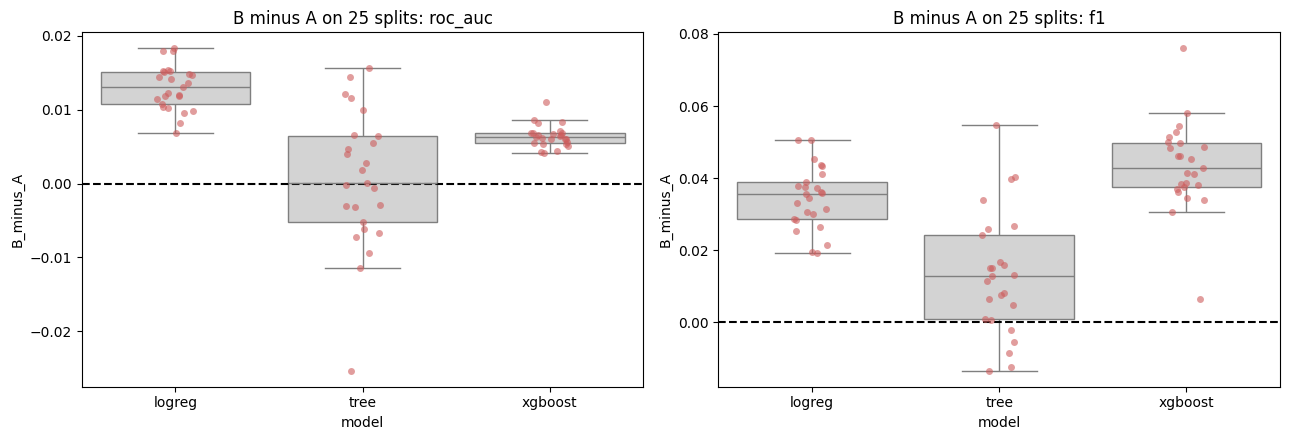

In [57]:
# Plot B minus A on each of the 25 splits
difference_rows = []

for model_name in model_names:
    for metric in ["roc_auc", "f1"]:
        differences = cv_scores[model_name + "_B"][metric].values - cv_scores[model_name + "_A"][metric].values
        for value in differences:
            difference_rows.append({"model": model_name, "metric": metric, "B_minus_A": value})

difference_long = pd.DataFrame(difference_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric in zip(axes, ["roc_auc", "f1"]):
    subset = difference_long[difference_long["metric"] == metric]
    sns.boxplot(data=subset, x="model", y="B_minus_A", ax=ax, color="lightgray", showfliers=False)
    sns.stripplot(data=subset, x="model", y="B_minus_A", ax=ax, color="indianred", alpha=0.6)
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title("B minus A on 25 splits: " + metric)

savefig("13_h1_cv_differences")

The trajectory features provided consistent and statistically significant improvements for Logistic Regression and XGBoost across all evaluation metrics. The strongest gains were observed for Logistic Regression in PR-AUC (+0.0620) and for XGBoost in F1-score (+0.0433). In contrast, the Decision Tree model showed little benefit from the additional features, with no significant improvement in ROC-AUC or F1-score and a lower PR-AUC for Model B in cross-validation (p = 0.030, not adjusted for multiple testing; the test-set bootstrap interval for PR-AUC included zero). These findings suggest that the trajectory features contain predictive information that is effectively exploited by linear and ensemble methods, but not by a single decision tree.

## Bootstrap Confidence Intervals on the Test Set

Bootstrap confidence intervals are used to quantify the uncertainty surrounding the performance difference between **Feature Set A** and **Feature Set B** on the independent test set. Rather than asking whether the difference is statistically significant across training splits, this analysis focuses on the likely range of performance improvements that would be observed for similar populations of customers.

To estimate this uncertainty, the **2,026 customers in the test set** are resampled with replacement **2,000 times**. For each bootstrap sample, the same resampled customers are evaluated using the predictions from both Feature Set A and Feature Set B, and the performance difference (**B − A**) is recorded. Reusing the same customers for both models preserves the paired nature of the comparison and isolates the effect of the feature set.

The **95% confidence interval** is then calculated from the resulting bootstrap distribution of performance differences. If the interval remains entirely above zero, the results are consistent with a positive improvement from the trajectory features. Conversely, intervals that include zero indicate that the observed difference may plausibly be explained by sampling variability.

Importantly, no models are retrained during this procedure. The analysis operates exclusively on the stored test-set predictions generated earlier in the workflow, ensuring that the integrity of the test set is preserved and that all results remain fully reproducible.

Together with the repeated cross-validation analysis, the bootstrap intervals provide complementary evidence for evaluating **H1**. While the corrected paired tests assess the consistency of the improvement across training splits, bootstrap confidence intervals estimate sampling uncertainty by repeatedly resampling observations and recalculating the statistic of interest (Wood, 2005). Because the same test customers are resampled for both feature sets, the interval is based on paired performance differences.

In [58]:
rng = np.random.default_rng(Seed)
n_bootstrap = 2000
y_test_array = y_test.values
test_count = len(y_test_array)

bootstrap_metrics = ["f1", "recall", "roc_auc", "pr_auc"]

# Empty lists to store the B-minus-A difference from every resample
bootstrap_differences = {}
for model_name in model_names:
    bootstrap_differences[model_name] = {metric: [] for metric in bootstrap_metrics}

start_time = time.time()

for i in range(n_bootstrap):

    # Pick 2,026 test customers at random, with replacement
    sample_index = rng.integers(0, test_count, size=test_count)
    y_sample = y_test_array[sample_index]

    for model_name in model_names:

        # Same resampled customers for A and B
        metrics_a = calculate_metrics(y_sample, test_probabilities[model_name + "_A"][sample_index])
        metrics_b = calculate_metrics(y_sample, test_probabilities[model_name + "_B"][sample_index])

        for metric in bootstrap_metrics:
            bootstrap_differences[model_name][metric].append(metrics_b[metric] - metrics_a[metric])

print(f"Bootstrap finished in {(time.time() - start_time) / 60:.1f} min")

Bootstrap finished in 2.3 min


In [59]:
bootstrap_rows = []

for model_name in model_names:
    for metric in bootstrap_metrics:

        resampled = np.array(bootstrap_differences[model_name][metric])

        # The difference on the full, unresampled test set
        row_a = master_table[(master_table["model"] == model_name) & (master_table["features"] == "A")].iloc[0]
        row_b = master_table[(master_table["model"] == model_name) & (master_table["features"] == "B")].iloc[0]

        bootstrap_rows.append({
            "model": model_name,
            "metric": metric,
            "observed_B_minus_A": row_b[metric] - row_a[metric],
            "ci_low": np.percentile(resampled, 2.5),
            "ci_high": np.percentile(resampled, 97.5),
            "share_of_resamples_B_better": (resampled > 0).mean(),
            "ci_excludes_zero": (np.percentile(resampled, 2.5) > 0) or (np.percentile(resampled, 97.5) < 0)
        })

bootstrap_table = pd.DataFrame(bootstrap_rows).round(4)
bootstrap_table.to_csv("outputs/tables/" + file_tag + "h1_bootstrap_intervals.csv", index=False)
bootstrap_table

,model,metric,observed_B_minus_A,ci_low,ci_high,share_of_resamples_B_better,ci_excludes_zero
0,logreg,f1,0.0368,0.0170,0.0558,1.0000,True
1,logreg,recall,0.0062,-0.0169,0.0291,0.6490,False
2,logreg,roc_auc,0.0162,0.0096,0.0232,1.0000,True
3,logreg,pr_auc,0.0687,0.0451,0.0945,1.0000,True
4,tree,f1,-0.0234,-0.0605,0.0133,0.0945,False
5,tree,recall,-0.0308,-0.0730,0.0139,0.0700,False
6,tree,roc_auc,0.0033,-0.0161,0.0210,0.6505,False
7,tree,pr_auc,-0.0337,-0.0850,0.0182,0.0975,False
8,xgboost,f1,0.0503,0.0265,0.0737,1.0000,True
9,xgboost,recall,0.0646,0.0334,0.0957,1.0000,True


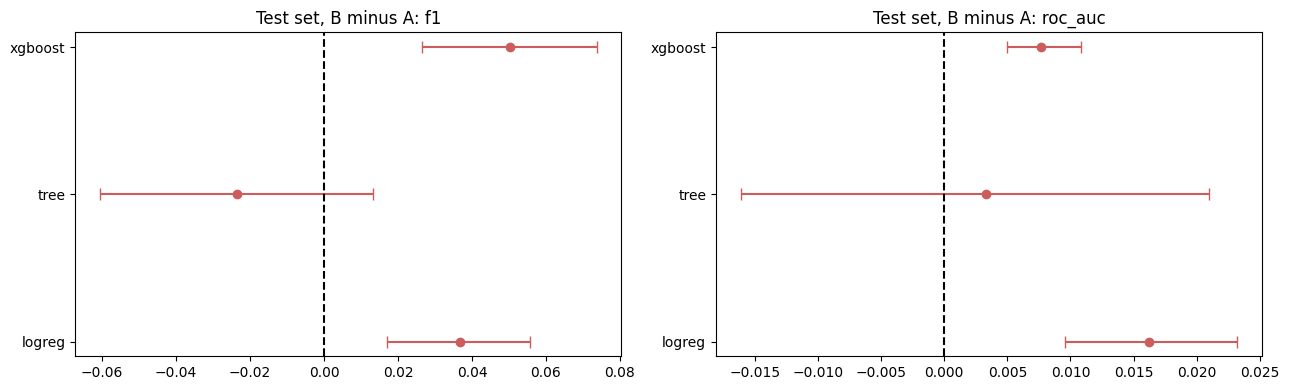

In [60]:
# Forest plot: each dot is B minus A, each bar is the 95% interval. A bar that crosses 0 is not clearly different from 0.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, metric in zip(axes, ["f1", "roc_auc"]):
    subset = bootstrap_table[bootstrap_table["metric"] == metric].reset_index(drop=True)

    for i, row in subset.iterrows():
        ax.errorbar(row["observed_B_minus_A"], i,
                    xerr=[[row["observed_B_minus_A"] - row["ci_low"]], [row["ci_high"] - row["observed_B_minus_A"]]],
                    fmt="o", color="indianred", capsize=4)

    ax.axvline(0, color="black", linestyle="--")
    ax.set_yticks(range(len(subset)))
    ax.set_yticklabels(subset["model"])
    ax.set_title("Test set, B minus A: " + metric)

savefig("14_h1_bootstrap_intervals")

The bootstrap analysis largely confirms the findings from the cross-validation experiments. For Logistic Regression and XGBoost, Feature Set B consistently outperformed Feature Set A, with confidence intervals for F1, ROC-AUC, and PR-AUC remaining above zero. The improvements were particularly pronounced for Logistic Regression in PR-AUC and for XGBoost in both F1-score and recall, suggesting that the trajectory features improved the models' ability to identify customers likely to churn.

In contrast, the Decision Tree model showed no reliable benefit from the additional features. Although the observed differences were sometimes positive and sometimes negative, all confidence intervals included zero, indicating that the apparent performance changes could plausibly be explained by sampling variability in the test set. Overall, the bootstrap results provide further evidence that the trajectory features add meaningful predictive value for Logistic Regression and XGBoost, but offer limited benefit to a single Decision Tree.

## Conclusion for H1

**H1:** Models incorporating trajectory features will significantly outperform models using static features only on churn-class **F1-score** and **ROC-AUC**.

The results provide **partial support** for H1. Across both the repeated cross-validation analysis and the bootstrap confidence interval analysis, **Feature Set B** consistently outperformed **Feature Set A** for the **Logistic Regression** and **XGBoost** models. The observed improvements in both F1-score and ROC-AUC were statistically significant, indicating that the inclusion of trajectory features provided meaningful additional predictive information beyond the static customer attributes.

For the **Decision Tree** model, however, the differences between the two feature sets were comparatively small and did not achieve statistical significance. Although Feature Set B occasionally produced slightly higher performance, the evidence was insufficient to conclude that the trajectory features resulted in a reliable improvement for this algorithm.

Taken together, these findings suggest that behavioural trajectory features can enhance churn prediction performance, particularly when used with models capable of effectively exploiting complex feature relationships. The strongest evidence of benefit was observed for **XGBoost**, followed by **Logistic Regression**, whereas the **Decision Tree** showed limited sensitivity to the additional behavioural information.

Therefore, **H1 is supported for Logistic Regression and XGBoost but not for Decision Tree models**. Overall, the results indicate that incorporating behavioural changes over time improves predictive performance, although the magnitude and statistical significance of the improvement depend on the learning algorithm employed.

# H2: Is a Decline in Transaction Activity Associated with Churn?

**H2:** A decline of more than 20% in transaction count between quarters is positively associated with the likelihood of churn.

This hypothesis examines whether customers who exhibit a substantial reduction in transaction activity are more likely to churn. Unlike **H1**, which focused on predictive model performance, **H2** investigates the relationship between a specific behavioural pattern and customer churn.

To evaluate this hypothesis, two complementary analytical approaches are employed:

1. **Unadjusted Association:** Do customers whose transaction count declines by more than 20% experience higher churn rates than those whose transaction levels remain stable? This relationship is assessed using a contingency table, a chi-square test of association, and an odds ratio.

2. **Adjusted Association:** Does the relationship between declining transaction activity and churn remain after accounting for other customer characteristics and behavioural variables? This is evaluated using logistic regression, which estimates the independent contribution of transaction decline while controlling for potential confounding factors.

Unadjusted associations describe the relationship between an individual predictor and the outcome without accounting for other predictors. Adjusted associations are estimated while controlling for other variables included in the regression model. Comparing these estimates helps assess whether the observed relationship changes after accounting for other factors, although a change after adjustment does not necessarily establish that confounding was present (Andrade, 2024).

Because H2 concerns **association rather than prediction**, all **10,127 customers** are included in the analysis. No train-test split is required, as the objective is to estimate and interpret relationships within the available dataset rather than assess out-of-sample predictive performance.

## Simple comparison

In [61]:
# Customers split by declining (1) / not declining (0) and by churn (1) / stayed (0)
contingency_table = pd.crosstab(df["declining_transactions"], df["churn"])
print(contingency_table)
print()

# Chi-square test of independence
chi2_statistic, chi2_p, chi2_dof, expected_counts = chi2_contingency(contingency_table)

# The four counts, named
declining_churned = contingency_table.loc[1, 1]
declining_stayed = contingency_table.loc[1, 0]
steady_churned = contingency_table.loc[0, 1]
steady_stayed = contingency_table.loc[0, 0]

# Churn rates
rate_declining = declining_churned / (declining_churned + declining_stayed)
rate_steady = steady_churned / (steady_churned + steady_stayed)

# Odds ratio and its 95% confidence interval
odds_ratio = (declining_churned * steady_stayed) / (declining_stayed * steady_churned)
standard_error_log_or = np.sqrt(1 / declining_churned + 1 / declining_stayed + 1 / steady_churned + 1 / steady_stayed)
or_low = np.exp(np.log(odds_ratio) - 1.96 * standard_error_log_or)
or_high = np.exp(np.log(odds_ratio) + 1.96 * standard_error_log_or)

print(f"Churn rate when declining:     {rate_declining:.2%}")
print(f"Churn rate when not declining: {rate_steady:.2%}")
print(f"Relative risk: {rate_declining / rate_steady:.2f}")
print(f"Odds ratio: {odds_ratio:.2f} (95% CI {or_low:.2f} to {or_high:.2f})")
print(f"Chi-square = {chi2_statistic:.2f}, df = {chi2_dof}, p = {chi2_p:.2e}")

churn                      0     1
declining_transactions            
0                       2710   219
1                       5790  1408

Churn rate when declining:     19.56%
Churn rate when not declining: 7.48%
Relative risk: 2.62
Odds ratio: 3.01 (95% CI 2.59 to 3.49)
Chi-square = 224.54, df = 1, p = 9.23e-51


Customers whose transaction count declined by more than 20% between quarters exhibited substantially higher churn rates than customers whose transaction activity remained stable or increased. Specifically, the churn rate was 19.56% among customers with declining transaction activity, compared with 7.48% among other customers.

The association was statistically significant (χ² = 224.54, p < .001). Customers experiencing a decline in transaction activity were 2.62 times more likely to churn, and had approximately three times the odds of churn (OR = 3.01, 95% CI [2.59, 3.49]).

These results provide strong evidence in support of H2, indicating that a decline of more than 20% in transaction count is positively associated with churn.

## Adjusted association: Logistic regression

To determine whether the relationship between declining transaction activity and churn persists after accounting for other customer characteristics, a logistic regression model was fitted with churn as the outcome. The model included `declining_transactions` as the predictor of interest and static customer attributes as control variables.

`Avg_Open_To_Buy` was excluded because it is a direct linear combination of `Credit_Limit` and `Total_Revolving_Bal`, which would introduce perfect multicollinearity. All numeric control variables were standardised prior to estimation. As a result, the odds ratio for `declining_transactions` can be interpreted as the change in churn odds for customers with declining transaction activity relative to those without such a decline, holding all other variables constant.

In [62]:
# all static features except the redundant Avg_Open_To_Buy
static_controls = [column for column in features_a if column != "Avg_Open_To_Buy"]
numeric_controls = [column for column in static_controls if column not in categorical_columns]

# Build the data: controls + the declining flag
h2_data = df[static_controls + ["declining_transactions"]].copy()

# Turn text columns into 0/1 dummy columns
h2_data = pd.get_dummies(h2_data, columns=categorical_columns, drop_first=True).astype(float)

# Standardise the numeric controls (not the 0/1 declining flag)
for column in numeric_controls:
    h2_data[column] = (h2_data[column] - h2_data[column].mean()) / h2_data[column].std()

# Add the intercept and fit the logistic regression
h2_data = sm.add_constant(h2_data)
logit_result = sm.Logit(df["churn"], h2_data).fit(disp=0, maxiter=200)

# Odds ratios with 95% intervals for every variable
full_odds_table = pd.DataFrame({
    "odds_ratio": np.exp(logit_result.params),
    "ci_low": np.exp(logit_result.conf_int()[0]),
    "ci_high": np.exp(logit_result.conf_int()[1]),
    "p_value": logit_result.pvalues
}).round(4)
full_odds_table.to_csv("outputs/tables/" + file_tag + "h2_full_logistic_regression.csv")

# Compare the unadjusted and adjusted odds ratios for declining_transactions
adjusted_row = full_odds_table.loc["declining_transactions"]
h2_table = pd.DataFrame([
    {"version": "unadjusted (simple comparison)", "odds_ratio": odds_ratio, "ci_low": or_low, "ci_high": or_high, "p_value": chi2_p},
    {"version": "adjusted for static variables", "odds_ratio": adjusted_row["odds_ratio"],
    "ci_low": adjusted_row["ci_low"], "ci_high": adjusted_row["ci_high"], "p_value": adjusted_row["p_value"]}
]).round(4)
h2_table.to_csv("outputs/tables/" + file_tag + "h2_odds_ratios.csv", index=False)
h2_table

,version,odds_ratio,ci_low,ci_high,p_value
0,unadjusted (simple comparison),3.0092,2.5913,3.4944,0.0
1,adjusted for static variables,3.2179,2.6708,3.8772,0.0


The unadjusted analysis indicated a strong positive association between declining transaction activity and churn. Customers whose transaction count declined by more than 20% had approximately three times the odds of churning compared with customers who did not experience such a decline (OR = 3.01, 95% CI [2.59, 3.49], p < .001).

This relationship remained strong after controlling for customer demographic and account characteristics in a logistic regression model. The adjusted odds ratio increased slightly to 3.22 (95% CI [2.67, 3.88], p < .001), indicating that customers with declining transaction activity had more than three times the odds of churning, even after accounting for other relevant variables.

The confidence intervals for both estimates exclude 1 and the p-values are highly significant, providing strong evidence that a decline of more than 20% in transaction count is positively associated with churn. These findings therefore support H2.

# RQ2: Which Behavioural Changes Matter Most? (SHAP)

To address **Research Question 2**, SHAP (**SHapley Additive exPlanations**) is used to identify the features that contribute most strongly to churn predictions. SHAP is a model-agnostic interpretability technique that decomposes each prediction into the individual contributions of the input features, showing how each variable increases or decreases the predicted likelihood of churn relative to a baseline prediction.

For each customer, SHAP assigns a contribution value to every feature. Positive SHAP values increase the predicted probability of churn, while negative values decrease it. By aggregating these contributions across all customers, it is possible to obtain a global view of feature importance and identify the factors that most strongly influence model predictions.

The analysis is conducted using **XGBoost Model B**, as this model achieved the strongest predictive performance in the previous evaluation. Examining the best-performing model provides insight into the behavioural and customer characteristics that drive the most accurate churn predictions.

SHAP values are reported in **log-odds units**, meaning that they represent contributions to the model's underlying prediction score before conversion to probabilities. Features with larger average absolute SHAP values exert greater influence on the model's decisions and are therefore considered more important. SHAP explains a prediction by assigning feature contributions based on Shapley values, supporting both global summaries and explanations for individual customers (Lundberg and Lee, 2017).

To assess the robustness of the findings, the SHAP importance rankings are compared with feature importance measures derived from the **Logistic Regression** and **Decision Tree** models. Variables that are consistently identified as important across multiple algorithms provide stronger evidence that their relationship with churn is meaningful rather than an artefact of a particular modelling approach.

In [63]:
def get_clean_feature_names(pipeline):
    # Names of the columns the model actually sees, without the "cat__" / "num__" prefixes
    raw_names = pipeline.named_steps["prep"].get_feature_names_out()
    return [name.replace("cat__", "").replace("num__", "") for name in raw_names]


def get_shap_inputs(pipeline, columns_used, x_data):
    # Run only the first 2 pipeline steps (cap outliers + encode); SMOTE and the model are not applied
    feature_names = get_clean_feature_names(pipeline)
    transformed = pipeline[:2].transform(x_data[columns_used])
    return pd.DataFrame(transformed, columns=feature_names)


# Model B: transform the test customers and compute SHAP values
xgb_b_pipeline = final_models["xgboost_B"]
x_test_b = get_shap_inputs(xgb_b_pipeline, features_b, x_test)
feature_names_b = list(x_test_b.columns)

explainer_b = shap.TreeExplainer(xgb_b_pipeline.named_steps["model"])
shap_values_b = explainer_b.shap_values(x_test_b)

# Some versions return one array per class; keep the churn class
if isinstance(shap_values_b, list):
    shap_values_b = shap_values_b[1]

print("SHAP values shape:", shap_values_b.shape, "(customers x features)")

SHAP values shape: (2026, 34) (customers x features)


## Overall importance

In [64]:
def shap_importance_table(shap_values, feature_names):

    # Average size of each feature's contribution, ignoring direction
    importance = np.abs(shap_values).mean(axis=0)

    table = pd.DataFrame({"feature": feature_names, "mean_abs_shap": importance})
    table = table.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    table["rank"] = table.index + 1
    table["is_trajectory_feature"] = table["feature"].isin(trajectory_features)
    return table


importance_b = shap_importance_table(shap_values_b, feature_names_b)
importance_b.round(4).to_csv("outputs/tables/" + file_tag + "shap_importance_xgboost_B.csv", index=False)
importance_b.head(15).round(4)

,feature,mean_abs_shap,rank,is_trajectory_feature
0,Total_Trans_Ct,3.4144,1,False
1,Total_Trans_Amt,2.0405,2,False
2,Total_Revolving_Bal,0.8939,3,False
3,Total_Relationship_Count,0.6575,4,False
4,inactivity_ratio,0.6501,5,True
5,Total_Amt_Chng_Q4_Q1,0.6453,6,True
6,Total_Ct_Chng_Q4_Q1,0.6067,7,True
7,Contacts_Count_12_mon,0.4269,8,False
8,Customer_Age,0.3118,9,False
9,Months_Inactive_12_mon,0.2663,10,False


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7844\3757308467.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_b, x_test_b, show=False, max_display=15)


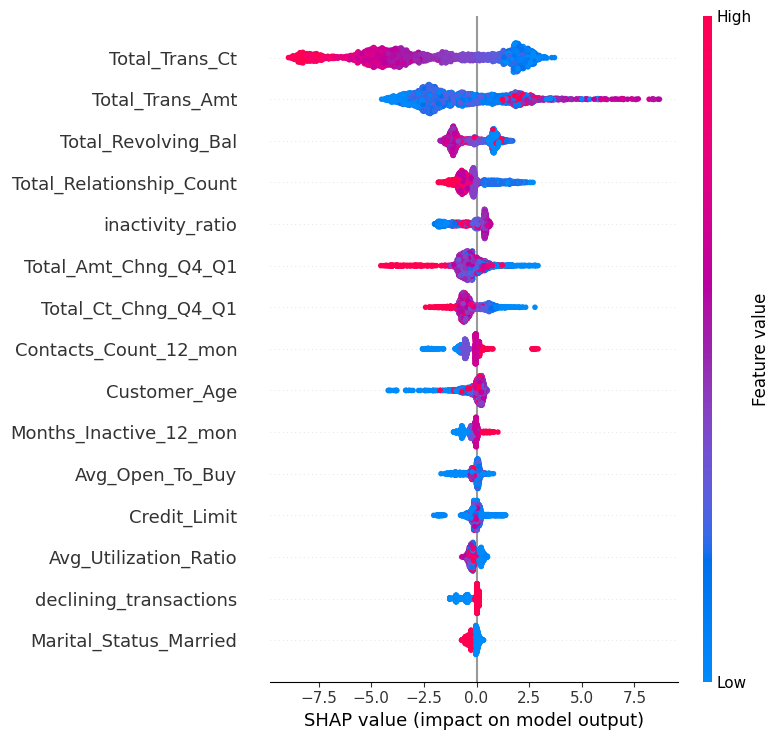

In [65]:
# Beeswarm: each dot is one customer. Red = high feature value, blue = low. Right of 0 = pushes towards churn.
shap.summary_plot(shap_values_b, x_test_b, show=False, max_display=15)
savefig("15_shap_beeswarm_xgboost_B")

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7844\2789291241.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_b, x_test_b, plot_type="bar", show=False, max_display=15)


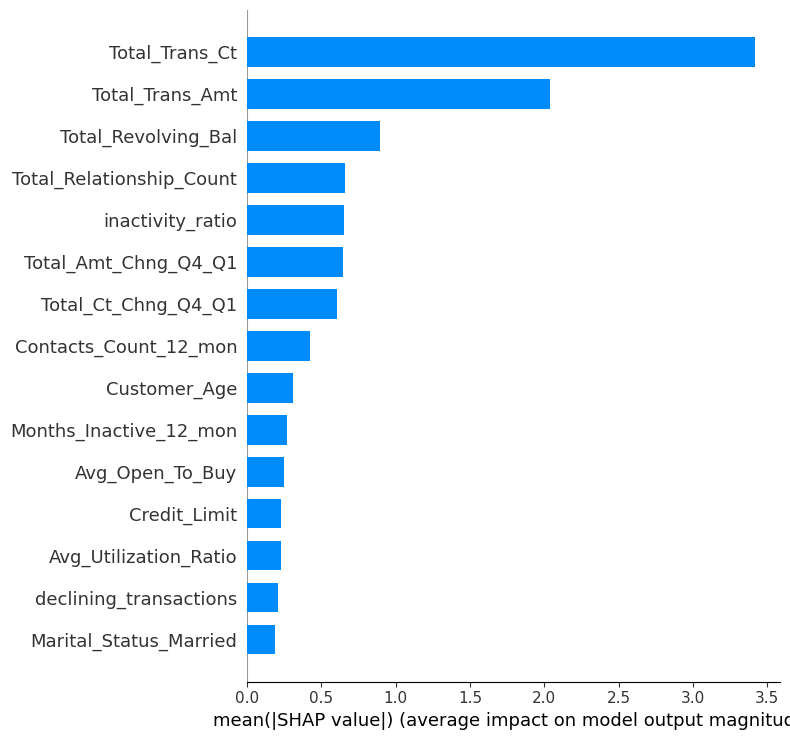

In [66]:
# Bar chart of the average importance
shap.summary_plot(shap_values_b, x_test_b, plot_type="bar", show=False, max_display=15)
savefig("16_shap_bar_xgboost_B")

The SHAP analysis indicates that customer transaction behaviour is the strongest driver of churn predictions in the best-performing model (XGBoost Model B). The two most influential features were `Total_Trans_Ct` and `Total_Trans_Amt`, suggesting that customers' transaction activity provides substantial information about their likelihood of churning.

Importantly, several trajectory features also ranked among the most influential predictors. `inactivity_ratio`, `Total_Amt_Chng_Q4_Q1`, and `Total_Ct_Chng_Q4_Q1` were ranked 5th, 6th, and 7th respectively, while `declining_transactions` ranked 14th. This indicates that changes in customer behaviour over time contribute additional predictive value beyond static customer characteristics.

The SHAP summary plot further shows the direction of these effects. Lower values of `Total_Trans_Ct`, `Total_Trans_Amt`, `Total_Amt_Chng_Q4_Q1`, and `Total_Ct_Chng_Q4_Q1` are generally associated with positive SHAP values, meaning they increase predicted churn risk. Conversely, customers with higher transaction activity and stronger growth in transactions tend to receive lower churn predictions.

Overall, the findings suggest that both current transaction activity and changes in activity over time are important indicators of customer churn. The prominence of multiple trajectory features among the top-ranked predictors provides explanatory support for the performance improvements observed in H1 and is consistent with the positive association identified in H2.

## How the four trajectory features behave

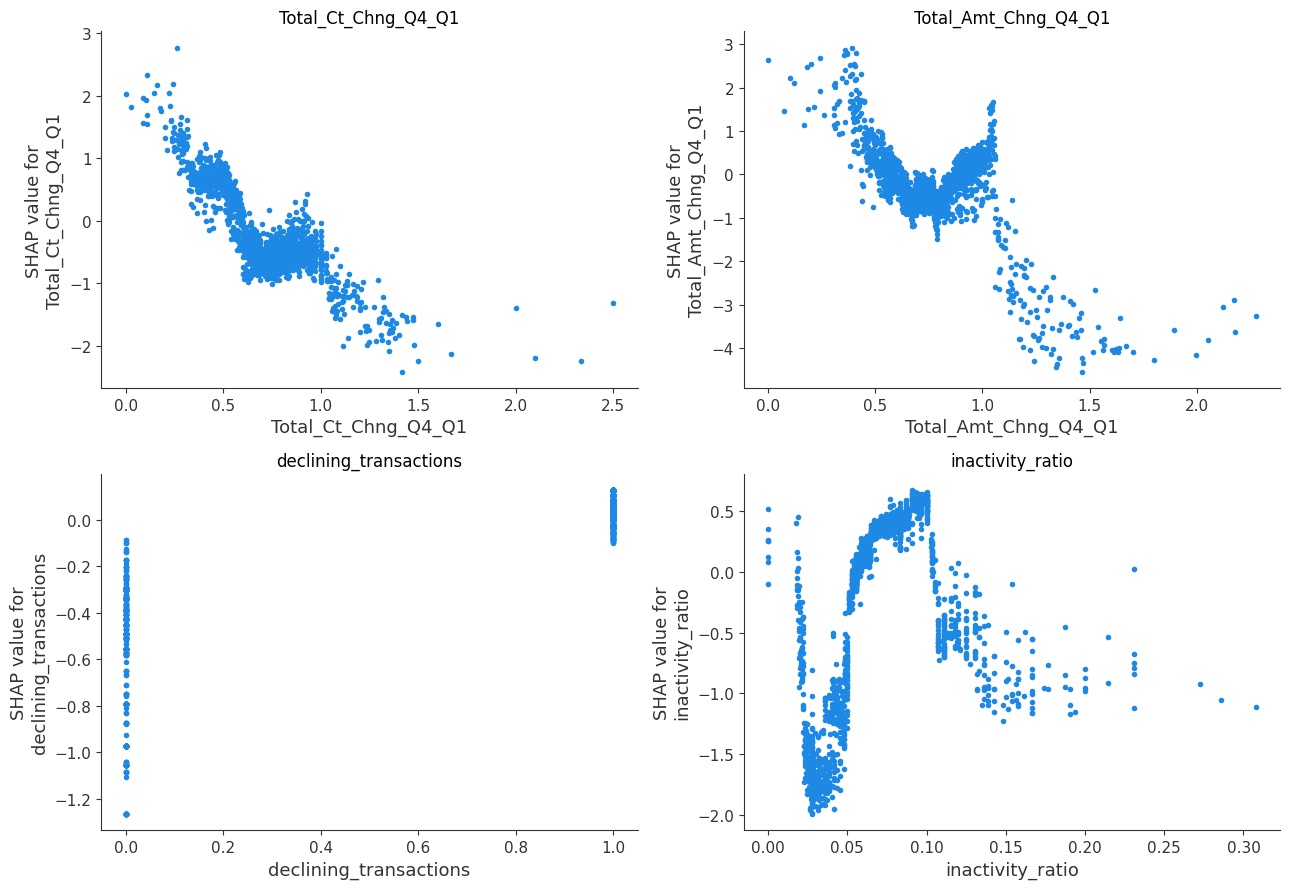

In [67]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

for i, feature in enumerate(trajectory_features):
    shap.dependence_plot(feature, shap_values_b, x_test_b, interaction_index=None, ax=axes[i], show=False)
    axes[i].set_title(feature)

savefig("17_shap_dependence_trajectory_features")

### Interpreting the trajectory features

The SHAP dependence plots provide insight into how the trajectory features influence predicted churn risk in the XGBoost model.

For both `Total_Ct_Chng_Q4_Q1` and `Total_Amt_Chng_Q4_Q1`, lower values are generally associated with positive SHAP values, indicating an increase in predicted churn risk. As transaction count and transaction amount growth increase, SHAP values become increasingly negative, suggesting a reduced likelihood of churn. This pattern is consistent with the expectation that customers whose activity declines over time are more likely to leave.

The binary `declining_transactions` feature shows the same relationship. Customers classified as experiencing a decline greater than 20% generally receive higher churn-risk contributions than customers who do not meet this criterion. While its overall importance is lower than the continuous trajectory variables, the direction of the effect supports the findings from H2.

The `inactivity_ratio` feature displays a non-linear relationship with churn risk. Moderate values are associated with higher predicted churn, while very high values tend to reduce the feature's contribution. This suggests that the impact of inactivity is more complex than a simple linear increase in churn risk.

Overall, the dependence plots indicate that declining customer activity is associated with increased churn risk, while stable or growing activity is associated with customer retention. These findings reinforce the statistical evidence from H1 and H2 and provide a behavioural explanation for why the trajectory-enhanced models achieved superior predictive performance.

## Individual customer explanations

While the previous analysis examined feature importance across all customers, SHAP can also explain individual predictions. Three representative customers were selected from the test set: a likely churner, a likely non-churner, and a borderline case near the classification threshold. Examining these examples helps illustrate how different combinations of feature values contribute to the model's predicted churn risk.

In [68]:
probabilities_b = test_probabilities["xgboost_B"]

# Churner the model is most sure about; non-churner the model is most sure about; the customer closest to 0.5
churner_positions = np.where(y_test_array == 1)[0]
stayer_positions = np.where(y_test_array == 0)[0]

clear_churner = churner_positions[np.argmax(probabilities_b[churner_positions])]
clear_stayer = stayer_positions[np.argmin(probabilities_b[stayer_positions])]
borderline = int(np.argmin(np.abs(probabilities_b - 0.5)))

selected_customers = [("churner", clear_churner), ("non_churner", clear_stayer), ("borderline", borderline)]

for label, position in selected_customers:
    print(f"{label}: predicted churn probability {probabilities_b[position]:.3f}, actual churn = {y_test_array[position]}")

churner: predicted churn probability 1.000, actual churn = 1
non_churner: predicted churn probability 0.000, actual churn = 0
borderline: predicted churn probability 0.508, actual churn = 1


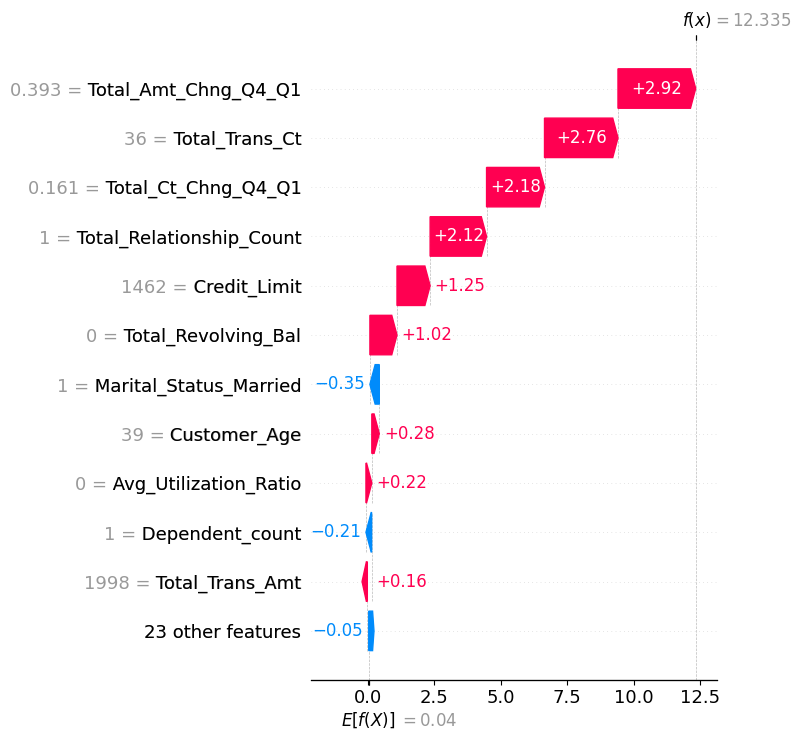

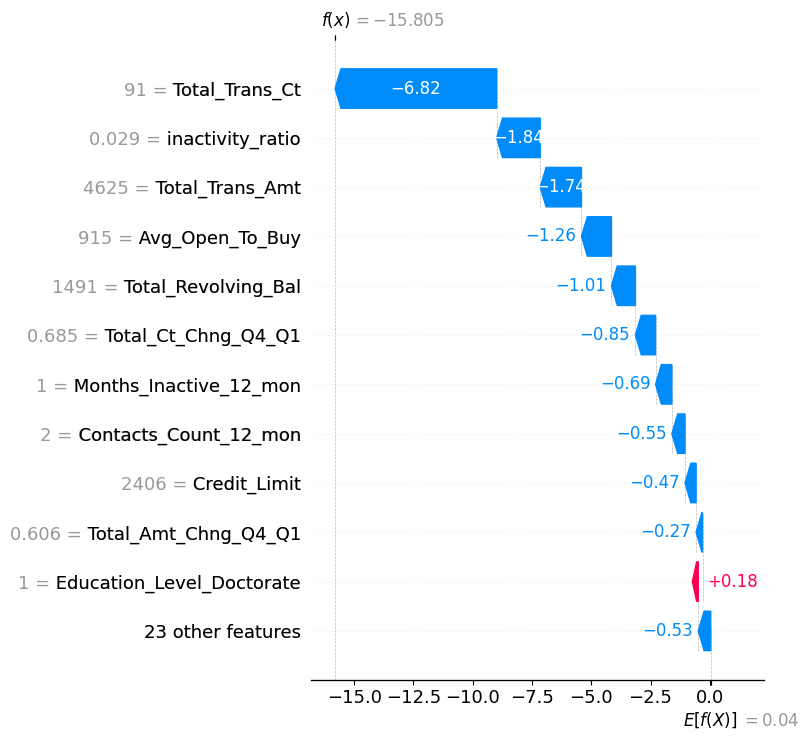

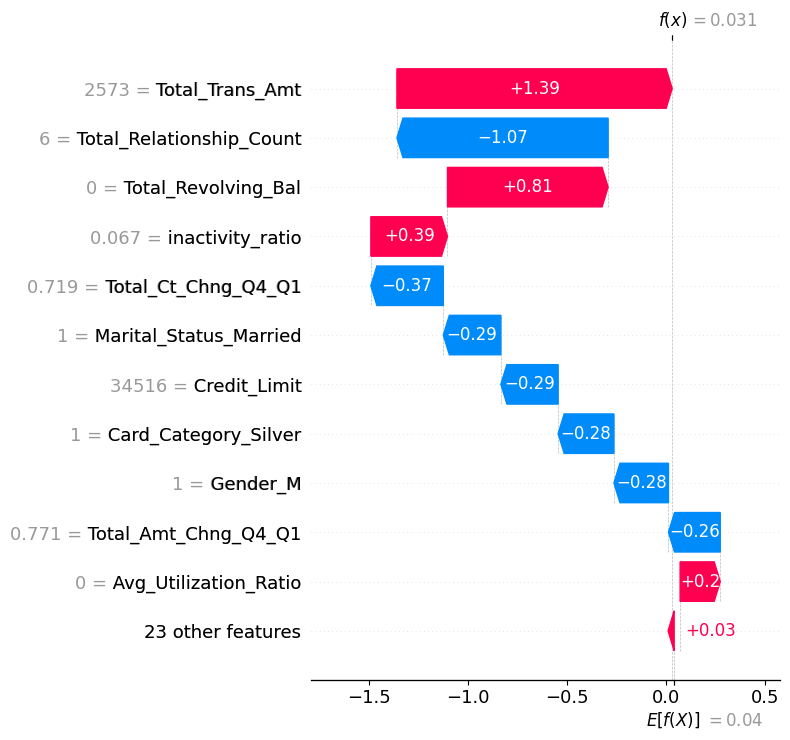

In [69]:
for label, position in selected_customers:

    # Package this one customer's SHAP values for the waterfall plot
    explanation = shap.Explanation(
        values=shap_values_b[position],
        base_values=explainer_b.expected_value,
        data=x_test_b.iloc[position].values,
        feature_names=feature_names_b
    )

    shap.plots.waterfall(explanation, max_display=12, show=False)
    savefig("18_shap_waterfall_" + label)

### Example 1: High-risk customer (predicted churn probability = 1.000)

This customer was assigned an extremely high probability of churn, and the prediction was correct (actual churn = 1). The SHAP explanation shows that several behavioural features strongly increased the predicted churn risk.

The largest contributions came from low transaction activity and declining transaction behaviour, including `Total_Amt_Chng_Q4_Q1`, `Total_Trans_Ct`, and `Total_Ct_Chng_Q4_Q1`. The customer completed only 36 transactions and exhibited substantial declines in both transaction count and transaction amount over time, which pushed the prediction strongly towards churn.

Additional risk factors included a low number of banking relationships (`Total_Relationship_Count = 1`), a low credit limit, and a zero revolving balance. Together, these features increased the model output far above the baseline churn risk.

Overall, the prediction is consistent with the broader findings of the study: customers exhibiting reduced transaction activity and declining engagement are substantially more likely to churn.

## Do the algorithms agree?

XGBoost identified several trajectory features as important drivers of churn. To determine whether this conclusion depends on the choice of algorithm, feature importance rankings are compared across Logistic Regression, Decision Tree, and XGBoost models.

Agreement across the three algorithms would provide stronger evidence that the trajectory features capture meaningful behavioural signals associated with customer churn rather than model-specific patterns.

In [70]:
# Logistic regression (Model B)
logreg_b_pipeline = final_models["logreg_B"]
logreg_coefficients = logreg_b_pipeline.named_steps["model"].coef_[0]
logreg_names = get_clean_feature_names(logreg_b_pipeline)

# Decision tree (Model B)
tree_b_pipeline = final_models["tree_B"]
tree_importances = tree_b_pipeline.named_steps["model"].feature_importances_
tree_names = get_clean_feature_names(tree_b_pipeline)

# All three pipelines should see the same columns in the same order
assert logreg_names == feature_names_b and tree_names == feature_names_b

importance_comparison = pd.DataFrame({
    "feature": feature_names_b,
    "xgboost_mean_abs_shap": importance_b.set_index("feature").loc[feature_names_b, "mean_abs_shap"].values,
    "logreg_abs_coefficient": np.abs(logreg_coefficients),
    "tree_importance": tree_importances
})

# Rank 1 = most important for each method
for column in ["xgboost_mean_abs_shap", "logreg_abs_coefficient", "tree_importance"]:
    importance_comparison["rank_" + column.split("_")[0]] = importance_comparison[column].rank(ascending=False)

importance_comparison = importance_comparison.sort_values("rank_xgboost").reset_index(drop=True)
importance_comparison.round(4).to_csv("outputs/tables/" + file_tag + "importance_cross_check.csv", index=False)
importance_comparison.head(12).round(4)

,feature,xgboost_mean_abs_shap,logreg_abs_coefficient,tree_importance,rank_xgboost,rank_logreg,rank_tree
0,Total_Trans_Ct,3.4144,3.1683,0.5147,1.0,1.0,1.0
1,Total_Trans_Amt,2.0405,1.8332,0.1191,2.0,2.0,2.0
2,Total_Revolving_Bal,0.8939,0.6349,0.0434,3.0,9.0,6.0
3,Total_Relationship_Count,0.6575,0.6699,0.0593,4.0,7.0,5.0
4,inactivity_ratio,0.6501,1.0512,0.0035,5.0,4.0,12.0
5,Total_Amt_Chng_Q4_Q1,0.6453,0.1244,0.0123,6.0,19.0,8.0
6,Total_Ct_Chng_Q4_Q1,0.6067,0.7627,0.0091,7.0,5.0,11.0
7,Contacts_Count_12_mon,0.4269,0.6116,0.0095,8.0,10.0,10.0
8,Customer_Age,0.3118,0.0000,0.0019,9.0,30.0,13.0
9,Months_Inactive_12_mon,0.2663,1.4450,0.0606,10.0,3.0,4.0


In [71]:
# Ranks of the four trajectory features under each method (1 = most important)
importance_comparison[importance_comparison["feature"].isin(trajectory_features)][
    ["feature", "rank_xgboost", "rank_logreg", "rank_tree"]
]

,feature,rank_xgboost,rank_logreg,rank_tree
4,inactivity_ratio,5.0,4.0,12.0
5,Total_Amt_Chng_Q4_Q1,6.0,19.0,8.0
6,Total_Ct_Chng_Q4_Q1,7.0,5.0,11.0
13,declining_transactions,14.0,21.0,3.0


The trajectory features ranked as moderately to highly important in all three algorithms, but which of them mattered most differed by algorithm, so the agreement is only partial.

`inactivity_ratio` and `Total_Ct_Chng_Q4_Q1` were ranked among the most influential features by both XGBoost and Logistic Regression, while `declining_transactions` was particularly important for the Decision Tree model. Although the models differed in how strongly they weighted individual trajectory features, each algorithm assigned high importance to at least one measure of declining customer activity.

This suggests that behavioural change contains useful information about churn risk, but the evidence is partial. Total_Trans_Ct and Total_Trans_Amt rank first and second in all three algorithms, no single trajectory feature is top-ranked by all three, and declining_transactions ranks 14th for XGBoost and 21st for logistic regression. The rankings support the predictive findings but do not by themselves show that these features capture customer disengagement.

## Logistic regression coefficients

Logistic regression provides an interpretable view of how each feature is associated with churn risk. Positive coefficients indicate that higher values of a feature are associated with increased odds of churn, while negative coefficients indicate reduced odds of churn.

Logistic regression coefficients represent changes in the log-odds of the outcome associated with a one-unit increase in a predictor, holding the other predictors constant. Exponentiating a coefficient, using exp(β), converts it into an odds ratio. An odds ratio greater than one indicates higher odds of the outcome, while an odds ratio below one indicates lower odds, relative to the relevant comparison (Easter and Hemming, 2021).

Because the model uses L1 regularisation, some coefficients may be exactly zero. This indicates that the feature did not contribute additional predictive information and was effectively excluded from the final model.

In [72]:
logreg_table = pd.DataFrame({
    "feature": logreg_names,
    "coefficient": logreg_coefficients,
    "odds_ratio": np.exp(logreg_coefficients)
})
logreg_table["abs_coefficient"] = logreg_table["coefficient"].abs()
logreg_table = logreg_table.sort_values("abs_coefficient", ascending=False).drop(columns="abs_coefficient")
logreg_table.round(4).to_csv("outputs/tables/" + file_tag + "logreg_B_coefficients.csv", index=False)
logreg_table.head(15).round(4)

,feature,coefficient,odds_ratio
27,Total_Trans_Ct,-3.1683,0.0421
26,Total_Trans_Amt,1.8332,6.2540
28,Months_Inactive_12_mon,1.4450,4.2419
33,inactivity_ratio,-1.0512,0.3495
30,Total_Ct_Chng_Q4_Q1,-0.7627,0.4664
0,Gender_M,-0.7010,0.4961
21,Total_Relationship_Count,-0.6699,0.5117
20,Months_on_book,-0.6552,0.5194
23,Total_Revolving_Bal,-0.6349,0.5300
29,Contacts_Count_12_mon,0.6116,1.8433


The logistic regression coefficients indicate that customer transaction behaviour and engagement are the strongest predictors of churn. The largest effects were observed for `Total_Trans_Ct`, `Total_Trans_Amt`, and `Months_Inactive_12_mon`, highlighting the importance of customer activity levels.

`inactivity_ratio` and `Total_Ct_Chng_Q4_Q1` ranked 4th and 5th in terms of coefficient magnitude, suggesting that changes in customer behaviour over time provide information beyond static customer attributes. However, `inactivity_ratio` is calculated from `Months_Inactive_12_mon` and `Months_on_book`, which are also in the model, so its negative coefficient partly offsets the positive coefficient on `Months_Inactive_12_mon` and should not be interpreted on its own. In particular, the negative coefficient for `Total_Ct_Chng_Q4_Q1` suggests that customers with stronger growth or stability in transaction counts are less likely to churn, whereas customers exhibiting declining transaction activity face higher churn risk.

The direction of these effects is consistent with the SHAP analysis and the results for H2. Features associated with reduced engagement, such as lower transaction activity and a higher number of inactive months, were associated with increased churn risk, while stronger customer engagement was associated with customer retention.

Overall, the logistic regression model supports the conclusion that trajectory-based behavioural features contribute meaningfully to understanding and predicting churn.

# H3: Does XGBoost provide the best performance, while logistic regression offers the greatest interpretability?

**H3:** XGBoost will achieve the highest predictive performance among the three algorithms, while logistic regression will provide the greatest interpretability.

H3 contains two related claims. The first concerns predictive performance, and the second concerns model interpretability.

### Part 1: Predictive performance

The three algorithms are first compared using their performance on the held-out test set. To determine whether any observed advantage for XGBoost is statistically reliable rather than due to sampling variation, pairwise comparisons are then performed using the repeated cross-validation results from Model B.

The analysis evaluates whether XGBoost significantly outperforms Logistic Regression and Decision Tree models on the primary evaluation metrics (F1-score and ROC-AUC).

In [73]:
# Test-set ranking of the three Model B versions
model_b_ranking = master_table[master_table["features"] == "B"][["model", "f1", "roc_auc", "pr_auc", "recall", "precision", "accuracy"]]
model_b_ranking.sort_values("f1", ascending=False)

,model,f1,roc_auc,pr_auc,recall,precision,accuracy
5,xgboost,0.9111,0.9930,0.9687,0.8831,0.9410,0.9724
3,tree,0.7300,0.9419,0.7570,0.8154,0.6608,0.9033
1,logreg,0.6558,0.9230,0.7421,0.8062,0.5527,0.8643


In [74]:
h3_rows = []

for rival in ["logreg", "tree"]:
    for metric in ["roc_auc", "f1"]:

        # XGBoost minus the rival, on every split (Model B for both)
        result = compare_scores(cv_scores["xgboost_B"][metric], cv_scores[rival + "_B"][metric])

        row = {"comparison": "xgboost minus " + rival, "metric": metric}
        row.update(result)
        h3_rows.append(row)

h3_table = pd.DataFrame(h3_rows)
h3_table["p_holm"] = multipletests(h3_table["corrected_t_p"].fillna(1.0), method="holm")[1]
h3_table = h3_table.round(4)
h3_table.to_csv("outputs/tables/" + file_tag + "h3_xgboost_vs_rivals.csv", index=False)
h3_table

,comparison,metric,mean_difference,ci_low,ci_high,corrected_t_p,splits_first_better,splits,p_holm
0,xgboost minus logreg,roc_auc,0.0664,0.0592,0.0736,0.0,25,25,0.0
1,xgboost minus logreg,f1,0.2619,0.2424,0.2813,0.0,25,25,0.0
2,xgboost minus tree,roc_auc,0.0430,0.0330,0.0531,0.0,25,25,0.0
3,xgboost minus tree,f1,0.1344,0.1133,0.1554,0.0,25,25,0.0


The held-out test set results show a clear ranking of model performance. XGBoost achieved the highest scores across all evaluation metrics, including F1-score (0.9111), ROC-AUC (0.9930), PR-AUC (0.9687), accuracy (0.9724), precision (0.9410), and recall (0.8831). The Decision Tree ranked second, while Logistic Regression produced the lowest predictive performance.

To determine whether these differences were statistically reliable, XGBoost was compared against both competing algorithms using corrected paired t-tests on the repeated cross-validation results. Across both primary evaluation metrics (F1-score and ROC-AUC), XGBoost significantly outperformed Logistic Regression and Decision Tree.

The performance advantage was substantial. Relative to Logistic Regression, XGBoost improved ROC-AUC by an average of 0.0664 and F1-score by 0.2619 across the 25 cross-validation splits. Relative to Decision Tree, XGBoost improved ROC-AUC by 0.0430 and F1-score by 0.1344. In all four comparisons, the confidence intervals remained entirely above zero, XGBoost outperformed the competing model in all 25 splits, and the Holm-adjusted p-values were below 0.001.

These findings provide strong evidence that XGBoost achieved superior predictive performance compared with both Logistic Regression and Decision Tree models.

### Part 2: Interpretability

Interpretability was assessed by examining how easily each model's predictions can be explained.

Logistic Regression provides the most direct interpretation, as each feature is associated with a single coefficient that quantifies its relationship with churn. Decision Trees remain relatively interpretable because predictions can be traced through a sequence of explicit if-then decision rules. In contrast, XGBoost achieves higher predictive performance at the cost of greater complexity. Because it is an ensemble of many trees, its behaviour is not easily understood from the model structure alone and requires post-hoc explanation methods such as SHAP.

The figure below shows the upper levels of the Model B Decision Tree, illustrating the decision rules used to classify customers.

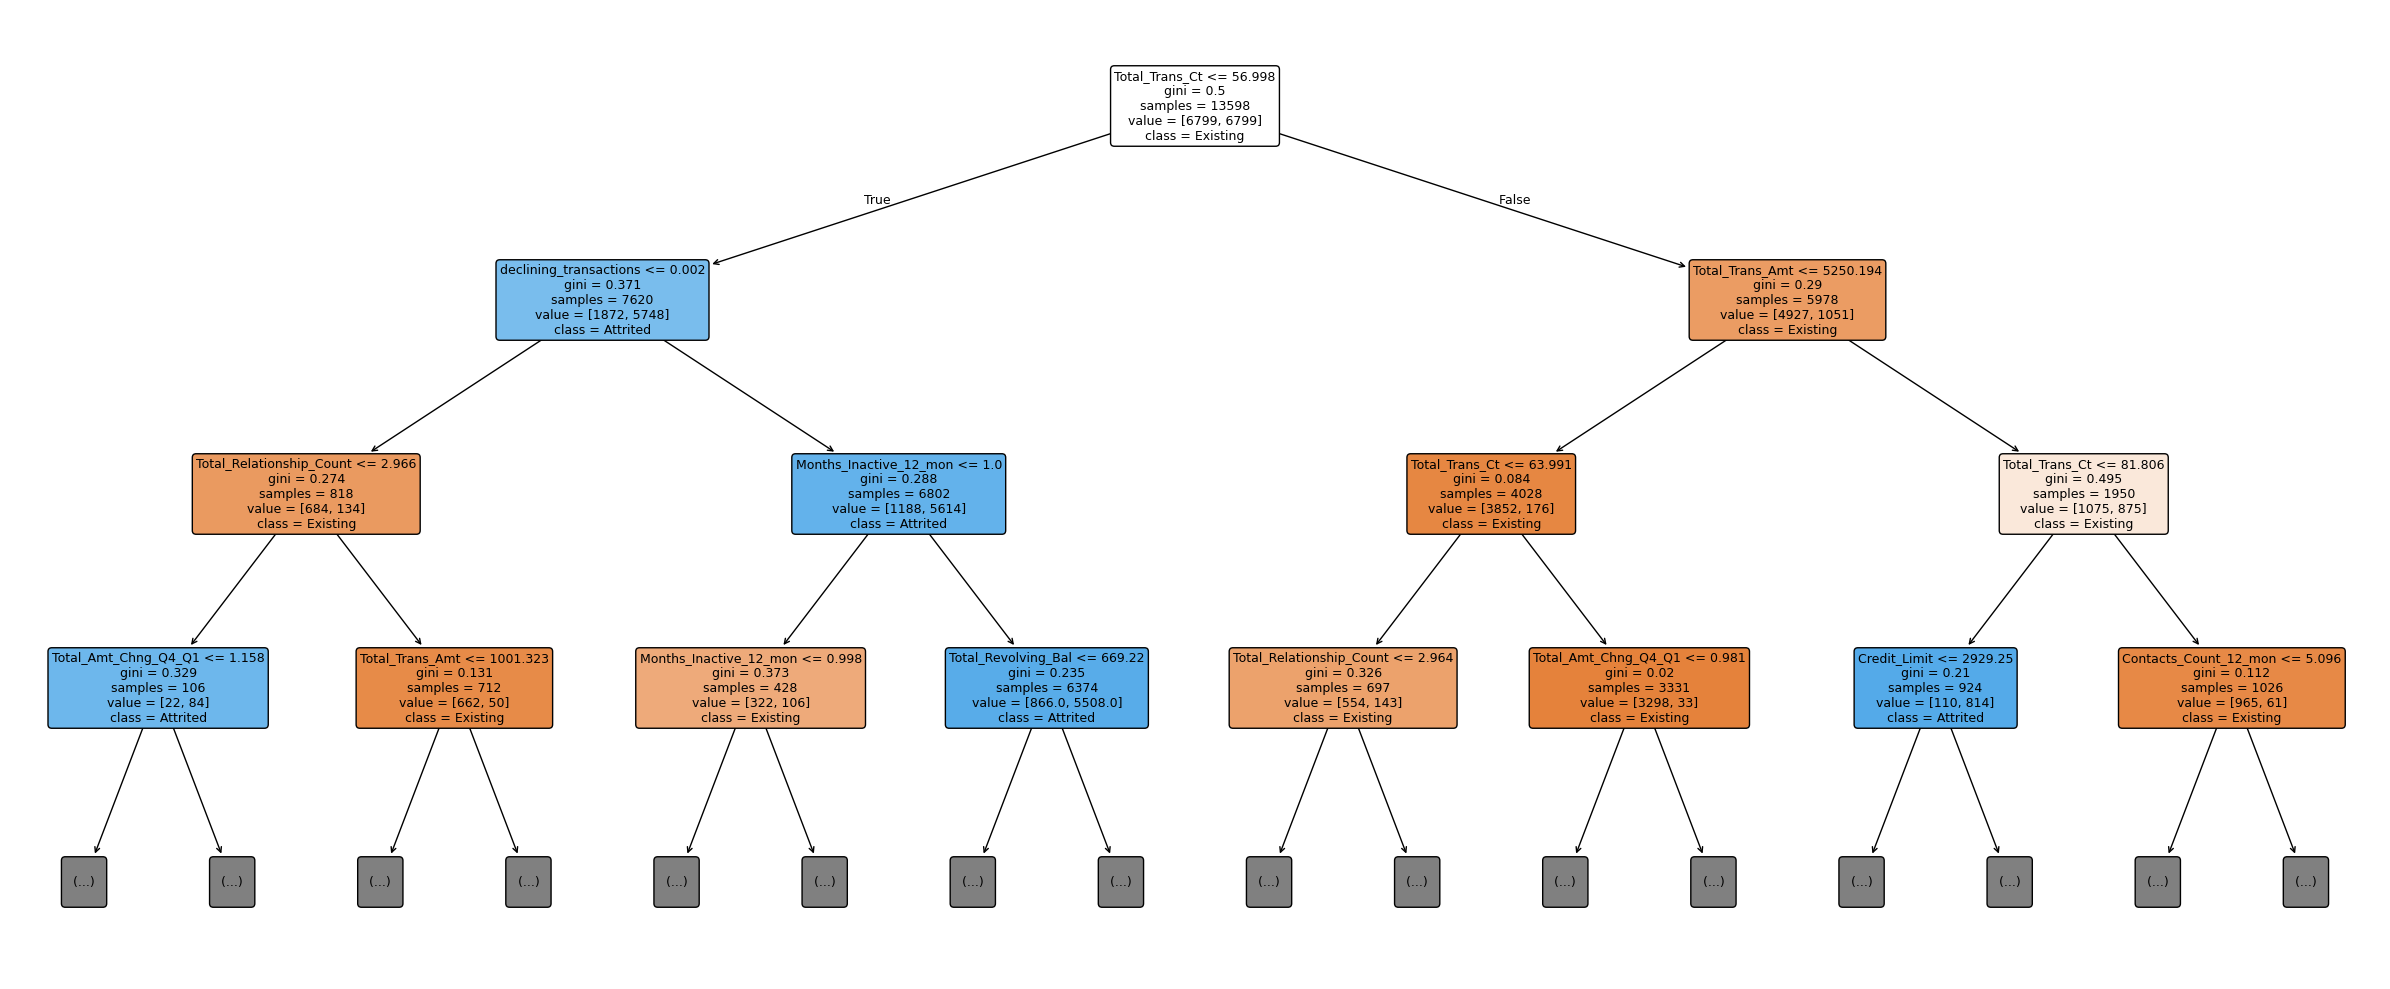

In [75]:
fig = plt.figure(figsize=(24, 10))

plot_tree(
    tree_b_pipeline.named_steps["model"],
    feature_names=feature_names_b,
    class_names=["Existing", "Attrited"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

savefig("20_decision_tree_top_levels")

The Decision Tree provides interpretable decision rules that can be followed directly from the tree structure. For example, the highest-level splits are based on transaction count, transaction decline, transaction amount, and inactivity, indicating that customer engagement measures are central to the model's decisions.

However, even a moderately sized tree quickly becomes difficult to interpret in its entirety, as many branches and interacting rules must be considered simultaneously. Logistic Regression offers a more concise explanation, with each feature represented by a single coefficient and odds ratio that quantify its relationship with churn.

In contrast, XGBoost achieves superior predictive performance but cannot be interpreted directly from the model structure. Understanding its predictions requires additional explainability techniques such as SHAP.

These findings support the second component of H3: Logistic Regression provides the most transparent and easily interpretable representation of the factors associated with churn, while XGBoost provides the strongest predictive performance.

### Conclusion for H3

H3 was supported.

XGBoost achieved the strongest predictive performance across all evaluation metrics and significantly outperformed both Logistic Regression and Decision Tree models on ROC-AUC and F1-score. XGBoost Model B also had the highest F1 and ROC-AUC in every robustness variant (see the auc_B and f1_B columns of the robustness table), although those checks compared Model B with Model A rather than testing XGBoost against the other algorithms directly.

At the same time, Logistic Regression provided the greatest interpretability. The model expressed the effect of each feature through a single coefficient and odds ratio, enabling direct assessment of the direction and magnitude of feature relationships with churn. While Decision Trees offered interpretable decision rules, their complexity increased rapidly with tree size. XGBoost required additional explanation techniques such as SHAP to make its predictions understandable.

These results illustrate the expected trade-off between predictive performance and interpretability: XGBoost provided the highest accuracy, whereas Logistic Regression provided the clearest explanations.

# Robustness checks

The main analyses showed that Feature Set B outperformed Feature Set A. The purpose of the robustness checks is to determine whether this conclusion remains stable under alternative, but reasonable, modelling choices.

Each check modifies one aspect of the analysis while keeping all other settings fixed. To isolate the effect of the change, the previously tuned hyperparameters and the same 25 cross-validation splits are reused throughout. The key quantities of interest are `delta_auc` and `delta_f1`, which represent the performance difference between Feature Set B and Feature Set A (B − A). Positive values indicate that the trajectory features improve predictive performance.

| Check | Purpose |
|----------|----------|
| Decline threshold | Tests whether the results depend on defining a substantial decline as 20% (thresholds of 0.6, 0.7, 0.8, and 0.9 are evaluated). |
| Feature ablation | Tests whether the improvement is driven by the raw change variables, the engineered trajectory variables, or the combination of both. |
| Imbalance handling | Tests whether the results depend on the use of SMOTE by replacing it with class weighting. |

Robustness checks assess whether conclusions remain stable under reasonable alternative modelling choices, an important part of avoiding misleading conclusions from machine-learning experiments (Lones, 2024).

In [76]:
robustness_rows = []

def add_robustness_rows(check, variant, scores_a, scores_b):

    # scores_a and scores_b are dictionaries: model name -> table of split scores
    for model_name in model_names:
        auc_a = scores_a[model_name]["roc_auc"].mean()
        auc_b = scores_b[model_name]["roc_auc"].mean()
        f1_a = scores_a[model_name]["f1"].mean()
        f1_b = scores_b[model_name]["f1"].mean()

        robustness_rows.append({
            "check": check, "variant": variant, "model": model_name,
            "auc_A": auc_a, "auc_B": auc_b, "delta_auc": auc_b - auc_a,
            "f1_A": f1_a, "f1_B": f1_b, "delta_f1": f1_b - f1_a
        })


# The main analysis, for comparison
main_scores_a = {model_name: cv_scores[model_name + "_A"] for model_name in model_names}
main_scores_b = {model_name: cv_scores[model_name + "_B"] for model_name in model_names}
add_robustness_rows("main analysis", "default settings", main_scores_a, main_scores_b)

## Check 1: Sensitivity to the decline threshold

H2 defined declining transaction activity as a reduction of more than 20% between quarters (a threshold of 0.8). This robustness check evaluates whether the findings depend on that specific choice.

The first table shows how many customers are classified as declining at each threshold and reports the corresponding odds ratio for churn. The second table re-evaluates Model B after rebuilding the `declining_transactions` feature using each alternative threshold.

The key question is whether Feature Set B continues to outperform Feature Set A across a range of reasonable threshold values. The 0.8 threshold corresponds to the main analysis and serves as a consistency check.


In [77]:
threshold_rows = []

for threshold in [0.6, 0.7, 0.8, 0.9]:

    # How many customers does this threshold flag, and what is the simple odds ratio?
    flag = (df["Total_Ct_Chng_Q4_Q1"] < threshold).astype(int)
    table = pd.crosstab(flag, df["churn"])
    simple_or = (table.loc[1, 1] * table.loc[0, 0]) / (table.loc[1, 0] * table.loc[0, 1])
    threshold_rows.append({"threshold": threshold, "share_flagged": flag.mean(),
                        "churn_rate_flagged": df.loc[flag == 1, "churn"].mean(),
                        "churn_rate_not_flagged": df.loc[flag == 0, "churn"].mean(),
                        "odds_ratio": simple_or})

    # Rebuild the flag in the training data and re-evaluate Model B
    x_variant = x_train.copy()
    x_variant["declining_transactions"] = (x_variant["Total_Ct_Chng_Q4_Q1"] < threshold).astype(int)

    scores_b = {}
    for model_name in model_names:
        scores_b[model_name] = repeated_cv_scores(
            final_models[model_name + "_B"], features_b, x_variant, y_train, fold_splits
        )

    add_robustness_rows("decline threshold", "threshold = " + str(threshold), main_scores_a, scores_b)

pd.DataFrame(threshold_rows).round(4)

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penal

,threshold,share_flagged,churn_rate_flagged,churn_rate_not_flagged,odds_ratio
0,0.6,0.2773,0.3583,0.0848,6.0214
1,0.7,0.4936,0.2466,0.0768,3.9338
2,0.8,0.7108,0.1956,0.0748,3.0092
3,0.9,0.8537,0.1757,0.0729,2.7119


The association between declining transaction activity and churn remained positive across all threshold values. Regardless of where the threshold was set, customers classified as experiencing a decline exhibited substantially higher churn rates than customers who were not classified as declining.

As the threshold became more restrictive (0.6), fewer customers were flagged (27.7%), but the identified group exhibited the highest churn rate (35.8%) and the strongest association with churn (OR = 6.02). In contrast, higher thresholds (0.8 and 0.9) flagged a much larger proportion of customers (71.1% and 85.4%, respectively), but the association became weaker (OR = 3.01 and OR = 2.71).

These results suggest that larger declines in transaction activity are associated with greater churn risk. However, the positive relationship between declining activity and churn is robust to the exact threshold used. The 0.8 threshold adopted in the main analysis provides a reasonable balance between identifying a meaningful behavioural decline and retaining sufficient coverage of the customer base.

## Check 2: Feature ablation

This robustness check examines whether the performance improvement observed in Model B is driven primarily by the original behavioural change variables or by the engineered trajectory features. Feature ablation is used to evaluate how removing a particular feature or group of features affects predictive performance. By comparing models under otherwise consistent experimental conditions, the contribution of the selected feature group can be investigated (Fostiropoulos and Itti, 2023).

Three feature sets are compared:

- **A + raw:** Feature Set A plus the original dataset variables `Total_Ct_Chng_Q4_Q1` and `Total_Amt_Chng_Q4_Q1`.
- **A + engineered:** Feature Set A plus the engineered features `declining_transactions` and `inactivity_ratio`.
- **B:** Feature Set A plus all four trajectory features.

The objective is to determine whether the engineered features contribute predictive value beyond the raw change variables or whether both feature types are required to achieve the strongest performance.

To ensure a fair comparison, all variants reuse the hyperparameters and cross-validation splits from the main Model B analysis.

In [78]:
raw_change_columns = ["Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1"]
engineered_columns = ["declining_transactions", "inactivity_ratio"]

feature_sets["A_plus_raw"] = features_a + raw_change_columns
feature_sets["A_plus_engineered"] = features_a + engineered_columns

ablation_scores = {}

for variant in ["A_plus_raw", "A_plus_engineered"]:

    ablation_scores[variant] = {}

    for model_name in model_names:

        # Build a pipeline for this feature list and give it Model B's tuned settings
        pipeline = build_pipeline(model_name, variant)
        pipeline.set_params(**searches[model_name + "_B"].best_params_)

        ablation_scores[variant][model_name] = repeated_cv_scores(
            pipeline, feature_sets[variant], x_train, y_train, fold_splits
        )

    add_robustness_rows("feature ablation", variant, main_scores_a, ablation_scores[variant])

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penal

In [79]:
# Does the engineering add anything beyond the raw change columns?
# We compare Model B (all four trajectory features) with "A + raw" (only the two columns that came with the dataset).
ablation_rows = []

for model_name in model_names:
    for metric in ["roc_auc", "f1"]:

        # B minus (A + raw) on each of the 25 splits
        result = compare_scores(cv_scores[model_name + "_B"][metric], ablation_scores["A_plus_raw"][model_name][metric])

        row = {"model": model_name, "metric": metric}
        row.update(result)
        ablation_rows.append(row)

ablation_table = pd.DataFrame(ablation_rows)
ablation_table["p_holm"] = multipletests(ablation_table["corrected_t_p"].fillna(1.0), method="holm")[1]
ablation_table = ablation_table.round(4)
ablation_table.to_csv("outputs/tables/" + file_tag + "robustness_ablation_tests.csv", index=False)
ablation_table

,model,metric,mean_difference,ci_low,ci_high,corrected_t_p,splits_first_better,splits,p_holm
0,logreg,roc_auc,0.0016,0.0006,0.0027,0.0031,24,25,0.0188
1,logreg,f1,0.0020,-0.0047,0.0087,0.5447,15,25,1.0000
2,tree,roc_auc,0.0013,-0.0041,0.0066,0.6268,15,25,1.0000
3,tree,f1,-0.0037,-0.0239,0.0166,0.7122,11,25,1.0000
4,xgboost,roc_auc,0.0001,-0.0005,0.0007,0.8158,12,25,1.0000
5,xgboost,f1,-0.0005,-0.0108,0.0098,0.9280,9,25,1.0000


The engineered trajectory features provided little additional benefit once the original change variables (`Total_Ct_Chng_Q4_Q1` and `Total_Amt_Chng_Q4_Q1`) were already included in the model.

Across all three algorithms, the differences between Feature Set B and the "A + raw" configuration were extremely small. For Decision Tree and XGBoost, neither ROC-AUC nor F1-score showed statistically significant improvements. Although Logistic Regression exhibited a small increase in ROC-AUC, the effect size was negligible (+0.0016) and no significant improvement was observed for F1-score.

These findings suggest that most of the predictive value captured by the engineered trajectory features is already contained within the original change variables provided in the dataset. Consequently, the performance gains observed for Feature Set B appear to be driven primarily by the inclusion of behavioural change information rather than by the specific engineering of additional trajectory variables.

## Check 3: Class weights instead of SMOTE

he main analysis addressed class imbalance using SMOTE. This robustness check evaluates whether the conclusions depend on that choice by replacing SMOTE with class weighting.

Under this approach, churned customers are given greater importance during model training, while no synthetic observations are created. Logistic Regression and Decision Tree use balanced class weights, while XGBoost uses a corresponding positive-class weighting scheme.

All other aspects of the analysis, including the tuned hyperparameters and the 25 cross-validation splits, remain unchanged. If Feature Set B continues to outperform Feature Set A, the findings can be considered robust to the method used for handling class imbalance.

SMOTE and class weighting address class imbalance differently: SMOTE generates synthetic minority examples, whereas class weighting increases the training penalty associated with misclassifying minority-class observations (Chawla *et al*., 2002; Lemaître *et al*., 2017).

In [80]:
# How many non-churners per churner 
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()

weighted_scores = {"A": {}, "B": {}}

for feature_set in ["A", "B"]:
    for model_name in model_names:

        # Copy the tuned pipeline, switch SMOTE off, and use class weights instead
        pipeline = clone(final_models[model_name + "_" + feature_set])
        pipeline.set_params(smote="passthrough")

        if model_name == "xgboost":
            pipeline.set_params(model__scale_pos_weight=imbalance_ratio)
        else:
            pipeline.set_params(model__class_weight="balanced")

        weighted_scores[feature_set][model_name] = repeated_cv_scores(
            pipeline, feature_sets[feature_set], x_train, y_train, fold_splits
        )

add_robustness_rows("imbalance handling", "class weights instead of SMOTE", weighted_scores["A"], weighted_scores["B"])

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penal

## Robustness summary

In [81]:
robustness_table = pd.DataFrame(robustness_rows).round(4)
robustness_table.to_csv("outputs/tables/" + file_tag + "robustness_summary.csv", index=False)
robustness_table

,check,variant,model,auc_A,auc_B,delta_auc,f1_A,f1_B,delta_f1
0,main analysis,default settings,logreg,0.9145,0.9275,0.0130,0.6194,0.6539,0.0345
1,main analysis,default settings,tree,0.9503,0.9509,0.0006,0.7681,0.7814,0.0133
2,main analysis,default settings,xgboost,0.9875,0.9939,0.0064,0.8725,0.9158,0.0433
3,decline threshold,threshold = 0.6,logreg,0.9145,0.9280,0.0135,0.6194,0.6542,0.0348
4,decline threshold,threshold = 0.6,tree,0.9503,0.9448,-0.0055,0.7681,0.7705,0.0024
5,decline threshold,threshold = 0.6,xgboost,0.9875,0.9940,0.0065,0.8725,0.9169,0.0445
6,decline threshold,threshold = 0.7,logreg,0.9145,0.9276,0.0131,0.6194,0.6533,0.0338
7,decline threshold,threshold = 0.7,tree,0.9503,0.9528,0.0025,0.7681,0.7765,0.0084
8,decline threshold,threshold = 0.7,xgboost,0.9875,0.9939,0.0064,0.8725,0.9141,0.0417
9,decline threshold,threshold = 0.8,logreg,0.9145,0.9275,0.0130,0.6194,0.6539,0.0345


In [82]:
# Share of variants in which Model B beat Model A, for each algorithm
variants_only = robustness_table[robustness_table["check"] != "main analysis"]

print("Number of variants checked per algorithm:", len(variants_only) // len(model_names))
print()
variants_only.groupby("model")[["delta_auc", "delta_f1"]].agg(lambda column: (column > 0).mean()).round(2)

Number of variants checked per algorithm: 7



,delta_auc,delta_f1
model,,
logreg,1.00,1.00
tree,0.43,0.86
xgboost,1.00,1.00


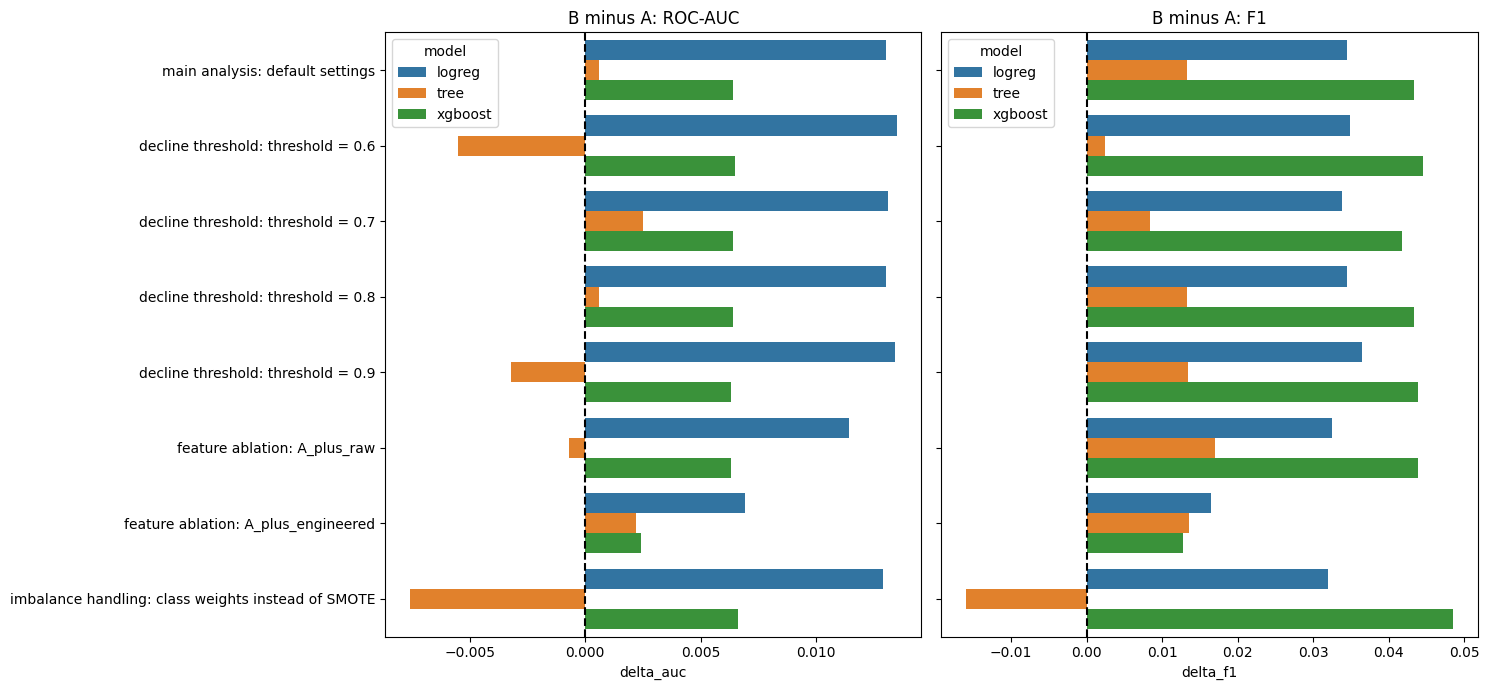

In [83]:
# Plot B minus A for every variant
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

plot_data = robustness_table.copy()
plot_data["label"] = plot_data["check"] + ": " + plot_data["variant"]

for ax, column, title in [(axes[0], "delta_auc", "B minus A: ROC-AUC"), (axes[1], "delta_f1", "B minus A: F1")]:
    sns.barplot(data=plot_data, x=column, y="label", hue="model", ax=ax)
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(title)
    ax.set_ylabel("")

axes[1].set_yticklabels([])
savefig("21_robustness_B_minus_A")

The robustness analyses indicate that the main findings are stable across a range of reasonable modelling choices. For Logistic Regression and XGBoost, Feature Set B outperformed Feature Set A in every robustness variant tested, resulting in positive differences for both ROC-AUC and F1-score across all seven scenarios.

The strongest evidence of robustness comes from the threshold and class-imbalance checks. Varying the definition of declining transaction activity had minimal impact on the performance gains associated with Feature Set B, and replacing SMOTE with class weighting left the logistic regression and XGBoost results essentially unchanged (B minus A in F1: +0.0319 and +0.0485), but reversed the decision tree's F1 difference (−0.0160).

The feature ablation analysis suggests that much of the predictive value originates from the raw behavioural change variables included in the original dataset. The full feature set performed no better than A + raw: the direct comparison found no significant difference except a negligible ROC-AUC gain for logistic regression (+0.0016). The engineered features therefore add little beyond the raw change variables.

The Decision Tree model showed less stable behaviour, with Feature Set B improving performance in most F1 comparisons but not consistently improving ROC-AUC. This is consistent with earlier findings that the trajectory features are more effectively exploited by Logistic Regression and XGBoost than by a single Decision Tree.

Overall, for logistic regression and XGBoost the benefit of behavioural change information does not depend on the threshold definition, feature representation or imbalance-handling strategy. For the decision tree the benefit is small and varies with these choices.

In [84]:
# The libraries used in this project
packages = [
    "pandas", "numpy", "scikit-learn", "imbalanced-learn", "xgboost",
    "shap", "statsmodels", "scipy", "seaborn", "matplotlib", "joblib"
]

print("Python", sys.version.split()[0])

# Look up each installed version and save them in requirements format
requirement_lines = []

for package in packages:
    package_version = version(package)
    print(package, package_version)
    requirement_lines.append(package + "==" + package_version)

with open("outputs/requirements.txt", "w") as file:
    file.write("\n".join(requirement_lines))

Python 3.14.0
pandas 2.3.3
numpy 2.3.4
scikit-learn 1.8.0
imbalanced-learn 0.14.2
xgboost 3.4.1
shap 0.52.0
statsmodels 0.14.6
scipy 1.17.1
seaborn 0.13.2
matplotlib 3.10.7
joblib 1.5.3


In [85]:
# Copy the tables folder once, so we can compare against it after the rerun
if not os.path.exists("outputs/tables_run1"):
    shutil.copytree("outputs/tables", "outputs/tables_run1")
    print("Snapshot saved to outputs/tables_run1")
else:
    print("Snapshot already exists, so it was not overwritten")

Snapshot already exists, so it was not overwritten


## Compare the rerun to the original run 

In [86]:
files_to_compare = [
    "tuning_summary.csv", "master_results_table.csv", "b_minus_a_table.csv",
    "threshold_analysis.csv", "repeated_cv_summary.csv", "h1_repeated_cv_tests.csv",
    "h1_bootstrap_intervals.csv", "h2_odds_ratios.csv", "shap_importance_xgboost_B.csv",
    "h3_xgboost_vs_rivals.csv", "robustness_summary.csv"
]

comparison_results = []

for file_name in files_to_compare:

    path_new = "outputs/tables/" + file_tag + file_name
    path_old = "outputs/tables_run1/" + file_tag + file_name

    # Skip if either file is missing
    if not (os.path.exists(path_new) and os.path.exists(path_old)):
        comparison_results.append({"file": file_name, "result": "file missing"})
        continue

    new_table = pd.read_csv(path_new)
    old_table = pd.read_csv(path_old)

    if new_table.shape != old_table.shape:
        comparison_results.append({"file": file_name, "result": "DIFFERENT SHAPE"})
        continue

    # Compare column by column
    all_match = True

    for column in new_table.columns:
        if pd.api.types.is_numeric_dtype(new_table[column]):
            if not np.allclose(new_table[column], old_table[column], atol=1e-9, equal_nan=True):
                all_match = False
        else:
            if not (new_table[column].astype(str) == old_table[column].astype(str)).all():
                all_match = False

    comparison_results.append({"file": file_name, "result": "identical" if all_match else "DIFFERENT"})

reproducibility_table = pd.DataFrame(comparison_results)
reproducibility_table.to_csv("outputs/tables/reproducibility_check.csv", index=False)
reproducibility_table

,file,result
0,tuning_summary.csv,identical
1,master_results_table.csv,identical
2,b_minus_a_table.csv,identical
3,threshold_analysis.csv,identical
4,repeated_cv_summary.csv,identical
5,h1_repeated_cv_tests.csv,identical
6,h1_bootstrap_intervals.csv,identical
7,h2_odds_ratios.csv,identical
8,shap_importance_xgboost_B.csv,identical
9,h3_xgboost_vs_rivals.csv,identical


## Building the final tables for the report

### Test Set Performance on all 6 models 

In [87]:
final_table_1 = master_table[["model", "features", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].copy()
final_table_1 = final_table_1.rename(columns={"features": "feature_set"})
final_table_1.to_csv("outputs/tables/final_table_1_test_performance.csv", index=False)
final_table_1

,model,feature_set,accuracy,precision,recall,f1,roc_auc,pr_auc
0,logreg,A,0.8421,0.5049,0.8000,0.6190,0.9068,0.6734
1,logreg,B,0.8643,0.5527,0.8062,0.6558,0.9230,0.7421
2,tree,A,0.9112,0.6790,0.8462,0.7534,0.9386,0.7907
3,tree,B,0.9033,0.6608,0.8154,0.7300,0.9419,0.7570
4,xgboost,A,0.9576,0.9078,0.8185,0.8608,0.9853,0.9420
5,xgboost,B,0.9724,0.9410,0.8831,0.9111,0.9930,0.9687


### H1 Summary (Model B minus Model A)

In [88]:
table_2_rows = []

for model_name in ["logreg", "tree", "xgboost"]:
    for metric in ["f1", "roc_auc"]:

        # The matching rows from the two H1 tables
        cv_row = h1_table[(h1_table["model"] == model_name) & (h1_table["metric"] == metric)].iloc[0]
        boot_row = bootstrap_table[(bootstrap_table["model"] == model_name) & (bootstrap_table["metric"] == metric)].iloc[0]

        table_2_rows.append({
            "model": model_name,
            "metric": metric,
            "cv_mean_difference": cv_row["mean_difference"],
            "cv_95_ci": "[" + str(round(cv_row["ci_low"], 4)) + ", " + str(round(cv_row["ci_high"], 4)) + "]",
            "p_holm": cv_row["p_holm"],
            "test_difference": boot_row["observed_B_minus_A"],
            "bootstrap_95_ci": "[" + str(round(boot_row["ci_low"], 4)) + ", " + str(round(boot_row["ci_high"], 4)) + "]",
            "bootstrap_excludes_zero": boot_row["ci_excludes_zero"]
        })

final_table_2 = pd.DataFrame(table_2_rows)
final_table_2.to_csv("outputs/tables/final_table_2_h1_summary.csv", index=False)
final_table_2

,model,metric,cv_mean_difference,cv_95_ci,p_holm,test_difference,bootstrap_95_ci,bootstrap_excludes_zero
0,logreg,f1,0.0345,"[0.0249, 0.0441]",0.0000,0.0368,"[0.017, 0.0558]",True
1,logreg,roc_auc,0.0130,"[0.0097, 0.0163]",0.0000,0.0162,"[0.0096, 0.0232]",True
2,tree,f1,0.0133,"[-0.0057, 0.0323]",0.3213,-0.0234,"[-0.0605, 0.0133]",False
3,tree,roc_auc,0.0006,"[-0.0097, 0.0109]",0.9086,0.0033,"[-0.0161, 0.021]",False
4,xgboost,f1,0.0433,"[0.0297, 0.057]",0.0000,0.0503,"[0.0265, 0.0737]",True
5,xgboost,roc_auc,0.0064,"[0.0047, 0.0081]",0.0000,0.0077,"[0.005, 0.0108]",True


### H2 (odds ratios for declining transactions)

In [89]:
final_table_3 = h2_table.copy()
final_table_3.to_csv("outputs/tables/final_table_3_h2_odds_ratios.csv", index=False)
final_table_3

,version,odds_ratio,ci_low,ci_high,p_value
0,unadjusted (simple comparison),3.0092,2.5913,3.4944,0.0
1,adjusted for static variables,3.2179,2.6708,3.8772,0.0


### The most important features (SHAP) and the trajectory features across algorithms

In [90]:
# The 10 most important features according to XGBoost SHAP, with the ranks given by the other two algorithms
final_table_4 = importance_comparison[
    ["feature", "xgboost_mean_abs_shap", "rank_xgboost", "rank_logreg", "rank_tree"]
].head(10).copy()
final_table_4.to_csv("outputs/tables/final_table_4_top_features.csv", index=False)

# The four trajectory features on their own
final_table_4b = importance_comparison[importance_comparison["feature"].isin(trajectory_features)][
    ["feature", "xgboost_mean_abs_shap", "rank_xgboost", "rank_logreg", "rank_tree"]
].copy()
final_table_4b.to_csv("outputs/tables/final_table_4b_trajectory_feature_ranks.csv", index=False)

print("Top 10 features:")
print(final_table_4.round(4).to_string(index=False))
print()
print("Trajectory features:")
final_table_4b.round(4)

Top 10 features:
                 feature  xgboost_mean_abs_shap  rank_xgboost  rank_logreg  rank_tree
          Total_Trans_Ct                 3.4144           1.0          1.0        1.0
         Total_Trans_Amt                 2.0405           2.0          2.0        2.0
     Total_Revolving_Bal                 0.8939           3.0          9.0        6.0
Total_Relationship_Count                 0.6575           4.0          7.0        5.0
        inactivity_ratio                 0.6501           5.0          4.0       12.0
    Total_Amt_Chng_Q4_Q1                 0.6453           6.0         19.0        8.0
     Total_Ct_Chng_Q4_Q1                 0.6067           7.0          5.0       11.0
   Contacts_Count_12_mon                 0.4269           8.0         10.0       10.0
            Customer_Age                 0.3118           9.0         30.0       13.0
  Months_Inactive_12_mon                 0.2663          10.0          3.0        4.0

Trajectory features:


,feature,xgboost_mean_abs_shap,rank_xgboost,rank_logreg,rank_tree
4,inactivity_ratio,0.6501,5.0,4.0,12.0
5,Total_Amt_Chng_Q4_Q1,0.6453,6.0,19.0,8.0
6,Total_Ct_Chng_Q4_Q1,0.6067,7.0,5.0,11.0
13,declining_transactions,0.2053,14.0,21.0,3.0


### H3 (XGBoost compared with the other two algorithms)

In [91]:
final_table_5 = h3_table.copy()
final_table_5.to_csv("outputs/tables/final_table_5_h3_xgboost_vs_rivals.csv", index=False)
final_table_5

,comparison,metric,mean_difference,ci_low,ci_high,corrected_t_p,splits_first_better,splits,p_holm
0,xgboost minus logreg,roc_auc,0.0664,0.0592,0.0736,0.0,25,25,0.0
1,xgboost minus logreg,f1,0.2619,0.2424,0.2813,0.0,25,25,0.0
2,xgboost minus tree,roc_auc,0.0430,0.0330,0.0531,0.0,25,25,0.0
3,xgboost minus tree,f1,0.1344,0.1133,0.1554,0.0,25,25,0.0


### Robustness (B minus A under every variant)

In [92]:
# One row per variant, one column per algorithm
robustness_wide = robustness_table.pivot_table(
    index=["check", "variant"],
    columns="model",
    values=["delta_auc", "delta_f1"]
)

robustness_wide.columns = [metric + "_" + model for metric, model in robustness_wide.columns]
robustness_wide = robustness_wide.reset_index()

robustness_wide.to_csv("outputs/tables/final_table_6_robustness.csv", index=False)
robustness_wide.round(4)

,check,variant,delta_auc_logreg,delta_auc_tree,delta_auc_xgboost,delta_f1_logreg,delta_f1_tree,delta_f1_xgboost
0,decline threshold,threshold = 0.6,0.0135,-0.0055,0.0065,0.0348,0.0024,0.0445
1,decline threshold,threshold = 0.7,0.0131,0.0025,0.0064,0.0338,0.0084,0.0417
2,decline threshold,threshold = 0.8,0.0130,0.0006,0.0064,0.0345,0.0133,0.0433
3,decline threshold,threshold = 0.9,0.0134,-0.0032,0.0063,0.0365,0.0134,0.0439
4,feature ablation,A_plus_engineered,0.0069,0.0022,0.0024,0.0164,0.0136,0.0128
5,feature ablation,A_plus_raw,0.0114,-0.0007,0.0063,0.0325,0.0170,0.0438
6,imbalance handling,class weights instead of SMOTE,0.0129,-0.0076,0.0066,0.0319,-0.0160,0.0485
7,main analysis,default settings,0.0130,0.0006,0.0064,0.0345,0.0133,0.0433


In [93]:
expected_figures = [
    "01_class_balance", "02_numeric_distributions_by_churn", "03_winsorization_before_after",
    "04_correlation_heatmap", "05_churn_by_category", "06_ct_change_distribution",
    "07_trajectory_features_vs_churn", "08_top_cv_scores_A_vs_B", "09_confusion_matrices",
    "10_roc_curves_A_vs_B", "11_precision_recall_curves_A_vs_B", "12_threshold_analysis",
    "13_h1_cv_differences", "14_h1_bootstrap_intervals", "15_shap_beeswarm_xgboost_B",
    "16_shap_bar_xgboost_B", "17_shap_dependence_trajectory_features",
    "18_shap_waterfall_churner", "18_shap_waterfall_non_churner", "18_shap_waterfall_borderline",
    "20_decision_tree_top_levels", "21_robustness_B_minus_A"
]

expected_tables = [
    "final_table_1_test_performance.csv", "final_table_2_h1_summary.csv",
    "final_table_3_h2_odds_ratios.csv", "final_table_4_top_features.csv",
    "final_table_4b_trajectory_feature_ranks.csv", "final_table_5_h3_xgboost_vs_rivals.csv",
    "final_table_6_robustness.csv", "reproducibility_check.csv"
]

missing_files = []

for figure in expected_figures:
    if not os.path.exists("outputs/figures/" + figure + ".png"):
        missing_files.append("outputs/figures/" + figure + ".png")

for table in expected_tables:
    if not os.path.exists("outputs/tables/" + table):
        missing_files.append("outputs/tables/" + table)

if missing_files:
    print("Missing files:")
    for file in missing_files:
        print(" -", file)
else:
    print("All", len(expected_figures), "figures and", len(expected_tables), "tables are in place.")

All 22 figures and 8 tables are in place.


# References

Andrade, C. (2024) ‘Regression: Understanding What Covariates and Confounds Do in Adjusted Analyses’, The Journal of Clinical Psychiatry, 85(4), article 24f15573. Available at: https://doi.org/10.4088/JCP.24f15573.

Bergstra, J. and Bengio, Y. (2012) ‘Random search for hyper-parameter optimization’, Journal of Machine Learning Research, 13, pp. 281–305. Available at: https://www.jmlr.org/papers/v13/bergstra12a.html.

Cawley, G.C. and Talbot, N.L.C. (2010) ‘On over-fitting in model selection and subsequent selection bias in performance evaluation’, Journal of Machine Learning Research, 11, pp. 2079–2107. Available at: https://www.jmlr.org/papers/v11/cawley10a.html.

Chawla, N.V., Bowyer, K.W., Hall, L.O. and Kegelmeyer, W.P. (2002) ‘SMOTE: Synthetic minority over-sampling technique’, Journal of Artificial Intelligence Research, 16, pp. 321–357. Available at: https://doi.org/10.1613/jair.953.

Chen, T. and Guestrin, C. (2016) ‘XGBoost: A scalable tree boosting system’, in Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining. New York: Association for Computing Machinery, pp. 785–794. Available at: https://arxiv.org/abs/1603.02754.

Dietterich, T.G. (1998) ‘Approximate statistical tests for comparing supervised classification learning algorithms’, Neural Computation, 10(7), pp. 1895–1923. Available at: https://pubmed.ncbi.nlm.nih.gov/9744903/.

Easter, C. and Hemming, K. (2021) ‘What are the odds? Interpretation of odds ratios from a logistic regression model’, BJOG: An International Journal of Obstetrics & Gynaecology, 128(11), pp. 1748–1749. Available at: https://doi.org/10.1111/1471-0528.16704.

Fawcett, T. (2006) ‘An introduction to ROC analysis’, Pattern Recognition Letters, 27(8), pp. 861–874. Available at: https://doi.org/10.1016/j.patrec.2005.10.010.

Fostiropoulos, I. and Itti, L. (2023) ‘ABLATOR: Robust horizontal-scaling of machine learning ablation experiments’, Proceedings of the Second International Conference on Automated Machine Learning, Proceedings of Machine Learning Research, 224, pp. 19/1–19/15. Available at: https://proceedings.mlr.press/v224/fostiropoulos23a.html.

Greenland, S. et al. (2016) ‘Statistical tests, P values, confidence intervals, and power: a guide to misinterpretations’, European Journal of Epidemiology, 31, pp. 337–350. Available at: https://escholarship.org/uc/item/6sg3f506.

Harris, C.R. et al. (2020) ‘Array programming with NumPy’, Nature, 585, pp. 357–362. Available at: https://doi.org/10.1038/s41586-020-2649-2.

Holm, S. (1979) ‘A simple sequentially rejective multiple test procedure’, Scandinavian Journal of Statistics, 6(2), pp. 65–70. Available at: [suspicious link removed].

Hunter, J.D. (2007) ‘Matplotlib: A 2D graphics environment’, Computing in Science & Engineering, 9(3), pp. 90–95. Available at: https://doi.org/10.1109/MCSE.2007.55.

Imani, M., Joudaki, M., Beikmohammadi, A. and Arabnia, H.R. (2025) ‘Customer churn prediction: A systematic review of recent advances, trends, and challenges in machine learning and deep learning’, Machine Learning and Knowledge Extraction, 7(3), article 105. Available at: https://doi.org/10.3390/make7030105.

imbalanced-learn (n.d.) imbalanced-learn documentation. Available at: https://imbalanced-learn.org/stable/.

imbalanced-learn (n.d.) Pipeline. Available at: https://imbalanced-learn.org/stable/references/pipeline.html.

Joblib (n.d.) Joblib documentation. Available at: https://joblib.readthedocs.io/en/stable/.

Kaya, E., Dong, X., Suhara, Y., Balcisoy, S., Bozkaya, B. and Pentland, A.S. (2018) ‘Behavioral attributes and financial churn prediction’, EPJ Data Science, 7, article 41. Available at: https://doi.org/10.1140/epjds/s13688-018-0165-5.

Lemaître, G., Nogueira, F. and Aridas, C.K. (2017) ‘Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning’, Journal of Machine Learning Research, 18(17), pp. 1–5. Available at: https://jmlr.org/papers/v18/16-365.html.

Lones, M.A. (2024) ‘Avoiding common machine learning pitfalls’, Patterns, 5(10), article 101046. Available at: https://pmc.ncbi.nlm.nih.gov/articles/PMC11573893/.

Lundberg, S.M. and Lee, S.-I. (2017) ‘A unified approach to interpreting model predictions’, in Advances in Neural Information Processing Systems, 30. Available at: https://arxiv.org/abs/1705.07874.

Matplotlib (n.d.) Matplotlib documentation. Available at: https://matplotlib.org/stable/.

McKinney, W. (2010) ‘Data structures for statistical computing in Python’, in Proceedings of the 9th Python in Science Conference, pp. 51–56. Available at: https://github.com/scipy-conference/scipy_proceedings_2010/blob/master/papers/mckinney/pandas_scipy.rst.

MDN Web Docs (n.d.) Smoke test. Available at: https://developer.mozilla.org/en-US/docs/Glossary/Smoke_Test.

Nadeau, C. and Bengio, Y. (2003) ‘Inference for the generalization error’, Machine Learning, 52, pp. 239–281. Available at: https://mlanthology.org/mlj/2003/nadeau2003mlj-inference/.

NumPy (n.d.) NumPy documentation. Available at: https://numpy.org/doc/.

O’Brien, R.M. (2007) ‘A caution regarding rules of thumb for variance inflation factors’, Quality & Quantity, 41, pp. 673–690. Available at: https://doi.org/10.1007/s11135-006-9018-6.

pandas (n.d.) pandas documentation. Available at: https://pandas.pydata.org/docs/.

Pedregosa, F. et al. (2011) ‘Scikit-learn: Machine learning in Python’, Journal of Machine Learning Research, 12, pp. 2825–2830. Available at: https://jmlr.org/papers/v12/pedregosa11a.html.

Saito, T. and Rehmsmeier, M. (2015) ‘The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets’, PLOS ONE, 10(3), article e0118432. Available at: https://doi.org/10.1371/journal.pone.0118432.

Sandve, G.K., Nekrutenko, A., Taylor, J. and Hovig, E. (2013) ‘Ten simple rules for reproducible computational research’, PLOS Computational Biology, 9(10), article e1003285. Available at: https://doi.org/10.1371/journal.pcbi.1003285.

Sasse, L. et al. (2025) ‘Overview of leakage scenarios in supervised machine learning’, Journal of Big Data, 12, article 135. Available at: https://doi.org/10.1186/s40537-025-01193-8.

scikit-learn (n.d.) scikit-learn documentation. Available at: https://scikit-learn.org/stable/.

scikit-learn (n.d.-a) Tuning the decision threshold for class prediction. Available at: https://scikit-learn.org/stable/modules/classification_threshold.html.

scikit-learn (n.d.-b) Tuning the hyper-parameters of an estimator. Available at: https://scikit-learn.org/stable/modules/grid_search.html.

SciPy (n.d.) SciPy documentation. Available at: https://docs.scipy.org/doc/scipy/.

Seabold, S. and Perktold, J. (2010) ‘Statsmodels: Econometric and statistical modeling with Python’, in Proceedings of the 9th Python in Science Conference. Available at: https://conference.scipy.org/proceedings/scipy2010/seabold.html.

Seaborn (n.d.) Seaborn documentation. Available at: https://seaborn.pydata.org/.

SHAP (n.d.) SHAP documentation. Available at: https://shap.readthedocs.io/en/latest/.

statsmodels (n.d.) statsmodels documentation. Available at: https://www.statsmodels.org/stable/.

Virtanen, P. et al. (2020) ‘SciPy 1.0: Fundamental algorithms for scientific computing in Python’, Nature Methods, 17, pp. 261–272. Available at: https://doi.org/10.1038/s41592-019-0686-2.

Waskom, M.L. (2021) ‘Seaborn: Statistical data visualization’, Journal of Open Source Software, 6(60), article 3021. Available at: https://doi.org/10.21105/joss.03021.

Wood, M. (2005) ‘Bootstrapped confidence intervals as an approach to statistical inference’, Organizational Research Methods, 8(4), pp. 454–470. Available at: https://doi.org/10.1177/1094428105280059.

XGBoost (n.d.) XGBoost documentation. Available at: https://xgboost.readthedocs.io/en/stable/.